# Trabajo 1
__Integrante(s):__

__Curso:__ Aprendizaje Automático 2026

__Profesor:__ Gonzalo A. Ruz y Mauricio Valle

__Ayudante:__ Jorge E. León y Diana N. Céspedes


## Instrucciones
- **Estudiantes de magíster:** trabajo grupal (hasta **tres** integrantes).
- **Estudiantes de doctorado:** trabajo individual.
- Por favor responder en este mismo notebook.
- Cuando sea posible, tanto en la división de datos como en la instanciación de los respectivos modelos, use el parámetro `random_state` para permitir reproducir sus resultados en la corrección.
- Renombrar el archivo agregando su nombre (o los nombres de las y/o los integrantes), por ejemplo Trabajo_1_Toledo_Mirosevic_Fuenzalida.ipynb.
- Subir el archivo al link de entrega Trabajo 1 en webcursos que será habilitado.
- **Fecha de entrega:** lunes 2 de noviembre (23:55 hrs).
- **Ponderación:** el promedio de los trabajos corresponde a 1/3 de la nota final del curso.

## Configuración general

Las librerías de uso general, la semilla global (`SEED = 42`) y las funciones auxiliares que se reutilizan a lo largo del trabajo se definen en esta celda; cada pregunta importa además, al comenzar, los módulos específicos de scikit-learn/xgboost que usa por primera vez, para que quede claro qué herramienta aparece en cada parte (algún import se repite más adelante, por claridad, donde la herramienta vuelve a ser protagonista). El diccionario `resultados` acumula las métricas y tiempos de cada modelo para construir las comparaciones de la Parte 3.

*Convenciones:* las salidas de código usan el formato numérico de Python (punto decimal, coma de miles: `$178,840`, `0.9124`); las respuestas escritas usan el formato en español (`$178.840`, `0,912`). Los tiempos de ejecución dependen de la máquina y de su carga, por lo que en el texto se comentan siempre en términos relativos.

In [1]:
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.ndimage import gaussian_filter
from matplotlib.ticker import FuncFormatter

import sklearn
from IPython.display import display
import xgboost
import shap

# Se silencian sólo los avisos de deprecación/futuros cambios de API; los ConvergenceWarning y demás se dejan visibles
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

SEED = 42                                      # semilla global para reproducir todos los resultados
np.random.seed(SEED)

# Registro global de métricas y tiempos (se usa en las comparaciones de la Parte 3)
resultados = {}


def cronometrar(modelo, X, y, **fit_params):
    """Entrena `modelo` sobre (X, y) y devuelve el tiempo de entrenamiento en segundos."""
    inicio = time.perf_counter()
    modelo.fit(X, y, **fit_params)
    return time.perf_counter() - inicio


def tiempo_prediccion(predecir, X, repeticiones=5):
    """Tiempo medio (s) de la función `predecir(X)`, promediado en varias repeticiones."""
    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        predecir(X)
        tiempos.append(time.perf_counter() - inicio)
    return float(np.mean(tiempos))


def mostrar_caras(imagenes, titulos=None, n_cols=5, titulo_general=None, colores=None, tam=2.2):
    """Muestra una lista de imágenes 64x64 (aplanadas o no) en escala de grises en una grilla."""
    n = len(imagenes)
    n_filas = int(np.ceil(n / n_cols))
    fig, axes = plt.subplots(n_filas, n_cols, figsize=(n_cols * tam, n_filas * tam))
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < n:
            ax.imshow(np.asarray(imagenes[i]).reshape(64, 64), cmap="gray", vmin=0, vmax=1)
            if titulos is not None:
                ax.set_title(titulos[i], fontsize=9, color=(colores[i] if colores else "black"))
    if titulo_general:
        fig.suptitle(titulo_general, fontsize=12)
    plt.tight_layout()
    plt.show()


def mostrar_tabla(df, decimales=4):
    """Muestra un DataFrame redondeado sin modificar el original."""
    display(df.round(decimales))


print(f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | shap {shap.__version__} | "
      f"numpy {np.__version__} | pandas {pd.__version__}")

scikit-learn 1.9.1 | xgboost 3.4.1 | shap 0.54.1 | numpy 2.5.4 | pandas 3.1.0


## **PARTE 1: Clasificación con Random Forest y SVM (Reconocimiento Facial)**

En esta primera parte, exploraremos un problema de clasificación multiclase de alta dimensionalidad: el reconocimiento facial. Utilizaremos el dataset "Olivetti Faces".

**Dataset:** `sklearn.datasets.fetch_olivetti_faces` Este dataset contiene 400 imágenes en escala de grises de 40 personas distintas (10 imágenes por persona). Cada imagen es de 64x64 píxeles (4096 características).

__Pregunta 1.1__: Exploración y Preparación de Datos (20 puntos)

a) Cargue el dataset `fetch_olivetti_faces`.

b) Describa el dataset: ¿Cuántas clases hay? ¿Cuántas muestras por clase? ¿Cuál es la dimensionalidad de los datos?

c) Visualice al menos 5 caras diferentes del dataset, mostrando una imagen por cada persona. Calcule y visualice además la "cara promedio" de todo el dataset.

d) Divida los datos en un conjunto de entrenamiento (75%) y un conjunto de prueba (25%). Use `stratify=y` para asegurar que la proporción de clases sea la misma en ambos conjuntos.

### Respuesta 1.1:

In [2]:
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split

# a) Carga del dataset (la primera vez se descarga y queda en caché local)
olivetti = fetch_olivetti_faces()        # (random_state sólo aplicaría con shuffle=True)
X_faces = olivetti.data        # (400, 4096): cada fila es una imagen 64x64 aplanada
y_faces = olivetti.target      # (400,): identificador de la persona (0 a 39)
imagenes = olivetti.images     # (400, 64, 64): las mismas imágenes en formato matricial

# b) Descripción del dataset
clases, conteo = np.unique(y_faces, return_counts=True)
descripcion = pd.Series({
    "N° de muestras (imágenes)": X_faces.shape[0],
    "N° de características (píxeles)": X_faces.shape[1],
    "Tamaño de cada imagen": f"{imagenes.shape[1]} x {imagenes.shape[2]}",
    "N° de clases (personas)": len(clases),
    "Muestras por clase (mín - máx)": f"{conteo.min()} - {conteo.max()}",
    "Rango de valores de píxel": f"[{X_faces.min():.2f}, {X_faces.max():.2f}]",
    "Tipo de dato": str(X_faces.dtype),
}, name="valor")
display(descripcion.to_frame())
print(f"¿Todas las clases tienen exactamente {conteo[0]} muestras? -> {bool(np.all(conteo == conteo[0]))}")
print(f"Relación muestras/características: {X_faces.shape[0]} / {X_faces.shape[1]} = {X_faces.shape[0] / X_faces.shape[1]:.3f}")

,valor
N° de muestras (imágenes),400
N° de características (píxeles),4096
Tamaño de cada imagen,64 x 64
N° de clases (personas),40
Muestras por clase (mín - máx),10 - 10
Rango de valores de píxel,"[0.00, 1.00]"
Tipo de dato,float32


¿Todas las clases tienen exactamente 10 muestras? -> True
Relación muestras/características: 400 / 4096 = 0.098


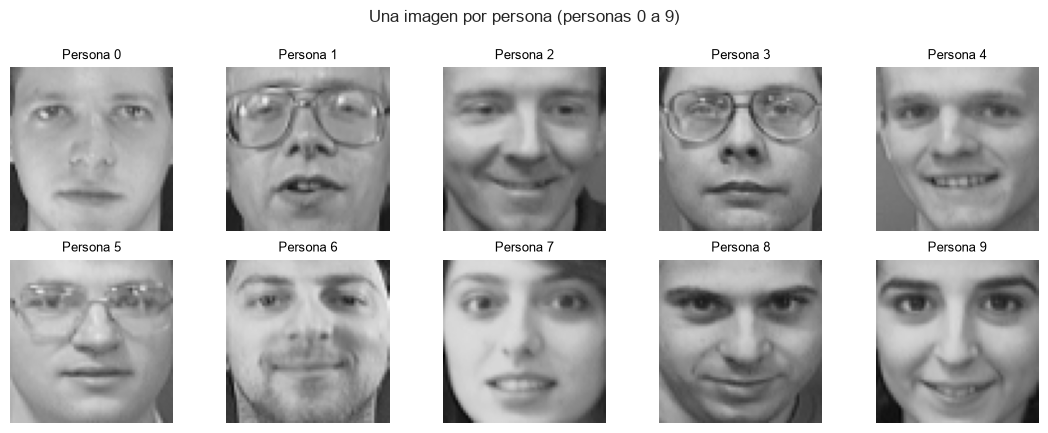

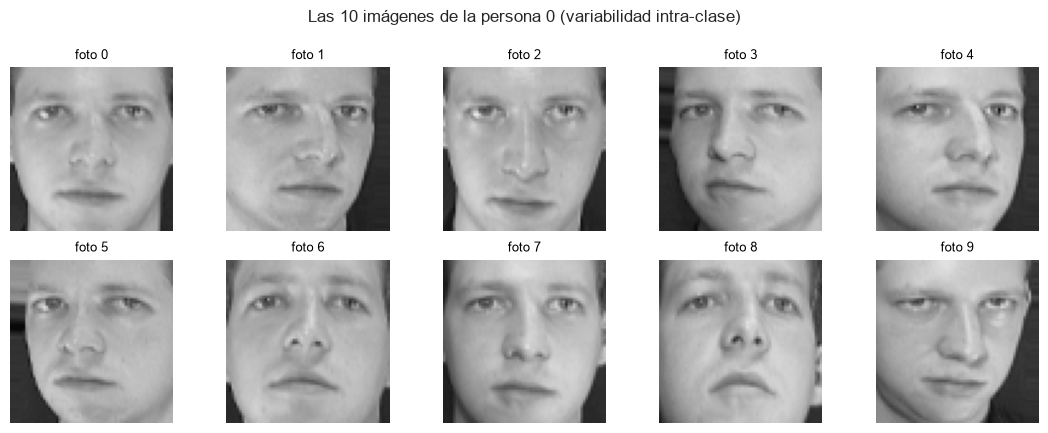

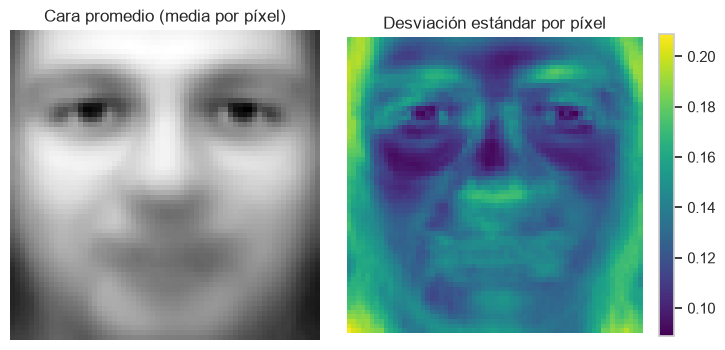

In [3]:
# c) Una imagen por persona (primera foto de cada una de las personas 0 a 9)
primeros_idx = [np.where(y_faces == c)[0][0] for c in range(10)]
mostrar_caras(X_faces[primeros_idx], titulos=[f"Persona {c}" for c in range(10)],
              n_cols=5, titulo_general="Una imagen por persona (personas 0 a 9)")

# Las 10 fotos de una misma persona: muestra la variabilidad intra-clase (pose, gesto, lentes, iluminación)
idx_p0 = np.where(y_faces == 0)[0]
mostrar_caras(X_faces[idx_p0], titulos=[f"foto {k}" for k in range(10)],
              n_cols=5, titulo_general="Las 10 imágenes de la persona 0 (variabilidad intra-clase)")

# Cara promedio de todo el dataset: media píxel a píxel de las 400 imágenes
cara_promedio = X_faces.mean(axis=0)
cara_desv = X_faces.std(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.6))
axes[0].imshow(cara_promedio.reshape(64, 64), cmap="gray")
axes[0].set_title("Cara promedio (media por píxel)")
im = axes[1].imshow(cara_desv.reshape(64, 64), cmap="viridis")
axes[1].set_title("Desviación estándar por píxel")
fig.colorbar(im, ax=axes[1], fraction=0.046)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
# d) División estratificada 75% / 25%
X_train, X_test, y_train, y_test = train_test_split(
    X_faces, y_faces, test_size=0.25, stratify=y_faces, random_state=SEED)

distribucion = pd.DataFrame({"train": np.bincount(y_train), "test": np.bincount(y_test)})
print(f"Entrenamiento: {X_train.shape}   |   Prueba: {X_test.shape}")
print(f"Muestras por clase en train: mín {distribucion.train.min()}, máx {distribucion.train.max()}")
print(f"Muestras por clase en test : mín {distribucion.test.min()}, máx {distribucion.test.max()}")
print(f"Clases presentes en test: {distribucion.test.gt(0).sum()} de 40")

Entrenamiento: (300, 4096)   |   Prueba: (100, 4096)
Muestras por clase en train: mín 7, máx 8
Muestras por clase en test : mín 2, máx 3
Clases presentes en test: 40 de 40


**a) Carga.** El dataset se carga con `fetch_olivetti_faces`; `olivetti.data` entrega las imágenes aplanadas (una fila por imagen), `olivetti.target` la identidad de la persona e `olivetti.images` las mismas imágenes como matrices 64x64.

**b) Descripción.**

| Propiedad | Valor |
|---|---|
| Muestras (imágenes) | 400 |
| Clases (personas) | 40 |
| Muestras por clase | 10 exactamente para cada persona (dataset perfectamente balanceado) |
| Dimensionalidad | 4096 características (64 x 64 píxeles en escala de grises), valores `float32` ya normalizados en [0, 1] |

Es un problema de **alta dimensionalidad y pocas muestras**: hay 4096 variables y sólo 400 observaciones (razón ≈ 0,1), y apenas 10 ejemplos por clase. Esto condiciona todo lo que sigue: los modelos pueden memorizar el entrenamiento con facilidad, las estimaciones de error tienen alta varianza (cada imagen de prueba vale 1 punto porcentual) y la reducción de dimensionalidad (PCA, Parte 2) es muy atractiva.

**c) Visualización.** La primera grilla muestra una foto de cada una de las personas 0 a 9: distintos sexos, edades, con y sin lentes, con y sin barba. La segunda grilla (las 10 fotos de la persona 0) ilustra la **variabilidad intra-clase**: cambios de pose (giro e inclinación de la cabeza), expresión e iluminación, que son justamente lo que un clasificador debe aprender a ignorar. La **cara promedio** es un rostro borroso y simétrico en el que se reconocen ojos, nariz y boca: las estructuras comunes a todas las personas. El mapa de desviación estándar muestra que los píxeles que más varían entre imágenes están en el contorno del rostro, el pelo y la frente (fondo/pelo/piel), mientras que las mejillas y la zona bajo los ojos son las regiones de menor variabilidad; nariz y boca quedan en valores intermedios.

**d) División.** `train_test_split(test_size=0.25, stratify=y, random_state=42)` deja 300 imágenes de entrenamiento y 100 de prueba. Gracias a la estratificación cada persona tiene 7 u 8 imágenes en entrenamiento y 2 o 3 en prueba, y las 40 clases están presentes en ambos conjuntos. Sin `stratify` sería perfectamente posible que alguna persona quedara con 0 o 1 imagen de prueba, lo que haría imposible evaluarla.

__Pregunta 1.2__: Random Forest - Modelo Base (25 puntos)

a) Entrene un modelo `RandomForestClassifier` con los parámetros por defecto de scikit-learn (`n_estimators=100`, etc.) sobre el conjunto de entrenamiento.

b) Realice validación cruzada de 5-folds sólo en el conjunto de entrenamiento. Reporte: Accuracy promedio, Precision, Recall & F1-Score promedio (use `average='weighted'`).

c) Evalúe el modelo base en el conjunto de prueba. Genere y visualice la matriz de confusión.

d) Identifique a las **3 personas (clases) peor clasificadas** (las que presentan mayor cantidad de errores). Para cada una de estas 3 personas, grafique una muestra de sus imágenes reales (máximo 5) junto a las imágenes de las personas con las que fueron erróneamente confundidas (máximo 5). A partir de esto, proponga una hipótesis visual sobre **por qué ocurre esta confusión**.

### Respuesta 1.2:

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, make_scorer)

# Esquema de validación cruzada estratificada que se reutiliza en toda la Parte 1
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# a) Random Forest con los parámetros por defecto (n_estimators=100, max_features='sqrt', max_depth=None, ...)
rf_base = RandomForestClassifier(random_state=SEED, n_jobs=-1)
t_rf_base = cronometrar(rf_base, X_train, y_train)
print(f"RF base entrenado en {t_rf_base:.2f} s")

# b) Validación cruzada de 5 folds SOLO sobre el conjunto de entrenamiento
# precision_weighted se define con zero_division=0: en un fold de 60 imágenes puede haber clases nunca predichas
scoring = {"accuracy": "accuracy",
           "precision": make_scorer(precision_score, average="weighted", zero_division=0),
           "recall": "recall_weighted", "f1": "f1_weighted"}
cv_rf_base = cross_validate(rf_base, X_train, y_train, cv=cv5, scoring=scoring)
tabla_cv = pd.DataFrame({m: cv_rf_base[f"test_{m}"] for m in scoring},
                        index=[f"fold {i + 1}" for i in range(5)])
tabla_cv.loc["promedio"] = tabla_cv.iloc[:5].mean()
tabla_cv.loc["desv. est."] = tabla_cv.iloc[:5].std()
mostrar_tabla(tabla_cv)

RF base entrenado en 0.28 s


,accuracy,precision,recall,f1
fold 1,0.9167,0.9111,0.9167,0.9017
fold 2,0.8833,0.8722,0.8833,0.8711
fold 3,0.9167,0.9417,0.9167,0.9111
fold 4,0.9000,0.8611,0.9000,0.8739
fold 5,0.9000,0.8903,0.9000,0.8822
promedio,0.9033,0.8953,0.9033,0.8880
desv. est.,0.0139,0.0321,0.0139,0.0176


,RF base (test)
accuracy_test,0.9600
precision_w_test,0.9717
recall_w_test,0.9600
f1_w_test,0.9581


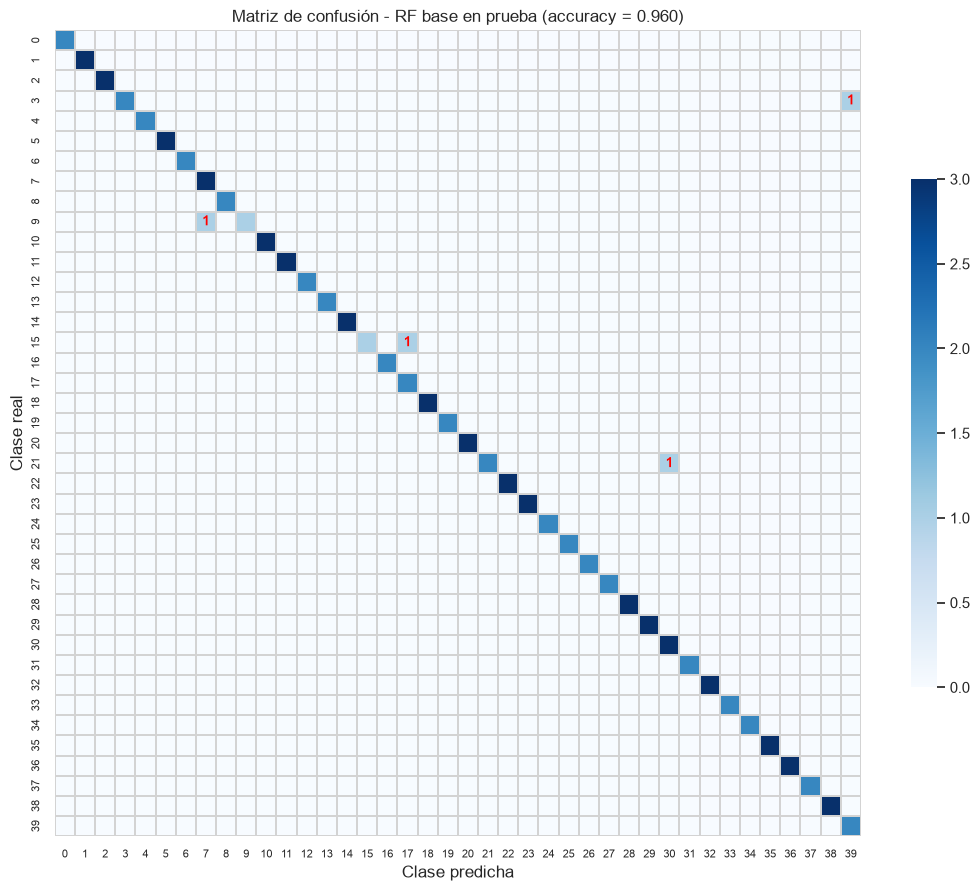

In [6]:
# c) Evaluación en el conjunto de prueba y matriz de confusión
y_pred_rf_base = rf_base.predict(X_test)
metricas_rf_base = {
    "accuracy_test": accuracy_score(y_test, y_pred_rf_base),
    "precision_w_test": precision_score(y_test, y_pred_rf_base, average="weighted", zero_division=0),
    "recall_w_test": recall_score(y_test, y_pred_rf_base, average="weighted"),
    "f1_w_test": f1_score(y_test, y_pred_rf_base, average="weighted"),
}
resultados["RF base"] = {**metricas_rf_base, "accuracy_cv": tabla_cv.loc["promedio", "accuracy"],
                         "tiempo_entrenamiento_s": t_rf_base,
                         "tiempo_prediccion_s": tiempo_prediccion(rf_base.set_params(n_jobs=1).predict, X_test)}
rf_base.set_params(n_jobs=-1)   # con sólo 100 imágenes, predecir con muchos hilos es más lento (sobrecarga): se mide con 1
mostrar_tabla(pd.Series(metricas_rf_base, name="RF base (test)").to_frame())

cm_rf = confusion_matrix(y_test, y_pred_rf_base, labels=list(range(40)))
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(cm_rf, cmap="Blues", square=True, cbar_kws={"shrink": 0.6}, linewidths=0.3,
            linecolor="lightgray", xticklabels=range(40), yticklabels=range(40), ax=ax)
ax.tick_params(axis="both", labelsize=8)
# Se anotan en rojo sólo las celdas fuera de la diagonal (errores)
for i, j in zip(*np.where((cm_rf > 0) & ~np.eye(40, dtype=bool))):
    ax.text(j + 0.5, i + 0.5, cm_rf[i, j], ha="center", va="center", color="red", fontsize=9, fontweight="bold")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title(f"Matriz de confusión - RF base en prueba (accuracy = {metricas_rf_base['accuracy_test']:.3f})")
plt.show()

Clases con al menos un error en prueba:


,clase,n_test,errores,recall
0,9,2,1,0.500
1,15,2,1,0.500
2,3,3,1,0.667
3,21,3,1,0.667



Las 3 personas peor clasificadas: [9, 15, 3]


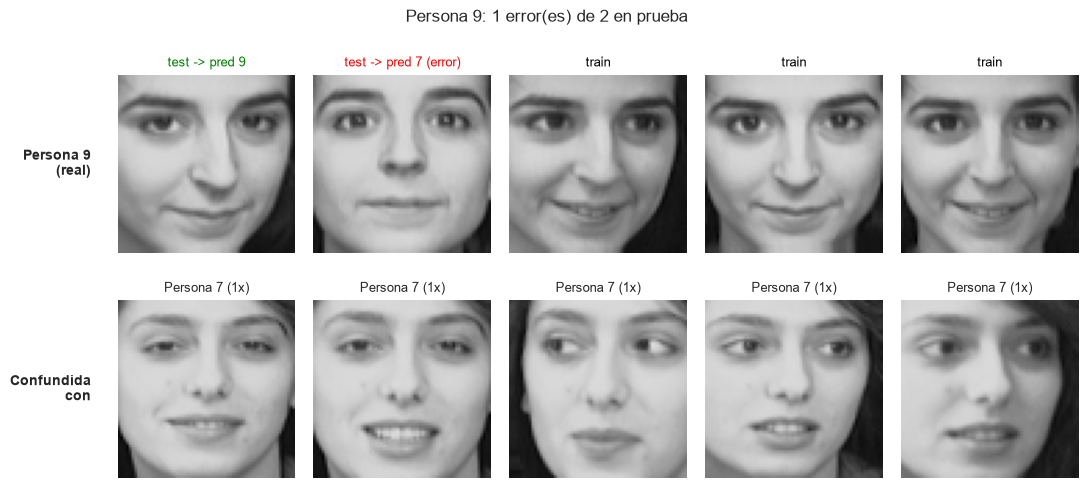

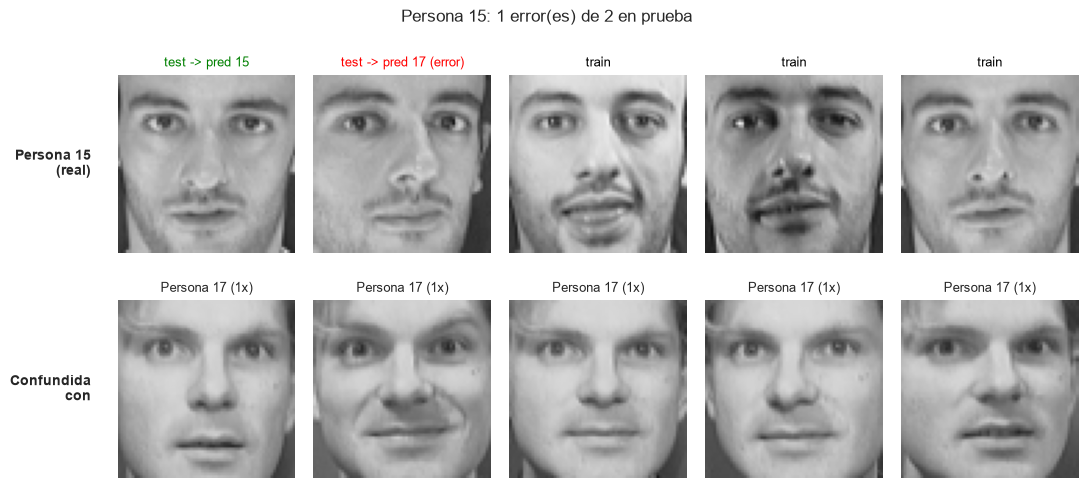

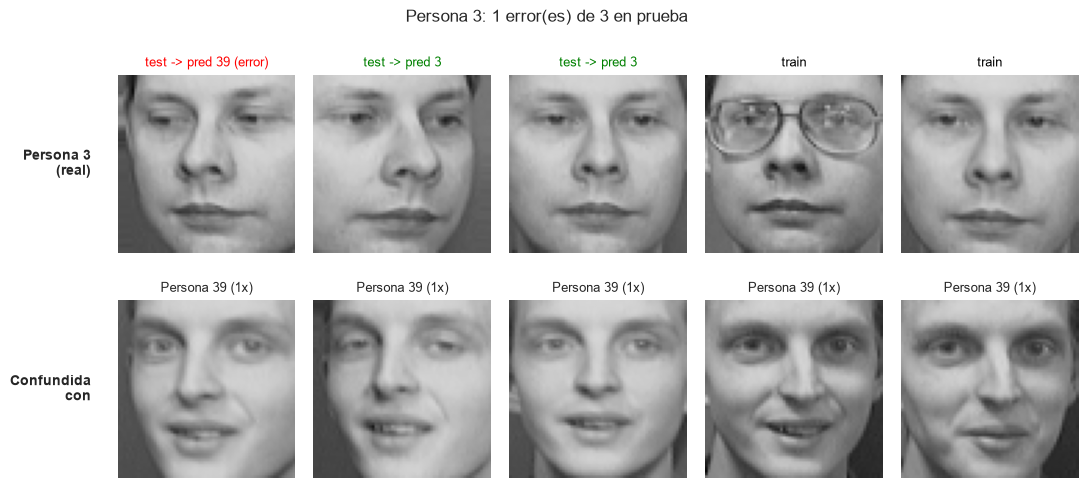

In [7]:
# d) Las 3 personas peor clasificadas (mayor número de errores en prueba)
n_test_clase = cm_rf.sum(axis=1)
errores_clase = n_test_clase - np.diag(cm_rf)
tabla_errores = pd.DataFrame({"clase": range(40), "n_test": n_test_clase, "errores": errores_clase,
                              "recall": np.diag(cm_rf) / n_test_clase})
# Orden: más errores primero; en caso de empate, menor recall y luego menor índice de clase
tabla_errores = tabla_errores.sort_values(["errores", "recall", "clase"],
                                          ascending=[False, True, True]).reset_index(drop=True)
print("Clases con al menos un error en prueba:")
mostrar_tabla(tabla_errores[tabla_errores.errores > 0], 3)
peores_clases = tabla_errores.clase.head(3).tolist()
print("\nLas 3 personas peor clasificadas:", peores_clases)


def graficar_confusiones(clase, cm, X_te, y_te, y_pr, X_tr, y_tr, max_img=5):
    """Fila superior: imágenes reales de `clase` (primero las de prueba, con su predicción).
    Fila inferior: imágenes (de entrenamiento) de las personas con las que fue confundida."""
    imgs_a, tit_a, col_a = [], [], []
    for i in np.where(y_te == clase)[0]:
        correcto = y_pr[i] == clase
        imgs_a.append(X_te[i])
        tit_a.append(f"test -> pred {y_pr[i]}" + ("" if correcto else " (error)"))
        col_a.append("green" if correcto else "red")
    for i in np.where(y_tr == clase)[0][: max_img - len(imgs_a)]:
        imgs_a.append(X_tr[i]); tit_a.append("train"); col_a.append("black")

    confundidas = [(j, cm[clase, j]) for j in np.argsort(-cm[clase]) if j != clase and cm[clase, j] > 0]
    if not confundidas:
        print(f"La persona {clase} no tiene errores en prueba: nada que graficar.")
        return
    por_persona = int(np.ceil(max_img / len(confundidas)))
    imgs_b, tit_b = [], []
    for j, veces in confundidas:
        for i in np.where(y_tr == j)[0][:por_persona]:
            if len(imgs_b) < max_img:
                imgs_b.append(X_tr[i]); tit_b.append(f"Persona {j} ({veces}x)")

    fig, axes = plt.subplots(2, max_img, figsize=(max_img * 2.2, 5.2))
    for ax in axes.ravel():
        ax.axis("off")
    for k, (img, t, c) in enumerate(zip(imgs_a, tit_a, col_a)):
        axes[0, k].imshow(img.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
        axes[0, k].set_title(t, fontsize=9, color=c)
    for k, (img, t) in enumerate(zip(imgs_b, tit_b)):
        axes[1, k].imshow(img.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
        axes[1, k].set_title(t, fontsize=9)
    axes[0, 0].text(-0.15, 0.5, f"Persona {clase}\n(real)", transform=axes[0, 0].transAxes,
                    ha="right", va="center", fontsize=10, fontweight="bold")
    axes[1, 0].text(-0.15, 0.5, "Confundida\ncon", transform=axes[1, 0].transAxes,
                    ha="right", va="center", fontsize=10, fontweight="bold")
    fig.suptitle(f"Persona {clase}: {int(cm[clase].sum() - cm[clase, clase])} error(es) de {int(cm[clase].sum())} en prueba", fontsize=12)
    plt.tight_layout()
    plt.show()


for c in peores_clases:
    graficar_confusiones(c, cm_rf, X_test, y_test, y_pred_rf_base, X_train, y_train)

In [8]:
# Complemento: con sólo 100 imágenes de prueba (4 errores) la elección de las "3 peores" es frágil (empate a 1 error).
# Como contraste más estable se repite el análisis con las predicciones de validación cruzada sobre el entrenamiento.
from sklearn.model_selection import cross_val_predict

y_pred_cv = cross_val_predict(rf_base, X_train, y_train, cv=cv5)
cm_cv = confusion_matrix(y_train, y_pred_cv, labels=list(range(40)))
errores_cv = cm_cv.sum(axis=1) - np.diag(cm_cv)
tabla_cv_err = pd.DataFrame({"clase": range(40), "n_train": cm_cv.sum(axis=1), "errores_cv": errores_cv})
tabla_cv_err = tabla_cv_err.sort_values(["errores_cv", "clase"], ascending=[False, True]).reset_index(drop=True)
print(f"Errores en validación cruzada (300 imágenes): {int(errores_cv.sum())}")
print("Personas con más errores en validación cruzada:")
mostrar_tabla(tabla_cv_err.head(6), 0)
for c in tabla_cv_err.clase.head(3):
    confundidas_cv = {int(j): int(cm_cv[c, j]) for j in np.argsort(-cm_cv[c]) if j != c and cm_cv[c, j] > 0}
    print(f"  Persona {c}: confundida con {confundidas_cv}")

Errores en validación cruzada (300 imágenes): 29
Personas con más errores en validación cruzada:


,clase,n_train,errores_cv
0,12,8,3
1,30,7,3
2,39,8,3
3,3,7,2
4,4,8,2
5,15,8,2


  Persona 12: confundida con {3: 1, 13: 1, 39: 1}
  Persona 30: confundida con {33: 2, 20: 1}
  Persona 39: confundida con {8: 2, 5: 1}


**a) Modelo base.** `RandomForestClassifier(random_state=42)` con sus valores por defecto (100 árboles, `max_features='sqrt'` = 64 píxeles candidatos por split, árboles sin límite de profundidad, `min_samples_leaf=1`, criterio Gini). Entrena en una fracción de segundo.

**b) Validación cruzada (5 folds estratificados, sólo sobre entrenamiento).**

| Métrica (promedio ponderado) | Media | Desv. est. |
|---|---|---|
| Accuracy | 0,903 | 0,014 |
| Precision (weighted) | 0,895 | 0,032 |
| Recall (weighted) | 0,903 | 0,014 |
| F1-score (weighted) | 0,888 | 0,018 |

El recall ponderado por soporte coincide siempre con el accuracy (es una identidad algebraica, no una consecuencia del balance de clases). El F1 es algo menor que el accuracy porque en cada fold hay un puñado de clases con recall 0 o precision 0 (con sólo 1-2 imágenes por clase en cada fold de validación, un único error anula la métrica de esa clase).

**c) Evaluación en prueba.** Accuracy = **0,96** (4 errores en 100 imágenes), precision ponderada 0,972, recall 0,960, F1 0,958. El resultado es mejor que el de validación cruzada por dos motivos: en prueba el modelo se entrenó con las 300 imágenes (7-8 por persona) en lugar de 240 (5-7 por persona), y con tan pocos ejemplos por clase cada imagen adicional importa; y el conjunto de prueba tiene sólo 100 imágenes, de modo que su accuracy tiene una incertidumbre de ± 3-4 puntos (intervalo binomial), que cubre de sobra la diferencia con el 0,903 de la validación cruzada. La matriz de confusión es casi perfectamente diagonal; los 4 errores (en rojo) son todos confusiones distintas entre pares de personas: 9 → 7, 15 → 17, 3 → 39 y 21 → 30.

**d) Las 3 personas peor clasificadas.** Cuatro personas (9, 15, 3 y 21) tienen exactamente 1 error, así que hay empate en "cantidad de errores". Se desempató por recall (las personas 9 y 15 fallaron 1 de 2 imágenes, recall 0,5; las personas 3 y 21 fallaron 1 de 3, recall 0,67) y luego por índice, quedando **9, 15 y 3**.

* **Persona 9, confundida con la 7:** ambas son mujeres jóvenes de pelo oscuro recogido hacia atrás, con forma de rostro, cejas y tono de piel muy parecidos. Las fotos de entrenamiento de la persona 9 son mayoritariamente sonrientes y con la cabeza algo inclinada; la imagen que falló es frontal y con expresión neutra, que se parece más a las fotos frontales de la persona 7 que a las propias fotos de entrenamiento de la 9.
* **Persona 15, confundida con la 17:** dos hombres jóvenes de pelo corto, cejas marcadas, misma forma ovalada del rostro y, sobre todo, la misma iluminación y fondo. Las fotos de entrenamiento de la 15 incluyen varias con la boca abierta, el ceño fruncido o una iluminación más dura; la imagen que falló es la más neutra y uniformemente iluminada, y en los píxeles crudos queda más cerca de las fotos igualmente neutras de la 17 (el bigote, un rasgo pequeño en 64x64, pesa poco frente a la frente, el pelo y el contorno).
* **Persona 3, confundida con la 39:** la mirada baja es común a varias fotos de la persona 3 (también a las dos de prueba bien clasificadas), así que no es eso lo que la delata; lo que distingue a la imagen mal clasificada es que la cabeza está **girada** y la iluminación es más oscura y contrastada, con una sombra marcada bajo la nariz. Además, la persona 3 aparece en entrenamiento a veces con lentes y a veces sin ellos, lo que aumenta su variabilidad intra-clase. La persona 39 comparte la línea del cabello, la frente amplia, la forma de la mandíbula y el tono general de la piel, y varias de sus fotos tienen esa misma iluminación lateral.

**Hipótesis visual.** El Random Forest trabaja sobre **intensidades de píxeles individuales**, sin ninguna noción de geometría: una ceja desplazada tres píxeles por un giro de cabeza cae en otras variables. Por eso las confusiones ocurren entre personas con **apariencia global similar** (sexo, tono de piel, peinado, forma del rostro, misma iluminación) y se disparan cuando la imagen de prueba tiene una **pose o expresión que no está representada en las 7-8 fotos de entrenamiento** de esa persona. En esos casos, la imagen queda, píxel a píxel, más cerca de una foto de otra persona con la misma pose que de las fotos de la persona correcta.

*Advertencia sobre la selección:* con sólo 4 errores en prueba, la lista de las "3 peores" depende de un desempate y es poco estable. La celda complementaria repite el análisis con las predicciones de validación cruzada sobre las 300 imágenes de entrenamiento (29 errores): allí las personas con más errores son otras (la 12, la 30 y la 39, con 3 errores cada una), lo que confirma que las confusiones no se concentran en un par de personas "difíciles" sino que se reparten entre varios pares de rostros parecidos, y que la 39 reaparece como clase problemática.

__Pregunta 1.3__: Random Forest - Optimización de Hiperparámetros (30 puntos)

a) Use `GridSearchCV` con validación cruzada de 5-folds para encontrar los mejores hiperparámetros para `RandomForestClassifier`. Enfoque su búsqueda en:  `n_estimators`: [50, 100, 200],  `max_depth`: [None, 10, 20], `min_samples_leaf`: [1, 2, 4] & `criterion`: ['gini', 'entropy'].

b) Reporte los mejores hiperparámetros encontrados y el accuracy de validación cruzada obtenido con ellos.

c) Grafique curvas de validación (usando `validation_curve`) para el hiperparámetro `n_estimators`, probando un rango más amplio (ej. de 10 a 300 con saltos de 20). ¿A partir de cuántos árboles aproximadamente diría que el modelo se estabiliza? **¿por qué se estabiliza?**

### Respuesta 1.3:

In [9]:
from sklearn.model_selection import GridSearchCV, validation_curve

# a) Búsqueda en grilla con validación cruzada de 5 folds (3 x 3 x 3 x 2 = 54 combinaciones)
param_grid_rf = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 4],
    "criterion": ["gini", "entropy"],
}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=SEED, n_jobs=1), param_grid_rf,
                       cv=cv5, scoring="accuracy", n_jobs=-1, return_train_score=True)
inicio = time.perf_counter()
grid_rf.fit(X_train, y_train)
t_grid_rf = time.perf_counter() - inicio
n_comb = len(grid_rf.cv_results_["params"])
print(f"{n_comb} combinaciones x 5 folds = {n_comb * 5} ajustes en {t_grid_rf:.1f} s")

# b) Mejores hiperparámetros y accuracy de validación cruzada
print("Mejores hiperparámetros:", grid_rf.best_params_)
print(f"Accuracy CV (5 folds) con los mejores hiperparámetros: {grid_rf.best_score_:.4f}")

rf_best = grid_rf.best_estimator_      # refit=True: ya reentrenado con TODO el conjunto de entrenamiento
# Para comparar tiempos en igualdad de condiciones se reentrena el mismo modelo (misma semilla) usando todos los núcleos
rf_best.set_params(n_jobs=-1)
t_rf_best = cronometrar(rf_best, X_train, y_train)
print(f"Tiempo de entrenamiento del RF optimizado: {t_rf_best:.2f} s con n_jobs=-1 "
      f"(refit interno del GridSearch con 1 núcleo: {grid_rf.refit_time_:.2f} s)")
y_pred_rf_best = rf_best.predict(X_test)
acc_rf_best = accuracy_score(y_test, y_pred_rf_best)
print(f"Accuracy en prueba del RF optimizado: {acc_rf_best:.4f}  (RF base: {metricas_rf_base['accuracy_test']:.4f})")
resultados["RF optimizado"] = {
    "accuracy_test": acc_rf_best, "accuracy_cv": grid_rf.best_score_,
    "precision_w_test": precision_score(y_test, y_pred_rf_best, average="weighted", zero_division=0),
    "recall_w_test": recall_score(y_test, y_pred_rf_best, average="weighted"),
    "f1_w_test": f1_score(y_test, y_pred_rf_best, average="weighted"),
    "tiempo_entrenamiento_s": t_rf_best,
    "tiempo_prediccion_s": tiempo_prediccion(rf_best.set_params(n_jobs=1).predict, X_test),   # 1 hilo (ver 1.2)
    "tiempo_busqueda_s": t_grid_rf,
}
rf_best.set_params(n_jobs=-1)

# Las 10 mejores combinaciones y el efecto marginal de cada hiperparámetro
cols = ["param_n_estimators", "param_max_depth", "param_min_samples_leaf", "param_criterion",
        "mean_test_score", "std_test_score", "mean_train_score", "rank_test_score"]
res_grid = pd.DataFrame(grid_rf.cv_results_)[cols].sort_values("rank_test_score")
print("\nTop 10 combinaciones:")
mostrar_tabla(res_grid.head(10).reset_index(drop=True))
print(f"\nAccuracy de ENTRENAMIENTO (media CV) de las 54 combinaciones: mín {res_grid.mean_train_score.min():.4f}, "
      f"máx {res_grid.mean_train_score.max():.4f}")
print("Combinaciones con accuracy de entrenamiento < 1:",
      int((res_grid.mean_train_score < 1).sum()), "(todas con max_depth=10)" if
      (res_grid.loc[res_grid.mean_train_score < 1, "param_max_depth"] == 10).all() else "")
print("\nAccuracy CV promedio según el valor de cada hiperparámetro (efecto marginal):")
for p in param_grid_rf:
    etiquetas = res_grid[f"param_{p}"].map(lambda v: "None" if pd.isna(v) else str(v))
    marginal = res_grid.groupby(etiquetas)["mean_test_score"].mean().round(4)
    print(f"  {p:17s}", marginal.to_dict())

54 combinaciones x 5 folds = 270 ajustes en 126.3 s
Mejores hiperparámetros: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Accuracy CV (5 folds) con los mejores hiperparámetros: 0.9200


Tiempo de entrenamiento del RF optimizado: 1.09 s con n_jobs=-1 (refit interno del GridSearch con 1 núcleo: 7.40 s)
Accuracy en prueba del RF optimizado: 0.9700  (RF base: 0.9600)



Top 10 combinaciones:


,param_n_estimators,param_max_depth,param_min_samples_leaf,param_criterion,mean_test_score,std_test_score,mean_train_score,rank_test_score
0,200,None,1,gini,0.9200,0.0163,1.0,1
1,100,None,1,gini,0.9033,0.0125,1.0,2
2,200,20,2,gini,0.8967,0.0163,1.0,3
3,100,None,2,gini,0.8933,0.0082,1.0,4
4,200,20,1,gini,0.8933,0.0170,1.0,4
5,200,None,1,entropy,0.8933,0.0389,1.0,4
6,200,20,1,entropy,0.8933,0.0389,1.0,4
7,200,10,1,entropy,0.8933,0.0389,1.0,4
8,200,None,2,gini,0.8900,0.0082,1.0,9
9,50,None,1,gini,0.8867,0.0323,1.0,10



Accuracy de ENTRENAMIENTO (media CV) de las 54 combinaciones: mín 0.9733, máx 1.0000
Combinaciones con accuracy de entrenamiento < 1: 9 (todas con max_depth=10)

Accuracy CV promedio según el valor de cada hiperparámetro (efecto marginal):
  n_estimators      {'100': 0.8589, '200': 0.8722, '50': 0.8369}
  max_depth         {'10': 0.825, '20': 0.8693, 'None': 0.8737}
  min_samples_leaf  {'1': 0.8683, '2': 0.8604, '4': 0.8393}
  criterion         {'entropy': 0.8674, 'gini': 0.8446}


n_estimators,10,30,50,70,90,110,130,150,170,190,210,230,250,270,290
train_mean,0.998,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
val_mean,0.710,0.873,0.887,0.897,0.907,0.917,0.923,0.923,0.920,0.917,0.920,0.927,0.927,0.927,0.920
val_std,0.017,0.023,0.032,0.016,0.020,0.026,0.023,0.017,0.022,0.018,0.019,0.013,0.013,0.013,0.012


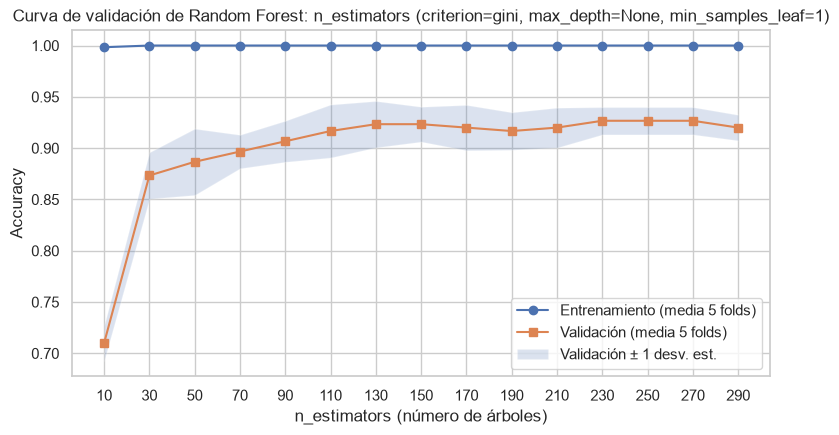

Máximo accuracy de validación: 0.9267. Primer n_estimators dentro de 1 punto del máximo: 110


In [10]:
# c) Curva de validación para n_estimators (resto de hiperparámetros fijos en los mejores valores)
rango_arboles = np.arange(10, 301, 20)          # 10, 30, 50, ..., 290
params_fijos = {k: v for k, v in grid_rf.best_params_.items() if k != "n_estimators"}
sc_train, sc_val = validation_curve(
    RandomForestClassifier(random_state=SEED, n_jobs=1, **params_fijos), X_train, y_train,
    param_name="n_estimators", param_range=rango_arboles, cv=cv5, scoring="accuracy", n_jobs=-1)

curva = pd.DataFrame({"n_estimators": rango_arboles,
                      "train_mean": sc_train.mean(axis=1), "val_mean": sc_val.mean(axis=1),
                      "val_std": sc_val.std(axis=1)})
mostrar_tabla(curva.set_index("n_estimators").T, 3)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(rango_arboles, curva.train_mean, "o-", label="Entrenamiento (media 5 folds)")
ax.plot(rango_arboles, curva.val_mean, "s-", label="Validación (media 5 folds)")
ax.fill_between(rango_arboles, curva.val_mean - curva.val_std, curva.val_mean + curva.val_std,
                alpha=0.2, label="Validación ± 1 desv. est.")
ax.set_xlabel("n_estimators (número de árboles)")
ax.set_ylabel("Accuracy")
ax.set_title("Curva de validación de Random Forest: n_estimators "
             f"(criterion={params_fijos['criterion']}, max_depth={params_fijos['max_depth']}, "
             f"min_samples_leaf={params_fijos['min_samples_leaf']})")
ax.set_xticks(rango_arboles)
ax.legend(loc="lower right")
plt.show()

maximo = curva.val_mean.max()
umbral = maximo - 0.01
estable_desde = int(curva.loc[curva.val_mean >= umbral, "n_estimators"].iloc[0])
print(f"Máximo accuracy de validación: {maximo:.4f}. Primer n_estimators dentro de 1 punto del máximo: {estable_desde}")

**a) y b) GridSearchCV.** Se evaluaron las 54 combinaciones (3 x 3 x 3 x 2) con la misma validación cruzada estratificada de 5 folds, es decir, 270 ajustes, en uno o dos minutos gracias a la paralelización (el tiempo exacto depende de la máquina y de su carga; aparece impreso en la salida).

* **Mejores hiperparámetros:** `criterion='gini'`, `max_depth=None`, `min_samples_leaf=1`, `n_estimators=200`.
* **Accuracy de validación cruzada con ellos: 0,920** (± 0,016). En prueba este modelo alcanza **0,97** (3 errores), frente al 0,96 del modelo base.

Los efectos marginales son coherentes con la teoría: a más árboles mejor (0,837 → 0,859 → 0,872 al pasar de 50 a 100 a 200), los árboles sin restricciones son mejores que los podados (`max_depth=None` ≈ 20 > 10, y `min_samples_leaf=1` > 2 > 4). Con sólo 7-8 imágenes por clase, cualquier restricción al crecimiento del árbol impide aislar las clases; la regularización la aporta el promedio del bosque, no la poda. El criterio `entropy` es ligeramente mejor en promedio, pero la mejor combinación individual usa `gini`; las diferencias entre las primeras combinaciones (0,893-0,920) son del orden de la desviación estándar entre folds (0,01-0,04), de modo que no deben sobreinterpretarse. Las combinaciones sin límite de profundidad (o con `max_depth=20`) tienen accuracy de entrenamiento 1,0 (cada árbol memoriza su muestra bootstrap); sólo nueve combinaciones, todas con `max_depth=10` (que limita la profundidad a la mitad de las 18 que usan ese valor), quedan por debajo, con un mínimo de 0,973.

**c) Curva de validación para `n_estimators`.** Con el resto de hiperparámetros fijos en los mejores valores, el accuracy de validación pasa de 0,71 con 10 árboles a 0,87 con 30, 0,91 con 90, 0,92 con 110 y 0,923 con 130, y desde ahí oscila entre 0,917 y 0,927 hasta 290 árboles, sin tendencia. La banda de ± 1 desviación estándar (≈ 0,02) cubre toda esa oscilación. El accuracy de entrenamiento es 1,0 desde 30 árboles.

**El modelo se estabiliza aproximadamente a partir de 110-130 árboles.**

**¿Por qué se estabiliza?** La predicción de un Random Forest es el voto mayoritario de árboles entrenados de forma aleatoria pero idéntica en distribución. Agregar árboles no cambia el sesgo del modelo (cada árbol sigue siendo igual de expresivo); lo que hace es **reducir la varianza del promedio**: la varianza de la media de B predictores con correlación ρ y varianza σ² es ρσ² + (1 − ρ)σ²/B. El segundo término decae como 1/B y, pasados unos ~100 árboles, ya es despreciable frente al primero, que es un piso que no depende de B. Esto es coherente con el teorema de convergencia de Breiman (2001): el error de generalización del bosque converge casi seguramente a un límite cuando B → ∞, por lo que un Random Forest **no sobreajusta por añadir árboles**, simplemente deja de mejorar. En la práctica, a partir de ese punto cada árbol nuevo repite información que el conjunto ya tiene (la votación ya es estable y un árbol más rara vez cambia la mayoría), y sólo añade costo computacional. La pequeña oscilación residual (± 0,005) no refleja cambios reales del modelo: los folds son fijos, así que proviene de la aleatoriedad Monte Carlo de los propios bosques (bootstrap y selección de píxeles) y de la granularidad de la métrica, que con 300 imágenes se mueve en saltos de 1/300 ≈ 0,003.

__Pregunta 1.4__: Random Forest - Importancia de Features y OOB (25 puntos)

a) Entrene un nuevo Random Forest con los mejores hiperparámetros encontrados, pero esta vez active el `oob_score=True`.

b) Reporte el OOB score. Compárelo con el accuracy de validación cruzada (de 1.3.b) y el accuracy en el conjunto de prueba. ¿Qué ventajas prácticas ofrece el OOB score?

c) Extraiga la importancia de características (`feature_importances_`) del modelo optimizado.

d) Visualice las 4096 importancias como una imagen de 64x64 (usando `imshow`). ¿Qué patrones observa? ¿Dónde se concentran los píxeles más importantes para la clasificación?

### Respuesta 1.4:

In [11]:
# a) Random Forest con los mejores hiperparámetros y oob_score=True
rf_oob = RandomForestClassifier(**grid_rf.best_params_, oob_score=True, random_state=SEED, n_jobs=-1)
t_rf_oob = cronometrar(rf_oob, X_train, y_train)
acc_rf_oob_test = accuracy_score(y_test, rf_oob.predict(X_test))

# b) OOB score vs. accuracy de validación cruzada vs. accuracy en prueba
comparacion_oob = pd.Series({
    "OOB score (muestras fuera de la bolsa)": rf_oob.oob_score_,
    "Accuracy CV 5 folds (1.3.b)": grid_rf.best_score_,
    "Accuracy en prueba": acc_rf_oob_test,
}, name="accuracy")
mostrar_tabla(comparacion_oob.to_frame())
print(f"Tiempo de entrenamiento: {t_rf_oob:.2f} s (un solo ajuste, sin necesidad de 5 reentrenamientos)")

,accuracy
OOB score (muestras fuera de la bolsa),0.91
Accuracy CV 5 folds (1.3.b),0.92
Accuracy en prueba,0.97


Tiempo de entrenamiento: 1.30 s (un solo ajuste, sin necesidad de 5 reentrenamientos)


Suma de importancias: 1.000
Píxeles con importancia exactamente 0 (nunca usados en un split): 219 de 4096 (5.3%)
El 10% de píxeles más importantes acumula el 31.6% de la importancia total
Top 10 píxeles (fila, columna, importancia): [(17, 11, 0.002), (10, 20, 0.0019), (0, 24, 0.0016), (2, 9, 0.0016), (10, 22, 0.0016), (0, 20, 0.0016), (15, 10, 0.0016), (30, 18, 0.0016), (0, 22, 0.0016), (9, 8, 0.0015)]


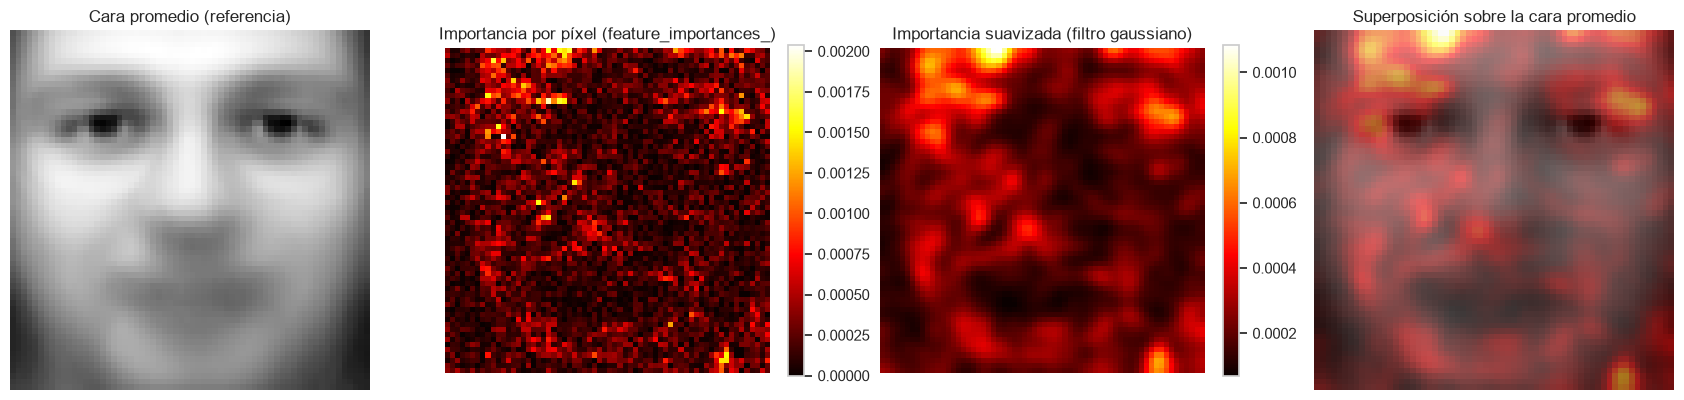

,importancia acumulada
tercio superior (filas 0-20),0.420
tercio medio (filas 21-42),0.297
tercio inferior (filas 43-63),0.283
tercio izquierdo (cols 0-20),0.372
tercio central (cols 21-42),0.296
tercio derecho (cols 43-63),0.333


In [12]:
# c) Importancia de características del modelo optimizado
importancias = rf_oob.feature_importances_
print(f"Suma de importancias: {importancias.sum():.3f}")
print(f"Píxeles con importancia exactamente 0 (nunca usados en un split): {(importancias == 0).sum()} de 4096 "
      f"({100 * (importancias == 0).mean():.1f}%)")
orden = np.argsort(importancias)[::-1]
print(f"El 10% de píxeles más importantes acumula el {100 * importancias[orden[:410]].sum():.1f}% de la importancia total")
top10 = [(int(i // 64), int(i % 64), round(float(importancias[i]), 4)) for i in orden[:10]]
print("Top 10 píxeles (fila, columna, importancia):", top10)

# d) Visualización de las 4096 importancias como imagen 64x64
mapa = importancias.reshape(64, 64)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
axes[0].imshow(cara_promedio.reshape(64, 64), cmap="gray")
axes[0].set_title("Cara promedio (referencia)")
im1 = axes[1].imshow(mapa, cmap="hot")
axes[1].set_title("Importancia por píxel (feature_importances_)")
fig.colorbar(im1, ax=axes[1], fraction=0.046)
im2 = axes[2].imshow(gaussian_filter(mapa, sigma=1.5), cmap="hot")
axes[2].set_title("Importancia suavizada (filtro gaussiano)")
fig.colorbar(im2, ax=axes[2], fraction=0.046)
axes[3].imshow(cara_promedio.reshape(64, 64), cmap="gray")
axes[3].imshow(gaussian_filter(mapa, sigma=1.5), cmap="hot", alpha=0.55)
axes[3].set_title("Superposición sobre la cara promedio")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# Importancia acumulada por bandas horizontales y verticales de la imagen
bandas_h = {"tercio superior (filas 0-20)": mapa[:21].sum(), "tercio medio (filas 21-42)": mapa[21:43].sum(),
            "tercio inferior (filas 43-63)": mapa[43:].sum()}
bandas_v = {"tercio izquierdo (cols 0-20)": mapa[:, :21].sum(), "tercio central (cols 21-42)": mapa[:, 21:43].sum(),
            "tercio derecho (cols 43-63)": mapa[:, 43:].sum()}
mostrar_tabla(pd.DataFrame({"importancia acumulada": {**bandas_h, **bandas_v}}), 3)

**a) y b) OOB score.** Reentrenando el modelo con los mejores hiperparámetros y `oob_score=True`:

| Estimación | Accuracy |
|---|---|
| OOB score | 0,910 |
| Validación cruzada 5 folds (1.3.b) | 0,920 |
| Conjunto de prueba | 0,970 |

El OOB score está muy cerca del accuracy de validación cruzada (diferencia de 1 punto, es decir, 3 imágenes de 300) y es ligeramente más pesimista. La razón es que cada muestra OOB es votada sólo por los árboles que no la incluyeron en su bootstrap, en promedio el 37 % de los 200 árboles (≈ 74 árboles): se evalúa, en la práctica, un bosque más pequeño y por tanto algo peor (la curva de validación de 1.3 muestra que con ~70 árboles el accuracy es unos 2 puntos menor que con ~200). En cuanto a los datos vistos por cada árbol, el OOB no está en desventaja: cada árbol usa ~63 % de las 300 imágenes (≈ 190 distintas), más que el ~63 % de las 240 de cada fold de la validación cruzada. El accuracy de prueba es mayor que ambas estimaciones porque ese modelo usa las 300 imágenes de entrenamiento y porque el conjunto de prueba, con 100 imágenes, tiene una incertidumbre grande (un error = 1 punto; el intervalo binomial de 0,97 con n = 100 abarca aproximadamente 0,92-0,99), así que las tres cifras son compatibles entre sí.

**Ventajas prácticas del OOB score:** (1) es **gratis**: se obtiene del mismo entrenamiento, sin reentrenar 5 veces como la validación cruzada (un solo ajuste frente a los cinco de la validación cruzada); (2) no exige reservar datos, lo que es valioso con datasets pequeños como éste (cada imagen cuenta); (3) es una estimación honesta del error de generalización, porque cada predicción OOB proviene de árboles que nunca vieron esa muestra (con un ligero sesgo pesimista, el ya comentado, que se reduce al aumentar el número de árboles); (4) permite monitorear el error mientras se agregan árboles y comparar hiperparámetros de forma barata; y (5) se obtiene con los mismos árboles que forman el modelo final, entrenados sobre el conjunto completo, en lugar de con modelos distintos ajustados sobre folds más pequeños.

**c) y d) Importancia de características.** Las 4096 importancias (impureza Gini acumulada por píxel, normalizadas a suma 1) se visualizan como imagen 64x64. Observaciones:

* La importancia está **muy repartida**: el píxel más importante aporta sólo 0,2 % del total y el 10 % de píxeles más importantes acumula el 31,6 %. Esto es consecuencia de la redundancia: los píxeles vecinos están fuertemente correlacionados y, como cada split elige entre 64 píxeles aleatorios, árboles distintos usan píxeles distintos pero equivalentes, de modo que la importancia se reparte entre ellos. Sólo 219 píxeles (5,3 %) nunca se usaron en un split.
* Los píxeles más importantes se **concentran en el tercio superior de la imagen** (42 % de la importancia total frente a 30 % y 28 % de los tercios medio e inferior): la **línea del cabello y la frente**, las **sienes** y la zona exterior de las cejas, y las **esquinas superiores**, donde el contraste pelo/fondo codifica el peinado, el volumen del cabello y la forma de la cabeza. Los ojos en sí (pupilas) aportan poco: lo importante es su entorno (cejas, sienes, puente de la nariz). También aparecen focos en los **bordes laterales del rostro** (contorno de las mejillas y orejas) y en la esquina inferior derecha (cuello/hombro). Hay una leve asimetría izquierda/derecha (37 % frente a 33 % de la importancia), atribuible a la iluminación predominantemente lateral de las fotos, que hace más informativo un lado del rostro. En la imagen suavizada y en la superposición sobre la cara promedio se aprecia que las zonas interiores de mejillas y la boca aportan poco.
* Interpretación: para distinguir *identidades*, el bosque usa rasgos relativamente **estables ante cambios de expresión**, como el peinado, la forma de la frente, la posición y forma de cejas y ojos, el contorno del rostro y la presencia de lentes (región de los ojos). La boca y las mejillas, que cambian mucho al sonreír, son menos útiles. Esto es coherente con el mapa de desviación estándar de la pregunta 1.1: las regiones de mayor variabilidad total entre imágenes (pelo, contorno, frente) son también las que el bosque encuentra más discriminantes. La varianza total mezcla variabilidad entre personas y variabilidad de pose dentro de cada persona, así que esta coincidencia no demuestra por sí sola cuál de las dos domina; lo que sí indica es que el bosque no se apoya en las regiones de baja varianza (mejillas), donde no hay información para separar clases.

__Pregunta 2.1__: SVM - Preparación y Reducción de Dimensionalidad (25 puntos)

El dataset tiene 4096 características, lo cual puede ser computacionalmente costoso para SVM. Usaremos PCA para reducir la dimensionalidad.

a) Ajuste un `PCA` en el conjunto de entrenamiento.

b) Grafique la varianza explicada acumulada en función del número de componentes.

c) ¿Cuántos componentes de PCA son necesarios para explicar el 90% de la varianza?

d) Transforme los conjuntos de entrenamiento y prueba usando el PCA ajustado con el número de componentes que eligió en (c) (o use un número fijo como `n_components=150` si lo prefiere, pero justifíquelo).

### Respuesta 2.1:

Tiempo de ajuste del PCA completo: 0.81 s
Componentes ajustadas: 300
Componentes para explicar el 90%: 61  |  95%: 108  |  99%: 211
Varianza explicada por las 5 primeras componentes: [0.233 0.142 0.08  0.05  0.036]


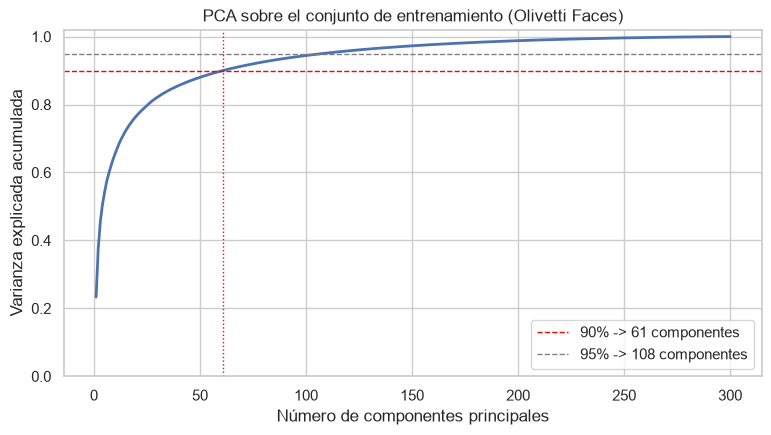

In [13]:
from sklearn.decomposition import PCA

# a) PCA ajustado SOLO con el conjunto de entrenamiento (todas las componentes posibles: min(300, 4096) = 300)
inicio = time.perf_counter()
pca_completo = PCA(svd_solver="full").fit(X_train)     # solver exacto y determinista (random_state no aplica)
t_pca = time.perf_counter() - inicio
print(f"Tiempo de ajuste del PCA completo: {t_pca:.2f} s")
var_acum = np.cumsum(pca_completo.explained_variance_ratio_)

# c) Número de componentes necesarias para explicar el 90% (y, como referencia, el 95% y 99%)
n_90 = int(np.argmax(var_acum >= 0.90) + 1)
n_95 = int(np.argmax(var_acum >= 0.95) + 1)
n_99 = int(np.argmax(var_acum >= 0.99) + 1)
print(f"Componentes ajustadas: {pca_completo.n_components_}")
print(f"Componentes para explicar el 90%: {n_90}  |  95%: {n_95}  |  99%: {n_99}")
print(f"Varianza explicada por las 5 primeras componentes: {np.round(pca_completo.explained_variance_ratio_[:5], 3)}")

# b) Varianza explicada acumulada
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(np.arange(1, len(var_acum) + 1), var_acum, lw=2)
ax.axhline(0.90, color="red", ls="--", lw=1, label=f"90% -> {n_90} componentes")
ax.axvline(n_90, color="red", ls=":", lw=1)
ax.axhline(0.95, color="gray", ls="--", lw=1, label=f"95% -> {n_95} componentes")
ax.set_xlabel("Número de componentes principales")
ax.set_ylabel("Varianza explicada acumulada")
ax.set_title("PCA sobre el conjunto de entrenamiento (Olivetti Faces)")
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
plt.show()

Tiempo de ajuste del PCA de 61 componentes: 0.96 s (se ajusta una sola vez para todos los SVM)
X_train_pca: (300, 61)  |  X_test_pca: (100, 61)
Varianza retenida con 61 componentes: 0.9003
Reducción de dimensionalidad: 4096 -> 61 (1.5% de las características originales)


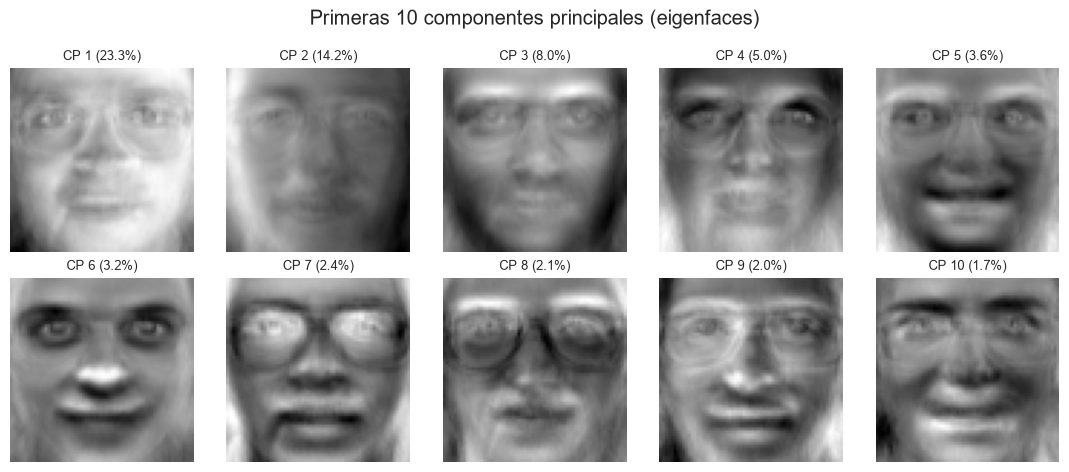

In [14]:
# d) Transformación de train y test con el PCA de n_90 componentes
inicio = time.perf_counter()
pca = PCA(n_components=n_90, svd_solver="full").fit(X_train)
t_pca = time.perf_counter() - inicio
print(f"Tiempo de ajuste del PCA de {n_90} componentes: {t_pca:.2f} s (se ajusta una sola vez para todos los SVM)")
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)
print(f"X_train_pca: {X_train_pca.shape}  |  X_test_pca: {X_test_pca.shape}")
print(f"Varianza retenida con {n_90} componentes: {pca.explained_variance_ratio_.sum():.4f}")
print(f"Reducción de dimensionalidad: 4096 -> {n_90} ({100 * n_90 / 4096:.1f}% de las características originales)")

# Las primeras componentes principales vistas como imágenes ("eigenfaces")
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(pca.components_[k].reshape(64, 64), cmap="gray")
    ax.set_title(f"CP {k + 1} ({100 * pca.explained_variance_ratio_[k]:.1f}%)", fontsize=9)
    ax.axis("off")
fig.suptitle("Primeras 10 componentes principales (eigenfaces)")
fig.subplots_adjust(hspace=0.35)
plt.tight_layout()
plt.show()

**a) Ajuste del PCA.** El PCA se ajusta **sólo con las 300 imágenes de entrenamiento** (el conjunto de prueba no debe influir en las direcciones principales). Con 300 muestras y 4096 variables el número máximo de componentes es 300. Se usa `svd_solver='full'` para obtener la descomposición exacta y reproducible.

**b) Varianza explicada acumulada.** La curva crece muy rápido al inicio (la primera componente explica el 23,3 %, las cinco primeras el 54 %) y luego se aplana: hay mucha redundancia entre los 4096 píxeles y la información relevante vive en un subespacio de dimensión mucho menor.

**c) Componentes para el 90 %: 61.** Como referencia, el 95 % requiere 108 y el 99 % requiere 211.

**d) Transformación.** Se reajusta un PCA con `n_components=61` sobre el entrenamiento y se transforman ambos conjuntos: `X_train_pca` queda de 300 x 61 y `X_test_pca` de 100 x 61, reteniendo el 90,0 % de la varianza de entrenamiento. La dimensionalidad baja de 4096 a 61 (1,5 % de las variables originales), lo que hace que el entrenamiento del SVM, cuyo costo depende del número de muestras y de la dimensión de los vectores, sea prácticamente instantáneo y reduce el ruido de píxel. Se eligió el criterio del 90 % en lugar de un valor fijo como 150 por parsimonia: las componentes 62 a 150 sólo añaden un 7 % de varianza (cada una explica menos del 0,3 %), y 61 dimensiones bastan, como se verá, para alcanzar 0,96-0,98 de accuracy; un modelo con menos dimensiones es más barato y más fácil de inspeccionar.

Las primeras componentes vistas como imágenes (*eigenfaces*) son interpretables: la componente 1 captura la iluminación global y el contraste rostro/fondo, la 2 y la 3 la dirección de la iluminación y la forma del contorno, y desde la 5-7 aparecen claramente los **lentes**, las cejas y la boca, rasgos que efectivamente distinguen personas en este dataset.

__Pregunta 2.2__: SVM - Comparación de Kernels (35 puntos)

Usando los datos transformados por PCA:

a) Entrene un `SVC` con kernel lineal (`kernel='linear'`) y `C=1.0`.

b) Entrene SVC con los siguientes kernels (usando `C=1.0` y `gamma='scale'` si aplica): RBF (`kernel='rbf'`) & Polinomial (`kernel='poly'`, `degree=4`).

c) Para cada uno de los tres modelos (lineal, RBF & poly), reporte en una tabla: accuracy en el conjunto de prueba, tiempo de entrenamiento & número de vectores de soporte (atributo `n_support_`).

d) ¿Qué kernel funciona mejor para este problema? Proponga una explicación.

### Respuesta 2.2:

In [15]:
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

# a) y b) Tres SVC con C=1.0 sobre los datos reducidos con PCA
# (random_state en SVC sólo interviene si probability=True; se incluye por consistencia con el enunciado)
configuraciones_svm = {
    "lineal": dict(kernel="linear", C=1.0),
    "rbf": dict(kernel="rbf", C=1.0, gamma="scale"),
    "poly (grado 4)": dict(kernel="poly", degree=4, C=1.0, gamma="scale"),
}
modelos_svm, filas = {}, []
for nombre, params in configuraciones_svm.items():
    modelo = SVC(random_state=SEED, **params)
    t_fit = cronometrar(modelo, X_train_pca, y_train)
    # Accuracy de validación cruzada (5 folds, sobre entrenamiento): estimación más estable que las 100 imágenes de prueba
    acc_cv = cross_val_score(SVC(random_state=SEED, **params), X_train_pca, y_train, cv=cv5)
    filas.append({
        "kernel": nombre,
        "accuracy_test": accuracy_score(y_test, modelo.predict(X_test_pca)),
        "accuracy_cv": acc_cv.mean(),
        "accuracy_cv_std": acc_cv.std(),
        "accuracy_train": accuracy_score(y_train, modelo.predict(X_train_pca)),
        "tiempo_entrenamiento_s": t_fit,
        # El tiempo de predicción incluye la proyección PCA de las imágenes de prueba (parte del pipeline del SVM)
        "tiempo_prediccion_s": tiempo_prediccion(lambda X, m=modelo: m.predict(pca.transform(X)), X_test),
        "n_vectores_soporte": int(modelo.n_support_.sum()),
        "SV por clase (mín-máx)": f"{modelo.n_support_.min()}-{modelo.n_support_.max()}",
        "% del train que son SV": 100 * modelo.n_support_.sum() / len(X_train_pca),
    })
    modelos_svm[nombre] = modelo

# c) Tabla comparativa
tabla_svm = pd.DataFrame(filas).set_index("kernel")
mostrar_tabla(tabla_svm)
for nombre in tabla_svm.index:
    resultados[f"SVM {nombre} (C=1)"] = tabla_svm.loc[nombre, ["accuracy_test", "accuracy_cv", "tiempo_entrenamiento_s",
                                                                "tiempo_prediccion_s", "n_vectores_soporte"]].to_dict()

gamma_scale = 1 / (X_train_pca.shape[1] * X_train_pca.var())
print(f"\ngamma='scale' equivale a 1 / (n_features * Var(X)) = {gamma_scale:.5f}")
K_lineal = gamma_scale * X_train_pca @ X_train_pca.T
print(f"Rango de gamma*<x, x'> entre pares de entrenamiento: [{K_lineal.min():.2f}, {K_lineal.max():.2f}] "
      f"(hay valores negativos porque el PCA centra los datos)")

# Experimento adicional para diagnosticar el kernel polinomial: otros grados y coef0=1
# (K = (gamma*<x,x'> + coef0)^degree; por defecto coef0=0)
for grado, coef0 in [(2, 0), (3, 0), (4, 0), (4, 1)]:
    m = SVC(kernel="poly", degree=grado, coef0=coef0, C=1.0, gamma="scale", random_state=SEED).fit(X_train_pca, y_train)
    print(f"poly degree={grado}, coef0={coef0}: accuracy test = {accuracy_score(y_test, m.predict(X_test_pca)):.2f}, "
          f"train = {accuracy_score(y_train, m.predict(X_train_pca)):.2f}")

,accuracy_test,accuracy_cv,accuracy_cv_std,accuracy_train,tiempo_entrenamiento_s,tiempo_prediccion_s,n_vectores_soporte,SV por clase (mín-máx),% del train que son SV
kernel,,,,,,,,,
lineal,0.98,0.9333,0.0105,1.0000,0.0198,0.0138,286,5-8,95.3333
rbf,0.93,0.9167,0.0183,0.9933,0.0223,0.0109,291,5-8,97.0000
poly (grado 4),0.49,0.3600,0.0620,0.6733,0.0228,0.0111,287,5-8,95.6667



gamma='scale' equivale a 1 / (n_features * Var(X)) = 0.01408
Rango de gamma*<x, x'> entre pares de entrenamiento: [-1.80, 2.66] (hay valores negativos porque el PCA centra los datos)
poly degree=2, coef0=0: accuracy test = 0.76, train = 0.89
poly degree=3, coef0=0: accuracy test = 0.59, train = 0.80
poly degree=4, coef0=0: accuracy test = 0.49, train = 0.67
poly degree=4, coef0=1: accuracy test = 0.97, train = 1.00


**a), b) y c) Resultados con `C=1.0` sobre los datos PCA (61 componentes).**

| Kernel | Accuracy prueba | Accuracy validación cruzada (5 folds) | Accuracy train | Tiempo entrenamiento | N° vectores de soporte (de 300) |
|---|---|---|---|---|---|
| Lineal | **0,98** | **0,933** ± 0,011 | 1,000 | centésimas de segundo | 286 (95 %) |
| RBF (`gamma='scale'`) | 0,93 | 0,917 ± 0,018 | 0,993 | centésimas de segundo | 291 (97 %) |
| Polinomial grado 4 (`gamma='scale'`, `coef0=0`) | 0,49 | 0,360 ± 0,062 | 0,673 | centésimas de segundo | 287 (96 %) |

Además de lo pedido se incluye el accuracy de validación cruzada (sobre las 300 imágenes de entrenamiento), porque con 100 imágenes de prueba un solo error mueve el accuracy un punto. Los tres modelos entrenan en centésimas de segundo (300 muestras en 61 dimensiones) y los tres usan casi todas las muestras como vectores de soporte (5-8 por clase). Esto último se explica porque, con 40 clases y una estrategia uno-contra-uno (780 clasificadores binarios de ~15 muestras cada uno), casi cualquier imagen queda sobre el margen de *alguno* de los pares de clases.

**d) ¿Qué kernel funciona mejor y por qué?** Con `C=1`, el **kernel lineal** es el mejor tanto en prueba (0,98, dos errores) como en validación cruzada (0,933 frente a 0,917 del RBF). La explicación es la geometría del problema: hay 300 muestras en un espacio de 61 dimensiones con sólo 7-8 ejemplos por clase; en esa situación (pocos puntos, muchas dimensiones) las clases son **prácticamente separables linealmente** (teorema de Cover), de modo que un hiperplano de margen máximo ya separa cada par de personas y no hace falta una frontera más flexible. Agregar no linealidad sólo añade capacidad para sobreajustar el ruido de los 7-8 puntos por clase.

El **kernel RBF** con `C=1` queda por debajo (0,93) no por falta de capacidad sino por **regularización excesiva**: `C=1` permite demasiadas violaciones de margen, y el mapa de calor de la pregunta 2.3 confirma que, con `gamma=0.01` (≈ `gamma='scale'` = 0,014), basta subir a `C=10` para llegar a 0,943 en validación y 0,96 en prueba.

El **kernel polinomial de grado 4** fracasa (0,49 en prueba y sólo 0,67 en entrenamiento: subajuste, no sobreajuste) por su parametrización por defecto `coef0=0`, que lo convierte en el kernel *homogéneo* K(x, x') = (γ⟨x, x'⟩)⁴. Como el PCA centra los datos, γ⟨x, x'⟩ toma valores entre −1,8 y 2,7; al elevar a la cuarta potencia, los productos con |γ⟨x, x'⟩| < 1 (la gran mayoría de los pares) se aplastan hacia 0 y los pocos mayores que 1 se amplifican (2,7⁴ ≈ 53), de modo que la matriz de kernel queda dominada por la diagonal y por unas pocas imágenes de gran norma, y el modelo apenas puede distinguir el resto. Este efecto empeora con el grado, como muestra el experimento adicional (0,76 con grado 2, 0,59 con grado 3, 0,49 con grado 4); que una potencia par pierda además el signo es un efecto secundario. El problema de fondo es la ausencia de los términos de orden inferior: con **grado 4 pero `coef0=1`**, es decir (γ⟨x, x'⟩ + 1)⁴, que incluye los términos de grado 0 a 4, el mismo kernel alcanza **0,97**, al nivel de los otros. En resumen, el kernel polinomial no es intrínsecamente malo para este problema, pero es muy sensible a su parametrización.

__Pregunta 2.3__: SVM - Optimización y Análisis (40 puntos)

Enfocándose en el kernel RBF, que suele ser el más robusto:

a) Use `GridSearchCV` para optimizar `C` y `gamma` sobre los datos de entrenamiento transformados con PCA. Pruebe los siguientes rangos: `C`: [0.1, 1, 10, 100] & `gamma`: [0.001, 0.01, 0.1, 1].

b) Reporte la mejor combinación de `C` y `gamma`, junto con su accuracy de validación.

c) Entrene el modelo final con estos hiperparámetros y evalúelo en el conjunto de prueba.

d) Compare el accuracy en prueba del mejor RF (de 1.3) vs. el mejor SVM (de 2.3). ¿Cuál modelo es más apropiado para este problema y por qué? (Considere accuracy, tiempo de entrenamiento & interpretabilidad).

e) **Identifique los vectores de soporte.**

### Respuesta 2.3:

16 combinaciones x 5 folds = 80 ajustes en 0.6 s
Mejores hiperparámetros: {'C': 10, 'gamma': 0.01}
Accuracy CV (5 folds) con los mejores hiperparámetros: 0.9433


Accuracy CV con el PCA reajustado dentro de cada fold (Pipeline): 0.9400 ± 0.0170


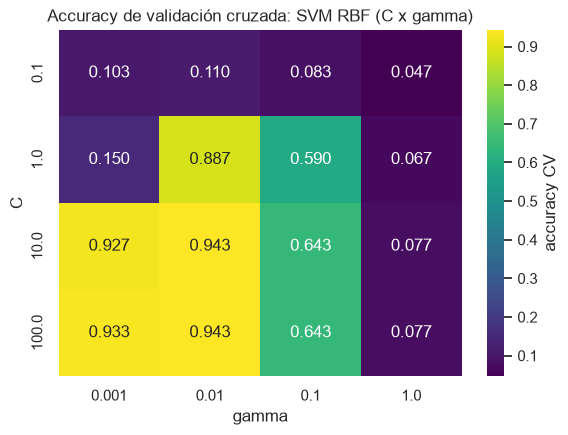

In [16]:
# a) GridSearchCV sobre C y gamma para el kernel RBF (datos de entrenamiento transformados con PCA)
param_grid_svm = {"C": [0.1, 1, 10, 100], "gamma": [0.001, 0.01, 0.1, 1]}
grid_svm = GridSearchCV(SVC(kernel="rbf", random_state=SEED), param_grid_svm, cv=cv5,
                        scoring="accuracy", n_jobs=-1, return_train_score=True)
inicio = time.perf_counter()
grid_svm.fit(X_train_pca, y_train)
t_grid_svm = time.perf_counter() - inicio
n_comb_svm = len(grid_svm.cv_results_["params"])
print(f"{n_comb_svm} combinaciones x 5 folds = {n_comb_svm * 5} ajustes en {t_grid_svm:.1f} s")

# b) Mejor combinación y su accuracy de validación
print("Mejores hiperparámetros:", grid_svm.best_params_)
print(f"Accuracy CV (5 folds) con los mejores hiperparámetros: {grid_svm.best_score_:.4f}")

# Comprobación de la fuga leve: el PCA se ajustó con TODO el train antes de la validación cruzada. Repetimos la CV
# de la mejor configuración con el PCA dentro de un Pipeline (se reajusta en cada fold sólo con los datos del fold).
from sklearn.pipeline import Pipeline
pipe_svm = Pipeline([("pca", PCA(n_components=n_90, svd_solver="full")),
                     ("svc", SVC(kernel="rbf", random_state=SEED, **grid_svm.best_params_))])
acc_pipe = cross_val_score(pipe_svm, X_train, y_train, cv=cv5)
print(f"Accuracy CV con el PCA reajustado dentro de cada fold (Pipeline): {acc_pipe.mean():.4f} ± {acc_pipe.std():.4f}")

res_svm = pd.DataFrame(grid_svm.cv_results_)
mapa_cv = res_svm.pivot(index="param_C", columns="param_gamma", values="mean_test_score")
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.heatmap(mapa_cv, annot=True, fmt=".3f", cmap="viridis", ax=ax, cbar_kws={"label": "accuracy CV"})
ax.set_title("Accuracy de validación cruzada: SVM RBF (C x gamma)")
ax.set_xlabel("gamma")
ax.set_ylabel("C")
plt.show()

In [17]:
# c) Modelo final con los mejores hiperparámetros, evaluado en prueba
svm_final = SVC(kernel="rbf", random_state=SEED, **grid_svm.best_params_)
t_svm_final = cronometrar(svm_final, X_train_pca, y_train)
y_pred_svm = svm_final.predict(X_test_pca)
acc_svm_final = accuracy_score(y_test, y_pred_svm)
# El tiempo de inferencia incluye la proyección PCA, que es parte del pipeline del SVM
t_pred_svm = tiempo_prediccion(lambda X: svm_final.predict(pca.transform(X)), X_test)
resultados["SVM RBF optimizado"] = {
    "accuracy_test": acc_svm_final, "accuracy_cv": grid_svm.best_score_,
    "precision_w_test": precision_score(y_test, y_pred_svm, average="weighted", zero_division=0),
    "recall_w_test": recall_score(y_test, y_pred_svm, average="weighted"),
    "f1_w_test": f1_score(y_test, y_pred_svm, average="weighted"),
    "tiempo_entrenamiento_s": t_svm_final, "tiempo_prediccion_s": t_pred_svm,
    "tiempo_busqueda_s": t_grid_svm, "n_vectores_soporte": int(svm_final.n_support_.sum()),
}
print(f"SVM RBF final (C={svm_final.C}, gamma={svm_final.gamma}): accuracy en prueba = {acc_svm_final:.4f}")
print(f"Errores en prueba: {int((y_pred_svm != y_test).sum())} de {len(y_test)}")

# d) Comparación del mejor RF (1.3) vs. el mejor SVM (2.3)
comparacion = pd.DataFrame({k: resultados[k] for k in ["RF optimizado", "SVM RBF optimizado"]}).loc[
    ["accuracy_cv", "accuracy_test", "precision_w_test", "recall_w_test", "f1_w_test",
     "tiempo_entrenamiento_s", "tiempo_prediccion_s", "tiempo_busqueda_s"]]
mostrar_tabla(comparacion)

SVM RBF final (C=10, gamma=0.01): accuracy en prueba = 0.9600
Errores en prueba: 4 de 100


,RF optimizado,SVM RBF optimizado
accuracy_cv,0.9200,0.9433
accuracy_test,0.9700,0.9600
precision_w_test,0.9783,0.9717
recall_w_test,0.9700,0.9600
f1_w_test,0.9688,0.9581
tiempo_entrenamiento_s,1.0904,0.0385
tiempo_prediccion_s,0.0450,0.0161
tiempo_busqueda_s,126.2623,0.5863


Vectores de soporte: 287 de 300 muestras de entrenamiento (95.7%)
Vectores de soporte por clase: mín 5, máx 8, media 7.17
Coeficientes duales (|alpha_i * y_i|) en el rango [0.000, 5.481]  (límite C = 10)


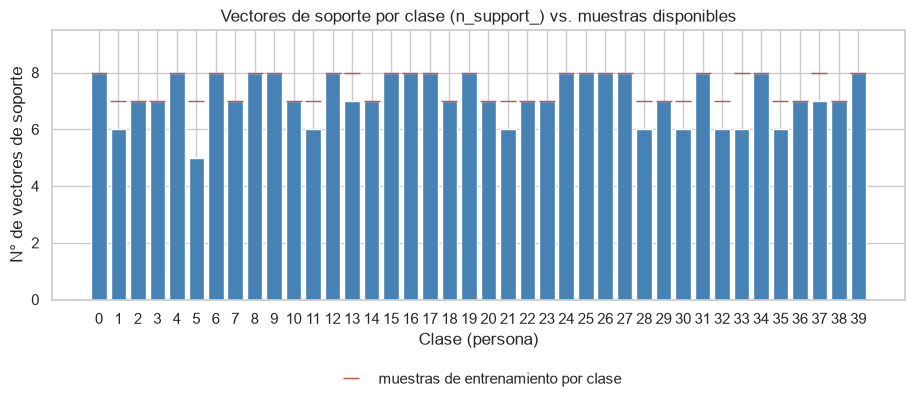

Primeros 20 índices de vectores de soporte (svm_final.support_): [45, 55, 78, 154, 182, 186, 236, 265, 19, 24, 89, 113, 170, 291, 84, 130, 144, 222, 227, 252] ...
Forma de support_vectors_: (287, 61) (vectores en el espacio PCA de 61 dimensiones)


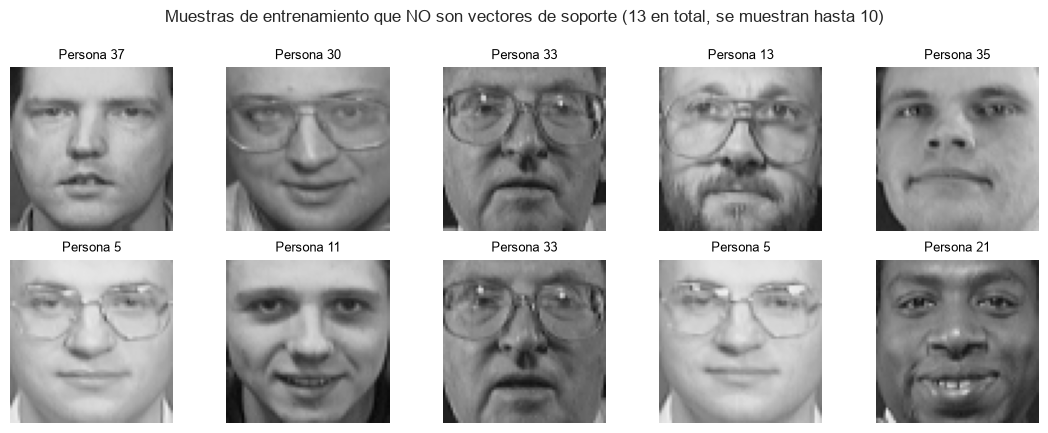

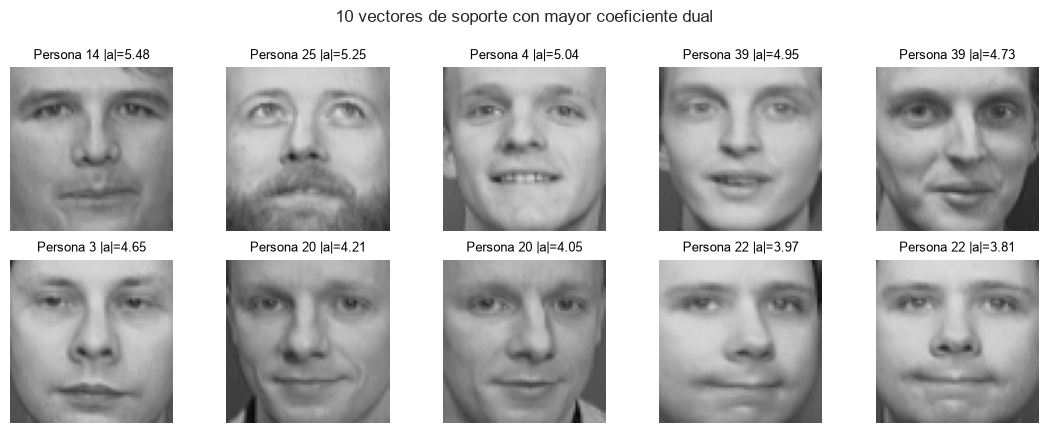

In [18]:
# e) Identificación de los vectores de soporte del SVM final
sv_idx = svm_final.support_                 # índices (en X_train_pca) de los vectores de soporte
print(f"Vectores de soporte: {len(sv_idx)} de {len(X_train_pca)} muestras de entrenamiento "
      f"({100 * len(sv_idx) / len(X_train_pca):.1f}%)")
print(f"Vectores de soporte por clase: mín {svm_final.n_support_.min()}, máx {svm_final.n_support_.max()}, "
      f"media {svm_final.n_support_.mean():.2f}")
print(f"Coeficientes duales (|alpha_i * y_i|) en el rango [{np.abs(svm_final.dual_coef_).min():.3f}, "
      f"{np.abs(svm_final.dual_coef_).max():.3f}]  (límite C = {svm_final.C})")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(range(40), svm_final.n_support_, color="steelblue")
ax.plot(range(40), np.bincount(y_train), "r_", ms=12, label="muestras de entrenamiento por clase")
ax.set_xlabel("Clase (persona)")
ax.set_ylabel("N° de vectores de soporte")
ax.set_title("Vectores de soporte por clase (n_support_) vs. muestras disponibles")
ax.set_xticks(range(40))
ax.set_ylim(0, 9.5)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
plt.show()
print(f"Primeros 20 índices de vectores de soporte (svm_final.support_): {sv_idx[:20].tolist()} ...")
print(f"Forma de support_vectors_: {svm_final.support_vectors_.shape} (vectores en el espacio PCA de {n_90} dimensiones)")

# Caras que NO son vectores de soporte (si las hay): son las más "fáciles", lejos de cualquier frontera
no_sv = np.setdiff1d(np.arange(len(X_train_pca)), sv_idx)
if len(no_sv) > 0:
    mostrar_caras(X_train[no_sv[:10]], titulos=[f"Persona {y_train[i]}" for i in no_sv[:10]],
                  titulo_general=f"Muestras de entrenamiento que NO son vectores de soporte ({len(no_sv)} en total, se muestran hasta 10)")
else:
    print("Todas las muestras de entrenamiento son vectores de soporte.")

# Los vectores de soporte con mayor coeficiente dual (los que más "pesan" en la frontera)
peso_sv = np.abs(svm_final.dual_coef_).max(axis=0)
orden_sv = np.argsort(peso_sv)[::-1][:10]
mostrar_caras(X_train[sv_idx[orden_sv]],
              titulos=[f"Persona {y_train[sv_idx[k]]} |a|={peso_sv[k]:.2f}" for k in orden_sv],
              titulo_general="10 vectores de soporte con mayor coeficiente dual")

**a) y b) GridSearchCV sobre `C` y `gamma` (kernel RBF, datos PCA, 5 folds).** Las 16 combinaciones (80 ajustes) tardan menos de un segundo. La mejor combinación es **`C=10`, `gamma=0.01`**, con **accuracy de validación 0,943** (`C=100, gamma=0.01` empata con el mismo valor; GridSearchCV conserva la primera en orden de la grilla).

*Nota metodológica:* el PCA se ajustó con las 300 imágenes de entrenamiento **antes** de la validación cruzada, de modo que cada fold de validación participó en el cálculo de las componentes sobre las que luego fue evaluado: una fuga de información leve, inducida por el enunciado (que pide buscar "sobre los datos de entrenamiento transformados con PCA") y que no afecta al conjunto de prueba. Para cuantificarla se repitió la validación cruzada de la mejor configuración con el PCA dentro de un `Pipeline`, reajustado en cada fold sólo con sus datos: **0,940 ± 0,017 frente a 0,943**, una diferencia de una imagen de 300, es decir, despreciable. La misma observación vale para las validaciones cruzadas de la Parte 2 (el preprocesador se ajusta con todo el train); allí el efecto esperable es igualmente pequeño porque la imputación, el escalado y el *one-hot* no usan la variable objetivo.

El mapa de calor es muy informativo:

* `gamma=1` colapsa el modelo (accuracy 0,05-0,08, apenas sobre el azar de 1/40 = 0,025): con un kernel tan estrecho cada imagen sólo se parece a sí misma, la matriz de kernel es casi la identidad y el modelo no puede generalizar. Con `C ≥ 1`, `gamma=0.1` recupera 0,59-0,64; con `C ≥ 10`, `gamma=0.01` y `gamma=0.001` dan los mejores resultados (0,927-0,943), mientras que con `C=1` sólo `gamma=0.01` funciona (0,887) y `gamma=0.001` es demasiado suave (0,150).
* `C=0.1` falla con cualquier `gamma` (0,047-0,110): la penalización es tan débil que el modelo prefiere un margen enorme con todas las muestras dentro de él. Con `C ≥ 10` el modelo deja de estar limitado por la regularización y `gamma` pasa a ser lo que manda; con `gamma=0.001` y `C` grande (0,927-0,933) el RBF se comporta casi como el kernel lineal (0,933 en validación cruzada, pregunta 2.2).

**c) Modelo final.** `SVC(kernel='rbf', C=10, gamma=0.01)` entrenado con todo el conjunto de entrenamiento PCA: **accuracy en prueba 0,96** (4 errores de 100), precision ponderada 0,972, recall 0,960, F1 0,958.

**d) Mejor RF (1.3) vs. mejor SVM (2.3).**

| | RF optimizado (200 árboles) | SVM RBF + PCA (C=10, γ=0,01) |
|---|---|---|
| Accuracy validación cruzada | 0,920 | **0,943** |
| Accuracy prueba | **0,97** | 0,96 |
| Tiempo de entrenamiento | Del orden de un segundo o menos (200 árboles, en paralelo en todos los núcleos) | Centésimas de segundo el SVM en sí (decenas de veces menos que el RF); sumando el ajuste del PCA, que se hace una sola vez, el costo total es del mismo orden que el del RF |
| Tiempo de inferencia (100 imágenes, un hilo) | Unas centésimas de segundo (recorrer 200 árboles sobre 4096 píxeles) | Entre 2 y 3 veces menos, incluida la proyección PCA |
| Tiempo de la búsqueda de hiperparámetros | Uno o dos minutos (270 ajustes) | Menos de un segundo (80 ajustes) |

En accuracy de prueba la diferencia es de **una sola imagen** (0,97 vs 0,96), muy por debajo de la incertidumbre de un conjunto de 100 muestras, mientras que en validación cruzada, que se calcula sobre 300 imágenes y es por tanto más fiable, el SVM es mejor por 2,3 puntos. Considerando además que el SVM en sí **entrena entre uno y dos órdenes de magnitud más rápido** (sumando el PCA, que se ajusta una sola vez, el costo total de entrenamiento es comparable al del RF), **predice 2-3 veces más rápido y su búsqueda de hiperparámetros tarda menos de un segundo frente a uno o dos minutos** (ver la tabla de la celda anterior y el resumen de 5.1), el modelo más apropiado para este problema es **SVM con PCA**. Nótese que el SVM lineal de la pregunta 2.2 obtuvo 0,98 en prueba con `C=1` sin ninguna búsqueda, aunque en validación cruzada (0,933) queda ligeramente por debajo del RBF optimizado (0,943): ambos kernels son opciones igualmente razonables. El Random Forest conserva una ventaja clara en **interpretabilidad**: sus importancias se visualizan directamente como un mapa de píxeles (1.4) y ofrece el OOB score gratis; el SVM en el espacio PCA explica sus decisiones mediante combinaciones de 61 *eigenfaces* y coeficientes duales, mucho menos legibles. Si la interpretabilidad fuera un requisito, el RF sería defendible; para un sistema de reconocimiento facial, donde prima la precisión y la velocidad, el SVM+PCA (el clásico enfoque *eigenfaces*) es la mejor opción.

**e) Vectores de soporte.** El modelo final tiene **287 vectores de soporte de 300 muestras de entrenamiento (95,7 %)**, entre 5 y 8 por persona (media 7,2), accesibles en `svm_final.support_` (índices), `support_vectors_` (los vectores en el espacio PCA) y `n_support_` (conteo por clase). Que casi todas las muestras sean vectores de soporte es característico de un problema con **muchas clases y muy pocos ejemplos por clase**: en la descomposición uno-contra-uno, cada imagen define el margen de alguno de los 39 problemas binarios en los que participa su clase. Ningún coeficiente dual alcanza la cota `C=10` (el máximo es 5,5), por lo que no hay muestras que violen el margen: los datos son separables con este kernel y los SV están exactamente sobre los márgenes. Las 13 imágenes que **no** son vectores de soporte son de dos tipos: algunas pertenecen a personas muy distintivas (barba poblada, lentes de marco grueso, tono de piel diferente del resto), es decir, puntos lejos de cualquier frontera; otras (por ejemplo, las dos de la persona 5 y las dos de la persona 33) son fotos casi duplicadas de otra foto de la misma persona que sí es vector de soporte, de modo que resultan redundantes para definir el margen. Los vectores de soporte con mayor coeficiente dual son mayoritariamente rostros masculinos jóvenes de apariencia parecida (personas 14, 4, 39, 3, 20, 22), aunque también aparece la persona 25, con barba poblada; incluyen a las personas 3 y 39 que el Random Forest confundió en 1.2, lo que es coherente con que sean rostros cercanos a alguna frontera.

## **PARTE 2: Regresión con XGBoost y Redes Neuronales**

En esta parte, trabajaremos con un problema de regresión: predecir el precio de venta de viviendas.

Dataset: Ames Housing (`fetch_openml('house_prices', as_frame=True)`) Este dataset es similar al de California, aunque ligeramente más complejo. Contiene 1460 muestras y 80 características, incluyendo variables numéricas (ej. 'LotArea', 'YearBuilt') y categóricas (ej. 'Neighborhood', 'RoofStyle'). La variable objetivo es 'SalePrice'.

__Pregunta 3.1__: Exploración y Preparación de Datos (20 puntos)

a) Cargue el dataset "house_prices" desde `fetch_openml`.

b) Separe las características (`X`) y la variable objetivo (`y`, 'SalePrice').

c) Divida los datos en entrenamiento (80%) y prueba (20%); identifique las columnas numéricas y categóricas; use `SimpleImputer` para rellenar valores faltantes (ej. mediana para numéricas, ya que es más robusta frente a valores atípicos, 'missing' para categóricas); use `OneHotEncoder` (con `handle_unknown='ignore'`) para las variables categóricas; use `StandardScaler` para las variables numéricas; y use `ColumnTransformer` y `Pipeline` para organizar esta preparación de forma limpia.

d) Transforme los conjuntos de entrenamiento y prueba con su pipeline.

### Respuesta 3.1:

Dimensiones del dataset: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


X: (1460, 79)   y: (1460,)


,count,mean,std,min,25%,50%,75%,max
SalePrice,1460.0,180921.2,79442.5,34900.0,129975.0,163000.0,214000.0,755000.0


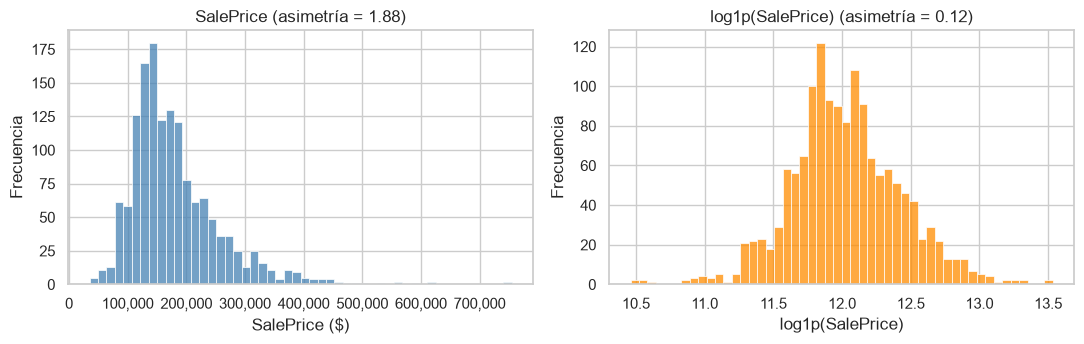

In [19]:
from sklearn.datasets import fetch_openml
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# a) Carga del dataset Ames Housing desde OpenML
housing = fetch_openml("house_prices", as_frame=True, parser="auto")
df_h = housing.frame
print(f"Dimensiones del dataset: {df_h.shape}")
display(df_h.head(3))

# b) Separación de características y variable objetivo
y_h = df_h["SalePrice"].astype(float)
X_h = df_h.drop(columns=["SalePrice", "Id"], errors="ignore")   # 'Id' es un identificador sin valor predictivo
print(f"X: {X_h.shape}   y: {y_h.shape}")
mostrar_tabla(y_h.describe().to_frame().T, 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(y_h, bins=50, ax=axes[0], color="steelblue")
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].set_title(f"SalePrice (asimetría = {stats.skew(y_h):.2f})")
axes[0].set_xlabel("SalePrice ($)"); axes[0].set_ylabel("Frecuencia")
sns.histplot(np.log1p(y_h), bins=50, ax=axes[1], color="darkorange")
axes[1].set_title(f"log1p(SalePrice) (asimetría = {stats.skew(np.log1p(y_h)):.2f})")
axes[1].set_xlabel("log1p(SalePrice)"); axes[1].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

In [20]:
# c) Identificación de columnas numéricas y categóricas
num_cols = X_h.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X_h.columns if c not in num_cols]
X_h[cat_cols] = X_h[cat_cols].astype(object)    # de 'category' a object para que SimpleImputer acepte 'missing'
# Nota: 'MSSubClass' es un código numérico de tipo de vivienda (nominal). Se mantiene como numérica: los modelos de
# árboles lo manejan sin problema y así se evita añadir 15 columnas one-hot más; se discute en la respuesta.
print(f"Columnas numéricas: {len(num_cols)}   |   Columnas categóricas: {len(cat_cols)}")
print("Ejemplos numéricas  :", num_cols[:8])
print("Ejemplos categóricas:", cat_cols[:8])

# División 80% / 20% (sin estratificar: es un problema de regresión)
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(X_h, y_h, test_size=0.2, random_state=SEED)
print(f"\nTrain: {X_train_h.shape}   Test: {X_test_h.shape}")

faltantes = (X_train_h.isna().mean() * 100).sort_values(ascending=False)
print(f"\nColumnas con valores faltantes en train: {(faltantes > 0).sum()} de {X_h.shape[1]}")
mostrar_tabla(faltantes[faltantes > 0].head(10).to_frame("% faltantes (train)"), 1)

# Pipeline de preparación: imputación + escalamiento (numéricas) / imputación + one-hot (categóricas)
pipeline_numerico = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler()),
])
pipeline_categorico = Pipeline([
    ("imputador", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocesador = ColumnTransformer([
    ("num", pipeline_numerico, num_cols),
    ("cat", pipeline_categorico, cat_cols),
])
preprocesador

Columnas numéricas: 36   |   Columnas categóricas: 43
Ejemplos numéricas  : ['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea']
Ejemplos categóricas: ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope']

Train: (1168, 79)   Test: (292, 79)

Columnas con valores faltantes en train: 19 de 79


,% faltantes (train)
PoolQC,99.5
MiscFeature,96.1
Alley,93.7
Fence,80.1
FireplaceQu,46.8
LotFrontage,18.6
GarageYrBlt,5.5
GarageQual,5.5
GarageFinish,5.5
GarageType,5.5


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [21]:
# d) Transformación de train y test (el pipeline se AJUSTA sólo con train para evitar fuga de información)
X_train_arr = preprocesador.fit_transform(X_train_h)
X_test_arr = preprocesador.transform(X_test_h)

# Nombres de las características resultantes (XGBoost no admite los caracteres [ ] < en los nombres)
nombres_features = [re.sub(r"[\[\]<>]", "_", n) for n in preprocesador.get_feature_names_out()]
X_train_prep = pd.DataFrame(X_train_arr, columns=nombres_features, index=X_train_h.index)
X_test_prep = pd.DataFrame(X_test_arr, columns=nombres_features, index=X_test_h.index)

n_onehot = sum(n.startswith("cat__") for n in nombres_features)
print(f"X_train_prep: {X_train_prep.shape}   |   X_test_prep: {X_test_prep.shape}")
print(f"{len(num_cols)} columnas numéricas escaladas + {n_onehot} columnas one-hot (de {len(cat_cols)} categóricas)")
print(f"Valores faltantes tras la preparación: {int(np.isnan(X_train_arr).sum()) + int(np.isnan(X_test_arr).sum())}")
display(X_train_prep.iloc[:3, :6].round(3))

X_train_prep: (1168, 302)   |   X_test_prep: (292, 302)
36 columnas numéricas escaladas + 266 columnas one-hot (de 43 categóricas)
Valores faltantes tras la preparación: 0


,num__MSSubClass,num__LotFrontage,num__LotArea,num__OverallQual,num__OverallCond,num__YearBuilt
254,-0.867,-0.012,-0.213,-0.820,0.372,-0.455
1066,0.074,-0.502,-0.265,-0.089,1.269,0.719
638,-0.632,-0.146,-0.178,-0.820,1.269,-1.988


**a) y b) Carga y separación.** `fetch_openml('house_prices', as_frame=True)` devuelve 1460 viviendas y 81 columnas. La variable objetivo es `SalePrice` (media \$180.921, mediana \$163.000, rango \$34.900-\$755.000). Se elimina la columna `Id` por ser un identificador sin valor predictivo, quedando **79 características**. La distribución de `SalePrice` tiene una fuerte asimetría positiva (coeficiente 1,88): pocas casas muy caras alargan la cola derecha; `log1p(SalePrice)` la vuelve casi simétrica (0,12), un dato que será relevante al discutir el escalamiento de `y` en la pregunta 4.1.

**c) Preparación.**

* **División:** 80 % entrenamiento (1168 casas) y 20 % prueba (292), `random_state=42`, sin estratificar porque la variable objetivo es continua.
* **Tipos de columnas:** 36 numéricas y 43 categóricas (detectadas por `dtype`). Nótese que `MSSubClass` es un código numérico de tipo de vivienda (nominal en realidad). Se mantiene como numérica por simplicidad: los modelos de árboles (RF, XGBoost) la manejan sin problema porque pueden aislar cualquier código con *splits* sucesivos, y convertirla a categórica añadiría 15 columnas *one-hot* más; el costo es que la regresión lineal y la red la tratan como si tuviera un orden, lo que es una limitación menor que se asume.
* **Valores faltantes:** 19 columnas tienen faltantes en entrenamiento. En la mayoría de las categóricas el faltante significa "no aplica" (`PoolQC` 99,5 %: casas sin piscina; `MiscFeature` 96 %; `Alley` 94 %; `Fence` 80 %; `FireplaceQu` 47 %; `Garage*` 5,5 %), por lo que imputar la categoría explícita `'missing'` es informativo y correcto. En las numéricas (`LotFrontage` 18,6 %, `GarageYrBlt` 5,5 %, `MasVnrArea`) se imputa la **mediana**, robusta a los valores extremos presentes en estas variables (lotes enormes, casas muy antiguas). Es una simplificación discutible para `GarageYrBlt`, cuyo faltante significa "sin garaje": una alternativa sería imputar un valor centinela o añadir un indicador de faltante, pero los modelos de árboles ya disponen de `GarageType_missing` para capturar esa información.
* **Pipeline:** `ColumnTransformer` con dos ramas: numéricas → `SimpleImputer(median)` → `StandardScaler`; categóricas → `SimpleImputer(constant='missing')` → `OneHotEncoder(handle_unknown='ignore')`. `handle_unknown='ignore'` evita errores si en prueba (o en producción) aparece una categoría no vista en entrenamiento: esa fila queda con todos los *dummies* de la variable en 0.

**d) Transformación.** El preprocesador se **ajusta únicamente con el conjunto de entrenamiento** (medianas, medias, desviaciones y categorías se aprenden allí) y luego se aplica a ambos conjuntos, evitando fuga de información hacia el conjunto de prueba. (En las validaciones cruzadas posteriores el preprocesador ya está ajustado con todo el train; es una fuga leve, inducida por el enunciado, que se cuantifica en la pregunta 2.3 para el caso análogo del PCA y resulta despreciable.) El resultado son matrices densas de **1168 x 302** y **292 x 302**: 36 columnas numéricas escaladas más 266 columnas *one-hot*, sin valores faltantes. Se conservan como `DataFrame` con los nombres generados (`num__GrLivArea`, `cat__Neighborhood_NAmes`, ...) para que las importancias de XGBoost y los gráficos SHAP sean legibles.

__Pregunta 3.2__: Modelos Baseline (25 puntos)

a) Entrene los siguientes modelos baseline en el conjunto de entrenamiento preparado: Regresión Lineal (`LinearRegression`) & Random Forest Regressor (`RandomForestRegressor` con parámetros por defecto).

b) Para cada modelo, reporte en el conjunto de prueba: Error Absoluto Medio (MAE), Error Cuadrático Medio (MSE), Raíz del Error Cuadrático Medio (RMSE) & Coeficiente de Determinación (R²).

c) Visualice las predicciones vs. los valores reales (un scatter plot `y_true` vs. `y_pred`) para el mejor de los dos modelos baseline.

### Respuesta 3.2:

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def evaluar_regresion(y_true, y_pred):
    """MAE, MSE, RMSE y R2 en la escala original de SalePrice."""
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": float(np.sqrt(mse)), "R2": r2_score(y_true, y_pred)}


# a) Modelos baseline
modelos_base = {
    "Regresión Lineal": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(random_state=SEED, n_jobs=-1),
}
predicciones_base = {}
for nombre, modelo in modelos_base.items():
    t_fit = cronometrar(modelo, X_train_prep, y_train_h)
    predicciones_base[nombre] = modelo.predict(X_test_prep)
    resultados[nombre] = {**evaluar_regresion(y_test_h, predicciones_base[nombre]),
                          "R2_train": r2_score(y_train_h, modelo.predict(X_train_prep)),
                          "tiempo_entrenamiento_s": t_fit}

# b) Métricas en el conjunto de prueba
tabla_base = pd.DataFrame({k: resultados[k] for k in modelos_base}).T
mostrar_tabla(tabla_base[["MAE", "MSE", "RMSE", "R2", "R2_train", "tiempo_entrenamiento_s"]])
print(f"Precio medio en prueba: ${y_test_h.mean():,.0f}  |  desviación estándar: ${y_test_h.std():,.0f}")

,MAE,MSE,RMSE,R2,R2_train,tiempo_entrenamiento_s
Regresión Lineal,21105.8986,4.268296e+09,65332.1989,0.4435,0.9401,0.3189
Random Forest Regressor,17656.3095,8.358927e+08,28911.8089,0.8910,0.9793,0.6192


Precio medio en prueba: $178,840  |  desviación estándar: $87,731


In [23]:
# Diagnóstico del bajo R2 en prueba de la Regresión Lineal (R2 train 0.94 vs. test 0.44)
lr = modelos_base["Regresión Lineal"]
pred_lr = predicciones_base["Regresión Lineal"]
residuos_lr = y_test_h.to_numpy() - pred_lr
peor = int(np.argmax(np.abs(residuos_lr)))
mascara = np.ones(len(residuos_lr), dtype=bool)
mascara[peor] = False
print(f"Peor predicción de la Regresión Lineal: real = ${y_test_h.iloc[peor]:,.0f}, predicho = ${pred_lr[peor]:,.0f}")
print(f"R2 en prueba SIN esa única casa: {r2_score(y_test_h.to_numpy()[mascara], pred_lr[mascara]):.4f}")
coefs = pd.Series(lr.coef_, index=nombres_features)
print("Coeficientes de mayor magnitud:")
mostrar_tabla(coefs.abs().sort_values(ascending=False).head(6).to_frame("|coef| ($)"), 0)
activas = [n for n in nombres_features if n.startswith("cat__") and X_test_prep.iloc[peor][n] == 1]
raras = {n: int(X_train_prep[n].sum()) for n in activas if X_train_prep[n].sum() <= 3}
print(f"Categorías de la peor casa con 3 o menos casos en train: {raras}")

# Referencia: la misma regresión con una regularización L2 suave elimina el problema
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=1.0).fit(X_train_prep, y_train_h)
print(f"Referencia: Ridge(alpha=1) sobre las mismas características -> R2 en prueba = "
      f"{r2_score(y_test_h, ridge.predict(X_test_prep)):.4f}")

Peor predicción de la Regresión Lineal: real = $171,000, predicho = $-839,306
R2 en prueba SIN esa única casa: 0.8993
Coeficientes de mayor magnitud:


,|coef| ($)
cat__PoolQC_missing,2999776.0
cat__PoolQC_Gd,1630471.0
cat__PoolQC_Fa,1086997.0
cat__RoofMatl_ClyTile,811025.0
cat__MiscFeature_TenC,614143.0
cat__PoolQC_Ex,282307.0


Categorías de la peor casa con 3 o menos casos en train: {'cat__PoolQC_Gd': 2}
Referencia: Ridge(alpha=1) sobre las mismas características -> R2 en prueba = 0.8849


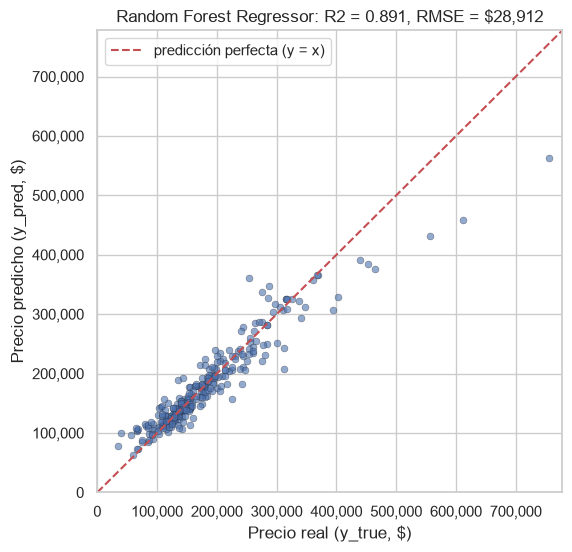

In [24]:
# c) Predicciones vs. valores reales para el mejor baseline (mayor R2 en prueba)
mejor_base = tabla_base["R2"].idxmax()
pred_mejor = predicciones_base[mejor_base]
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test_h, pred_mejor, alpha=0.6, s=25, edgecolor="k", linewidth=0.3)
lim = [0, max(y_test_h.max(), pred_mejor.max()) * 1.03]
ax.plot(lim, lim, "r--", label="predicción perfecta (y = x)")
ax.set_xlabel("Precio real (y_true, $)")
ax.set_ylabel("Precio predicho (y_pred, $)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}")); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title(f"{mejor_base}: R2 = {resultados[mejor_base]['R2']:.3f}, RMSE = ${resultados[mejor_base]['RMSE']:,.0f}")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.legend()
plt.show()

**a) y b) Métricas en el conjunto de prueba.**

| Modelo | MAE | MSE | RMSE | R² prueba | R² train |
|---|---|---|---|---|---|
| Regresión Lineal | \$21.106 | 4,27 × 10⁹ | \$65.332 | 0,444 | 0,940 |
| Random Forest Regressor | \$17.656 | 8,36 × 10⁸ | \$28.912 | **0,891** | 0,979 |

El Random Forest (por defecto, 100 árboles) es claramente el mejor baseline: explica el 89 % de la varianza del precio con un error típico de ~\$29.000 sobre un precio medio de \$179.000.

La **Regresión Lineal** merece un diagnóstico, porque su R² de prueba (0,44) contrasta con un MAE razonable (\$21.106) y con un R² de entrenamiento de 0,94. La celda de diagnóstico muestra que el problema es **una sola casa**: una vivienda de \$171.000 para la que el modelo predice **−\$839.000**. Si se excluye únicamente esa observación, el R² sube a **0,90**, en línea con el Random Forest. La causa es la combinación de mínimos cuadrados sin regularización con *one-hot* de categorías raras: esa casa tiene `PoolQC = 'Gd'`, categoría con **sólo 2 casos en el entrenamiento**, y los *dummies* de `PoolQC` son casi colineales con `PoolArea` (siete casas con piscina en todo el dataset). El sistema queda mal condicionado y los coeficientes de `PoolQC_*` alcanzan magnitudes de 1 a 3 millones de dólares que se cancelan entre sí en entrenamiento pero explotan al extrapolar. Es un ejemplo de libro de la **fragilidad de la regresión lineal ante colinealidad y categorías poco pobladas** (la misma celda muestra que una `Ridge(alpha=1)` sobre las mismas características obtiene R² ≈ 0,88). Como el enunciado pide `LinearRegression` como baseline, se reporta tal cual, con esta explicación. El MSE y el RMSE, al elevar al cuadrado, son mucho más sensibles a ese único error que el MAE, lo que explica la aparente contradicción entre métricas.

**c) Predicciones vs. reales del mejor baseline (Random Forest).** Los puntos se alinean bien con la diagonal hasta ~\$300.000; por encima, el modelo **subestima sistemáticamente** las casas más caras (las de \$450.000-\$755.000 se predicen entre \$380.000 y \$570.000). Es el comportamiento típico de los árboles: la predicción es el promedio de las casas que caen en cada hoja, y como hay muy pocas casas caras en entrenamiento, las hojas que las contienen mezclan precios altos con otros más moderados y el promedio queda por debajo. (El tope duro de los árboles, no poder predecir más que el máximo visto en entrenamiento, \$745.000, no es aquí la causa: la casa de \$755.000 se predice en ~\$563.000, muy por debajo de ese tope.) También se aprecia que la dispersión crece con el precio (heterocedasticidad), otro argumento a favor de modelar `log(SalePrice)` en un trabajo posterior.

__Pregunta 3.3__: XGBoost - Optimización (35 puntos)

a) Entrene un `XGBRegressor` con parámetros por defecto y reporte su R² en prueba.

b) Use `RandomizedSearchCV` (más rápido que GridSearch) con 5-folds para encontrar buenos hiperparámetros. Busque en un espacio como: `n_estimators`: [100, 500, 1000], `learning_rate`: [0.01, 0.1, 0.3], `max_depth`: [3, 5, 7] & `subsample`: [0.7, 1.0].

c) Implemente early stopping dividiendo su conjunto de entrenamiento en un nuevo sub-conjunto de entrenamiento (80%) y uno de validación (20%), y entrenando un `XGBRegressor` (con los mejores parámetros de (b)), usando el set de validación para `early_stopping_rounds=50`.

d) Grafique la curva de error (ej. RMSE) de entrenamiento y validación por número de árboles (épocas). ¿En qué iteración se detuvo el entrenamiento?

e) Compare el R² en prueba del XGBoost optimizado (con y sin early stopping) con los modelos baseline.

### Respuesta 3.3:

In [25]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV, KFold

# a) XGBRegressor con parámetros por defecto
xgb_default = XGBRegressor(random_state=SEED, n_jobs=-1)
t_xgb_default = cronometrar(xgb_default, X_train_prep, y_train_h)
resultados["XGBoost default"] = {**evaluar_regresion(y_test_h, xgb_default.predict(X_test_prep)),
                                 "R2_train": r2_score(y_train_h, xgb_default.predict(X_train_prep)),
                                 "tiempo_entrenamiento_s": t_xgb_default}
print(f"XGBoost por defecto -> R2 en prueba = {resultados['XGBoost default']['R2']:.4f} "
      f"(RMSE = ${resultados['XGBoost default']['RMSE']:,.0f}, entrenado en {t_xgb_default:.2f} s)")

# b) RandomizedSearchCV con 5 folds (25 de las 54 combinaciones posibles)
espacio_xgb = {
    "n_estimators": [100, 500, 1000],
    "learning_rate": [0.01, 0.1, 0.3],
    "max_depth": [3, 5, 7],
    "subsample": [0.7, 1.0],
}
kf5 = KFold(n_splits=5, shuffle=True, random_state=SEED)
busqueda_xgb = RandomizedSearchCV(XGBRegressor(random_state=SEED, n_jobs=-1), espacio_xgb, n_iter=25,
                                  cv=kf5, scoring="r2", random_state=SEED, n_jobs=1, return_train_score=True)
inicio = time.perf_counter()
busqueda_xgb.fit(X_train_prep, y_train_h)
t_busqueda_xgb = time.perf_counter() - inicio
print(f"\n{busqueda_xgb.n_iter} combinaciones x 5 folds = {busqueda_xgb.n_iter * 5} ajustes en {t_busqueda_xgb:.1f} s")
print("Mejores hiperparámetros:", busqueda_xgb.best_params_)
print(f"R2 de validación cruzada con los mejores hiperparámetros: {busqueda_xgb.best_score_:.4f}")

xgb_opt = busqueda_xgb.best_estimator_      # reentrenado con todo el conjunto de entrenamiento
resultados["XGBoost optimizado"] = {**evaluar_regresion(y_test_h, xgb_opt.predict(X_test_prep)),
                                    "R2_train": r2_score(y_train_h, xgb_opt.predict(X_train_prep)),
                                    "R2_cv": busqueda_xgb.best_score_,
                                    "tiempo_entrenamiento_s": busqueda_xgb.refit_time_,
                                    "tiempo_busqueda_s": t_busqueda_xgb}
print(f"XGBoost optimizado -> R2 en prueba = {resultados['XGBoost optimizado']['R2']:.4f}")

cols = ["param_n_estimators", "param_learning_rate", "param_max_depth", "param_subsample",
        "mean_test_score", "std_test_score", "mean_train_score", "mean_fit_time"]
res_xgb = pd.DataFrame(busqueda_xgb.cv_results_)
print("Las 25 configuraciones evaluadas, ordenadas por R2 de validación cruzada:")
mostrar_tabla(res_xgb[cols].sort_values("mean_test_score", ascending=False).reset_index(drop=True))
mejor_fila = res_xgb.loc[busqueda_xgb.best_index_]
print("R2 por fold de la mejor configuración:",
      [round(float(mejor_fila[f"split{k}_test_score"]), 3) for k in range(5)])

XGBoost por defecto -> R2 en prueba = 0.8981 (RMSE = $27,955, entrenado en 0.91 s)



25 combinaciones x 5 folds = 125 ajustes en 414.5 s
Mejores hiperparámetros: {'subsample': 0.7, 'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.1}
R2 de validación cruzada con los mejores hiperparámetros: 0.8691
XGBoost optimizado -> R2 en prueba = 0.9124
Las 25 configuraciones evaluadas, ordenadas por R2 de validación cruzada:


,param_n_estimators,param_learning_rate,param_max_depth,param_subsample,mean_test_score,std_test_score,mean_train_score,mean_fit_time
0,500,0.10,5,0.7,0.8691,0.0395,1.0000,3.1002
1,1000,0.01,3,0.7,0.8677,0.0566,0.9693,3.6542
2,100,0.10,5,0.7,0.8672,0.0398,0.9895,0.5787
3,500,0.01,5,0.7,0.8636,0.0455,0.9787,3.0345
4,1000,0.01,3,1.0,0.8595,0.0568,0.9694,3.7966
5,100,0.10,3,1.0,0.8582,0.0620,0.9694,0.5074
6,1000,0.01,7,0.7,0.8574,0.0534,0.9974,8.4322
7,500,0.10,7,0.7,0.8524,0.0539,1.0000,4.1411
8,1000,0.10,7,0.7,0.8524,0.0539,1.0000,9.2431
9,100,0.10,7,0.7,0.8520,0.0531,0.9970,0.7977


R2 por fold de la mejor configuración: [0.895, 0.82, 0.823, 0.893, 0.915]


Sub-entrenamiento: (934, 302)   Validación: (234, 302)


Iteraciones ejecutadas: 276  |  mejor iteración (best_iteration): 225
RMSE de validación en la mejor iteración: $24,821
El entrenamiento se detuvo en la iteración 275 = 225 + 50 rondas sin mejora


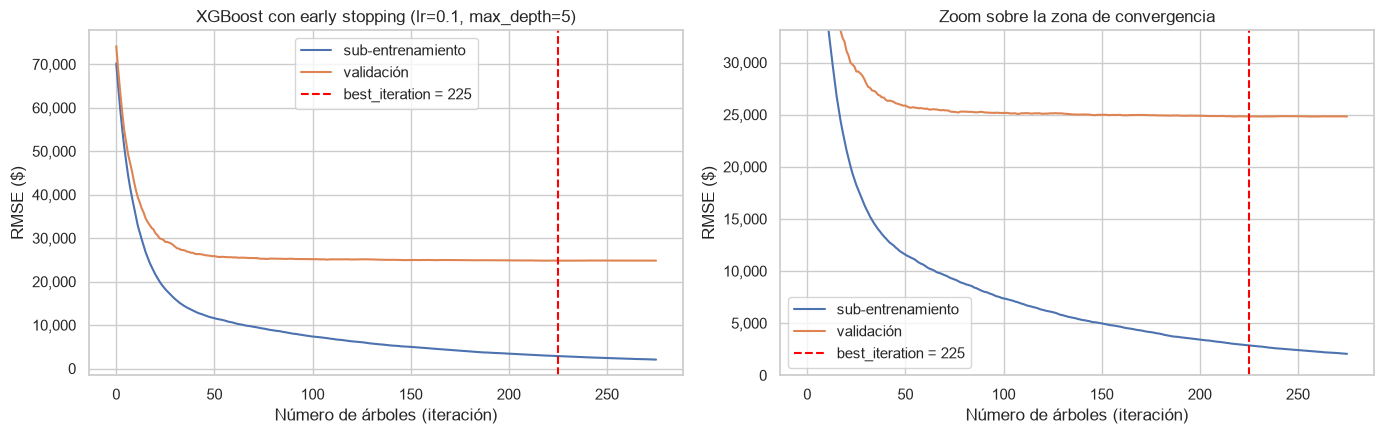

In [26]:
# c) Early stopping: sub-conjunto de entrenamiento (80%) y de validación (20%) tomados del train original
X_sub, X_val, y_sub, y_val = train_test_split(X_train_prep, y_train_h, test_size=0.2, random_state=SEED)
print(f"Sub-entrenamiento: {X_sub.shape}   Validación: {X_val.shape}")

# Se usan los mejores hiperparámetros de (b); n_estimators se eleva a un techo alto (2000)
# porque justamente el early stopping es quien decide cuántos árboles se construyen.
params_es = {**busqueda_xgb.best_params_, "n_estimators": 2000}
xgb_es = XGBRegressor(**params_es, early_stopping_rounds=50, eval_metric="rmse", random_state=SEED, n_jobs=-1)
t_xgb_es = cronometrar(xgb_es, X_sub, y_sub, eval_set=[(X_sub, y_sub), (X_val, y_val)], verbose=False)

curvas = xgb_es.evals_result()
rmse_sub, rmse_val = curvas["validation_0"]["rmse"], curvas["validation_1"]["rmse"]
print(f"Iteraciones ejecutadas: {len(rmse_val)}  |  mejor iteración (best_iteration): {xgb_es.best_iteration}")
print(f"RMSE de validación en la mejor iteración: ${xgb_es.best_score:,.0f}")
print(f"El entrenamiento se detuvo en la iteración {len(rmse_val) - 1} = {xgb_es.best_iteration} + 50 rondas sin mejora")

# d) Curva de RMSE de entrenamiento y validación por número de árboles
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, zoom in zip(axes, [False, True]):
    ax.plot(rmse_sub, label="sub-entrenamiento")
    ax.plot(rmse_val, label="validación")
    ax.axvline(xgb_es.best_iteration, color="red", ls="--", label=f"best_iteration = {xgb_es.best_iteration}")
    ax.set_xlabel("Número de árboles (iteración)")
    ax.set_ylabel("RMSE ($)")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.legend()
    if zoom:
        ax.set_ylim(0, 1.3 * max(rmse_val[len(rmse_val) // 4:]))
        ax.set_title("Zoom sobre la zona de convergencia")
    else:
        ax.set_title(f"XGBoost con early stopping (lr={params_es['learning_rate']}, max_depth={params_es['max_depth']})")
plt.tight_layout()
plt.show()

In [27]:
# e) Comparación de R2 en prueba: baselines vs. XGBoost (default, optimizado, con early stopping)
resultados["XGBoost opt. + early stopping"] = {**evaluar_regresion(y_test_h, xgb_es.predict(X_test_prep)),
                                               "R2_train": r2_score(y_sub, xgb_es.predict(X_sub)),
                                               "tiempo_entrenamiento_s": t_xgb_es,
                                               "n_arboles": xgb_es.best_iteration + 1}

# Variante habitual en la práctica: reentrenar con TODO el train usando el número de árboles que indicó el early stopping
xgb_es_refit = XGBRegressor(**{**busqueda_xgb.best_params_, "n_estimators": xgb_es.best_iteration + 1},
                            random_state=SEED, n_jobs=-1)
t_xgb_es_refit = cronometrar(xgb_es_refit, X_train_prep, y_train_h)
resultados["XGBoost ES reentrenado (todo el train)"] = {**evaluar_regresion(y_test_h, xgb_es_refit.predict(X_test_prep)),
                                                        "R2_train": r2_score(y_train_h, xgb_es_refit.predict(X_train_prep)),
                                                        "tiempo_entrenamiento_s": t_xgb_es_refit,
                                                        "n_arboles": xgb_es.best_iteration + 1}

orden_modelos = ["Regresión Lineal", "Random Forest Regressor", "XGBoost default", "XGBoost optimizado",
                 "XGBoost opt. + early stopping", "XGBoost ES reentrenado (todo el train)"]
tabla_xgb = pd.DataFrame({k: resultados[k] for k in orden_modelos}).T[["R2", "R2_train", "RMSE", "MAE", "tiempo_entrenamiento_s"]]
mostrar_tabla(tabla_xgb)

,R2,R2_train,RMSE,MAE,tiempo_entrenamiento_s
Regresión Lineal,0.4435,0.9401,65332.1989,21105.8986,0.3189
Random Forest Regressor,0.8910,0.9793,28911.8089,17656.3095,0.6192
XGBoost default,0.8981,0.9998,27955.0391,17301.9766,0.9149
XGBoost optimizado,0.9124,0.9999,25919.7491,15902.4507,2.4931
XGBoost opt. + early stopping,0.9129,0.9986,25845.6995,15536.4091,1.9494
XGBoost ES reentrenado (todo el train),0.9130,0.9975,25833.7246,15906.4733,1.4913


**a) XGBoost por defecto.** `XGBRegressor(random_state=42)` (100 árboles, `learning_rate=0.3`, `max_depth=6`) obtiene **R² = 0,898** en prueba (RMSE \$27.955) en alrededor de un segundo, ya mejor que el Random Forest (0,891) y muy por encima de la regresión lineal.

**b) RandomizedSearchCV.** Se muestrearon 25 de las 54 combinaciones posibles del espacio indicado, con 5 folds (125 ajustes, varios minutos: es el paso más costoso del trabajo). Mejores hiperparámetros: **`n_estimators=500`, `learning_rate=0.1`, `max_depth=5`, `subsample=0.7`**, con **R² de validación cruzada 0,869** (± 0,04). En prueba este modelo alcanza **R² = 0,912** (RMSE \$25.920). La tabla completa de las 25 configuraciones muestra dos regímenes: las ocho mejores están entre 0,852 y 0,869 de R² en validación y, en general, todas las configuraciones con un producto `learning_rate × n_estimators` suficiente (≥ 10) quedan por encima de 0,80; en cambio, las tres configuraciones con `learning_rate=0.01` y sólo 100 árboles caen a 0,65-0,67, porque el modelo no alcanza a converger (100 pasos de tamaño 0,01 explican sólo una fracción de la señal). Es decir, XGBoost es poco sensible a los hiperparámetros **siempre que la tasa de aprendizaje y el número de árboles se compensen** (0,01 con 1000 árboles funciona casi igual que 0,1 con 500). Que el R² de validación cruzada (0,87) sea menor que el de prueba (0,91) se explica con los R² por fold de la mejor configuración, que se imprimen en la celda: dos folds quedan en ~0,82 y los otros tres en 0,89-0,92; los folds bajos contienen las viviendas atípicas del dataset (las de más de 4000 pies² vendidas a precio bajo), que castigan fuertemente el R² de ese fold, mientras que el conjunto de prueba resultó algo más benigno.

**c) Early stopping.** El conjunto de entrenamiento se dividió en sub-entrenamiento (934 casas, 80 %) y validación (234, 20 %). Se entrenó un `XGBRegressor` con los mejores hiperparámetros de (b), fijando `n_estimators=2000` como techo (el número de árboles es precisamente lo que el *early stopping* debe decidir; con el valor 500 del punto (b) el criterio también se habría activado, pues el óptimo está por debajo) y `early_stopping_rounds=50` sobre el RMSE de validación.

**d) Curvas de error.** El RMSE de sub-entrenamiento cae monótonamente hasta ~\$2.000 (el modelo memoriza), mientras que el de validación desciende rápido hasta ~\$26.000 en 50 árboles, mejora lentamente hasta **\$24.821 en la iteración 225** y después se mantiene plano. **El entrenamiento se detuvo en la iteración 275** (276 árboles construidos): la mejor iteración fue la **225** y las 50 rondas siguientes no mejoraron el RMSE de validación. Para predecir, XGBoost usa automáticamente sólo los 226 primeros árboles.

**e) Comparación de R² en prueba.**

| Modelo | R² prueba | RMSE | R² train |
|---|---|---|---|
| Regresión Lineal | 0,444 | \$65.332 | 0,940 |
| Random Forest Regressor | 0,891 | \$28.912 | 0,979 |
| XGBoost por defecto | 0,898 | \$27.955 | 0,9998 |
| XGBoost optimizado (500 árboles) | 0,912 | \$25.920 | 0,9999 |
| XGBoost optimizado + early stopping (226 árboles, 80 % del train) | **0,913** | \$25.846 | 0,9986 |
| XGBoost con 226 árboles reentrenado en todo el train | **0,913** | \$25.834 | 0,9975 |

Las tres variantes optimizadas de XGBoost son equivalentes en prueba (0,912-0,913) y superan al mejor baseline en ~2 puntos de R² y ~\$3.000 de RMSE. El *early stopping* no mejora el error final: la curva de validación es prácticamente plana desde los ~100 árboles hasta los 275 en que se detuvo, y el modelo de 500 árboles rinde igual en prueba, lo que indica que XGBoost con `learning_rate=0.1` y `subsample=0.7` es muy robusto al exceso de árboles. Su aporte es **reducir el modelo de 500 a 226 árboles** sin pérdida (menos de la mitad de árboles que construir y recorrer) y entregar un criterio objetivo para elegir `n_estimators` sin necesidad de incluirlo en la búsqueda. Los R² de entrenamiento cercanos a 1 indican que los modelos memorizan el entrenamiento; aun así generalizan mejor que el Random Forest, porque la combinación de *shrinkage*, submuestreo y profundidad limitada controla la varianza.

__Pregunta 3.4__: XGBoost - Interpretabilidad (20 puntos)

a) Extraiga y visualice la importancia de las variables (`plot_importance`) del modelo XGBoost optimizado. Muestre las 15 variables más importantes.

b) Utilice la librería `shap` para interpretar las predicciones de la siguiente forma: calcule los SHAP values para el conjunto de prueba, visualice el `summary_plot` (beeswarm), y muestre el `dependence_plot` para las 2 variables más importantes. ¿Cuáles son las variables más influyentes y cómo afectan el precio? (Responda brevemente).

### Respuesta 3.4:

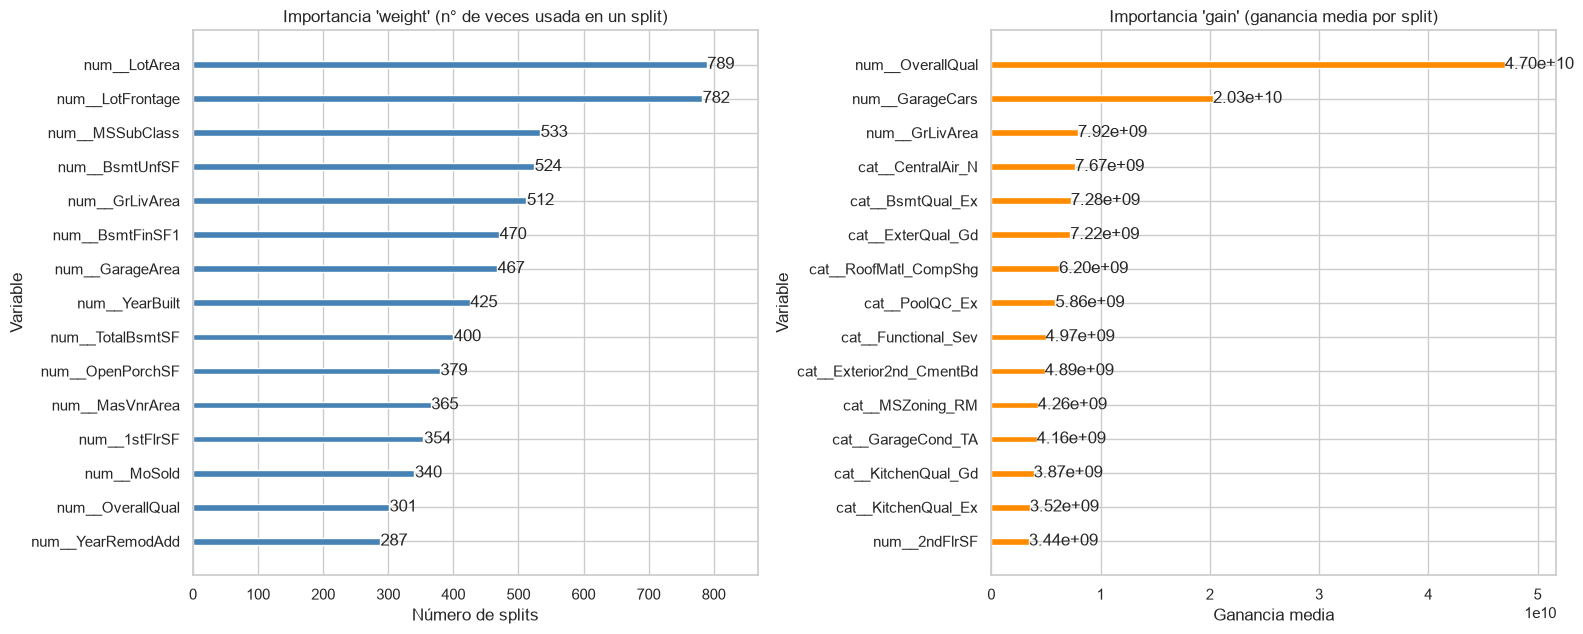

In [28]:
from xgboost import plot_importance

# a) Importancia de variables del XGBoost optimizado (15 más importantes) según dos criterios
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
plot_importance(xgb_opt, max_num_features=15, importance_type="weight", ax=axes[0], values_format="{v:.0f}",
                title="Importancia 'weight' (n° de veces usada en un split)", color="steelblue",
                xlabel="Número de splits", ylabel="Variable")
plot_importance(xgb_opt, max_num_features=15, importance_type="gain", ax=axes[1], values_format="{v:.2e}",
                title="Importancia 'gain' (ganancia media por split)", color="darkorange",
                xlabel="Ganancia media", ylabel="Variable")
plt.tight_layout()
plt.show()

SHAP values: (292, 302); valor base (predicción media) = $181,658

Top 10 variables por |SHAP| medio (impacto medio sobre el precio, en $):


,|SHAP| medio ($)
num__OverallQual,26731.0
num__GrLivArea,15071.0
num__BsmtFinSF1,4847.0
num__TotalBsmtSF,4721.0
num__LotArea,3907.0
num__YearBuilt,3608.0
num__GarageCars,3354.0
num__YearRemodAdd,3169.0
num__OverallCond,3009.0
num__1stFlrSF,2218.0


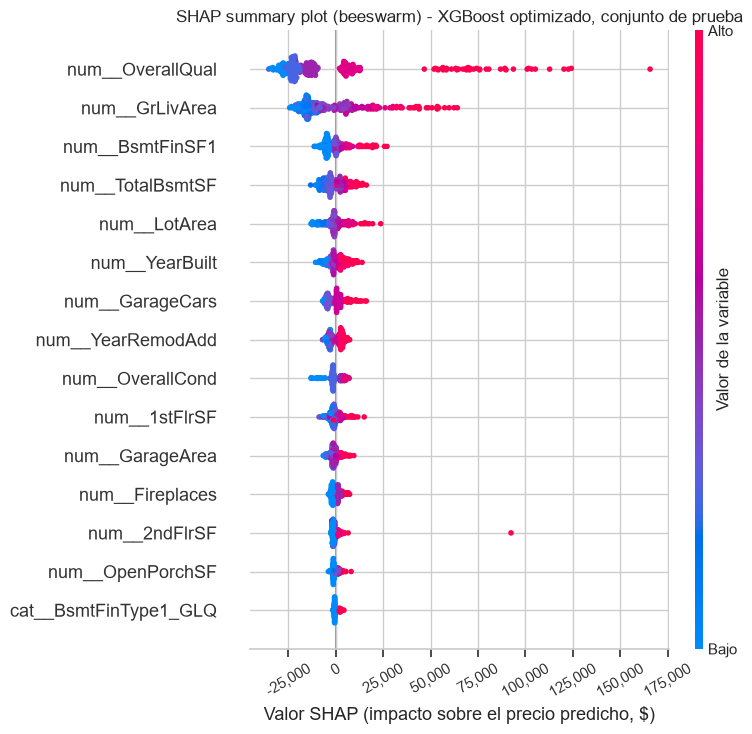

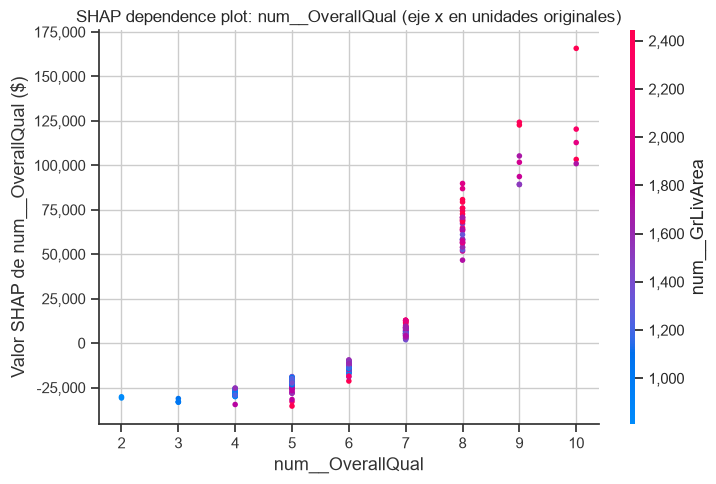

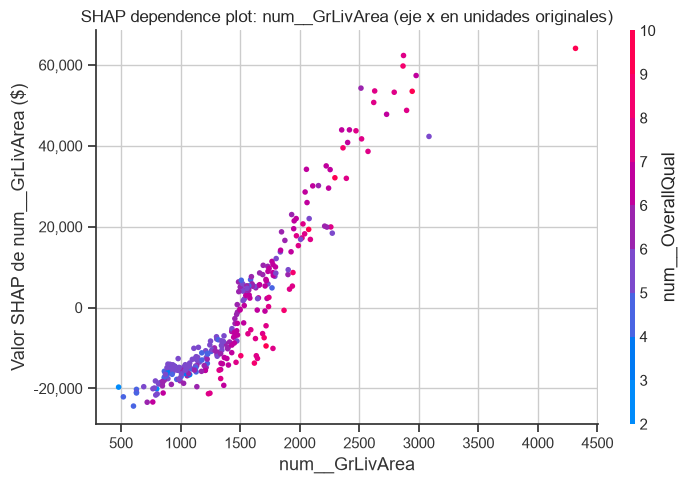

In [29]:
# b) Interpretación con SHAP sobre el conjunto de prueba
explicador = shap.TreeExplainer(xgb_opt)
shap_values = explicador(X_test_prep)                    # objeto Explanation: (292 muestras x n_features)
print(f"SHAP values: {shap_values.values.shape}; valor base (predicción media) = ${shap_values.base_values[0]:,.0f}")

# Para los dependence plots se muestran las variables numéricas en su escala ORIGINAL (no estandarizada)
X_test_display = X_test_prep.copy()
for c in num_cols:
    X_test_display[f"num__{c}"] = X_test_h[c].to_numpy()

importancia_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_test_prep.columns)
importancia_shap = importancia_shap.sort_values(ascending=False)
print("\nTop 10 variables por |SHAP| medio (impacto medio sobre el precio, en $):")
mostrar_tabla(importancia_shap.head(10).to_frame("|SHAP| medio ($)"), 0)

shap.summary_plot(shap_values, X_test_prep, max_display=15, show=False)
fig = plt.gcf()
fig.axes[0].set_xlabel("Valor SHAP (impacto sobre el precio predicho, $)")
fig.axes[0].tick_params(axis="x", labelrotation=30)
fig.axes[0].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
if len(fig.axes) > 1:
    barra = fig.axes[-1]
    barra.set_ylabel("Valor de la variable", labelpad=-15)
    barra.set_yticklabels([{"Low": "Bajo", "High": "Alto"}.get(t.get_text(), t.get_text()) for t in barra.get_yticklabels()])
plt.title("SHAP summary plot (beeswarm) - XGBoost optimizado, conjunto de prueba")
plt.tight_layout()
plt.show()

top2 = importancia_shap.index[:2].tolist()
for variable in top2:
    # Como "features" se pasa la matriz con las numéricas en su escala original: sólo define los ejes y el color
    shap.dependence_plot(variable, shap_values.values, X_test_display, interaction_index="auto", show=False)
    plt.gca().set_ylabel(f"Valor SHAP de {variable} ($)")
    plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    if len(plt.gcf().axes) > 1:      # barra de color de la variable de interacción: sin decimales espurios
        plt.gcf().axes[-1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    plt.title(f"SHAP dependence plot: {variable} (eje x en unidades originales)")
    plt.tight_layout()
    plt.show()

**a) Importancia de variables (`plot_importance`, 15 más importantes).** (Los prefijos `num__` y `cat__` de los nombres indican la rama del pipeline de la que proviene cada variable: numérica escalada o *dummy* de una categórica.) Se muestran dos criterios porque cuentan cosas distintas:

* **`weight`** (número de *splits* en que se usa la variable, el criterio por defecto) favorece a las variables **continuas con muchos valores distintos**: `LotArea` (789 splits), `LotFrontage` (782), `MSSubClass`, `BsmtUnfSF`, `GrLivArea`, `BsmtFinSF1`, `GarageArea`, `YearBuilt`... Una variable continua puede partirse muchas veces en umbrales distintos aunque cada partición aporte poco. `OverallQual`, la variable más importante por cualquier otro criterio, aparece recién en el puesto 14 porque sólo tiene 10 valores posibles.
* **`gain`** (reducción media de la pérdida por *split*) ordena por **utilidad real**: `OverallQual` domina con amplia diferencia, seguida de `GarageCars`, `GrLivArea` y varias *dummies* de calidad (`CentralAir_N`, `BsmtQual_Ex`, `ExterQual_Gd`, `KitchenQual_Ex/Gd`), más algunas categorías raras pero decisivas en pocas casas (`RoofMatl_CompShg`, `PoolQC_Ex`, `Functional_Sev`).

Para interpretar el modelo, `gain` (o mejor aún SHAP) es el criterio adecuado; `weight` mide más bien la granularidad de la variable.

**b) SHAP.** *En breve:* las dos variables que dominan el precio son la **calidad general** (`OverallQual`, efecto creciente y convexo: penaliza a las casas de calidad ≤ 6 y premia fuertemente a las de 8-10) y la **superficie habitable** (`GrLivArea`, efecto casi lineal: cada pie² adicional sube el precio, más aún si la calidad es alta); detrás vienen la superficie del sótano, el tamaño del terreno, la antigüedad y el garaje, todas con efecto positivo cuando crecen. El detalle:

Los valores SHAP se calcularon con `TreeExplainer` (exacto para árboles) sobre las 292 casas de prueba; el valor base (predicción media) es \$181.658 y cada valor SHAP indica cuántos dólares suma o resta cada variable a la predicción de cada casa.

*Variables más influyentes* (|SHAP| medio): **`OverallQual` (\$26.731)** y **`GrLivArea` (\$15.071)** destacan muy por encima del resto; luego `BsmtFinSF1` (\$4.847), `TotalBsmtSF` (\$4.721), `LotArea` (\$3.907), `YearBuilt` (\$3.608), `GarageCars` (\$3.354), `YearRemodAdd` (\$3.169), `OverallCond` (\$3.009) y `1stFlrSF` (\$2.218). Es decir: **calidad general de la construcción, superficie habitable, superficie del sótano, tamaño del terreno, antigüedad/remodelación y garaje**. Las categóricas, repartidas en 266 *dummies*, tienen impactos individuales pequeños (`BsmtFinType1_GLQ` es la primera que aparece).

*Cómo afectan al precio* (beeswarm y dependence plots):

* **`OverallQual`** actúa de forma **monótona y convexa**: las casas de calidad 5 o menos reciben una penalización de \$18.000-\$36.000; calidad 6 resta ~\$10.000-\$20.000; calidad 7 suma \$0-\$13.000; calidad 8 entre \$47.000 y \$90.000; y las de calidad 9-10 suman \$90.000-\$165.000. El efecto de la calidad es mucho mayor en el extremo alto, y el *dependence plot*, coloreado por `GrLivArea`, muestra una **interacción**: la superficie **amplifica** el efecto de la calidad en ambos sentidos. Entre las casas de calidad 8-10, las más grandes (puntos rojos) obtienen el premio mayor; entre las de calidad 4-6, las más grandes reciben la penalización mayor (una casa grande de baja calidad es, para el modelo, un peor negocio que una pequeña de baja calidad).
* **`GrLivArea`** tiene un efecto **aproximadamente lineal y creciente**: las casas de ~800-1000 pies² restan unos \$20.000, las de ~1500 pies² están en torno a 0 y las de más de 2500 pies² suman \$40.000-\$65.000. El color (`OverallQual`) muestra de nuevo la interacción: por debajo de ~1500 pies² los puntos de alta calidad quedan algo por debajo de los de baja calidad (una casa pequeña "desaprovecha" su calidad), y por encima de ~2000 pies² casi todos los puntos son de alta calidad y la pendiente es más empinada, es decir, cada pie² adicional vale más en una casa de buena calidad.
* En el beeswarm, los valores altos (rojo) de `TotalBsmtSF`, `BsmtFinSF1`, `LotArea`, `YearBuilt`, `YearRemodAdd`, `GarageCars` y `Fireplaces` empujan el precio hacia arriba y los bajos hacia abajo, siempre con asimetría: los impactos positivos de estas variables alcanzan +\$10.000-\$25.000 (los mayores en `BsmtFinSF1` y `LotArea`) mientras que los negativos rara vez superan −\$10.000, coherente con la cola derecha de la distribución de precios.

__Pregunta 4.1__: Redes Neuronales - Arquitectura Básica (25 puntos)

Usaremos el mismo dataset de Ames Housing preparado.

a) Para esta parte, es crucial que la variable objetivo `y` (SalePrice) también esté estandarizada (o transformada, ej. con `np.log1p`). Entrene un `StandardScaler` en el `y_train`, y transforme `y_train` e `y_test`. ¿Por qué es importante escalar la variable objetivo para las redes neuronales?

b) Implemente un `MLPRegressor` simple con: una capa oculta de 64 neuronas (`hidden_layer_sizes=(64,)`), función de activación ReLU (`activation='relu'`), optimizador Adam (`solver='adam'`) & con early stopping (`early_stopping=True`) (use 10% de los datos de entrenamiento como validación por defecto).

c) Entrénelo y reporte el R² en el conjunto de prueba (recuerde revertir la transformación de `y_pred` e `y_true` antes de calcular R²).

### Respuesta 4.1:

y_train original: media = 181,442, desv. est. = 77,264
y_train escalada: media = -0.000, desv. est. = 1.000


MLP (64,) con y SIN escalar (300 épocas máx.): R2 en prueba = -3.626, épocas = 300, loss inicial = 1.955e+10, loss final = 1.742e+10



MLP (64,) con y escalada: R2 en prueba = 0.8767  |  RMSE = $30,748  |  R2 train = 0.9799  |  R2 CV (5 folds) = 0.8307 ± 0.0679
Épocas hasta el early stopping: 74  |  loss final: 0.0058  |  tiempo: 1.84 s
R2 calculado en la escala estandarizada: 0.8767 (coincide: R2 es invariante a transformaciones lineales de y)


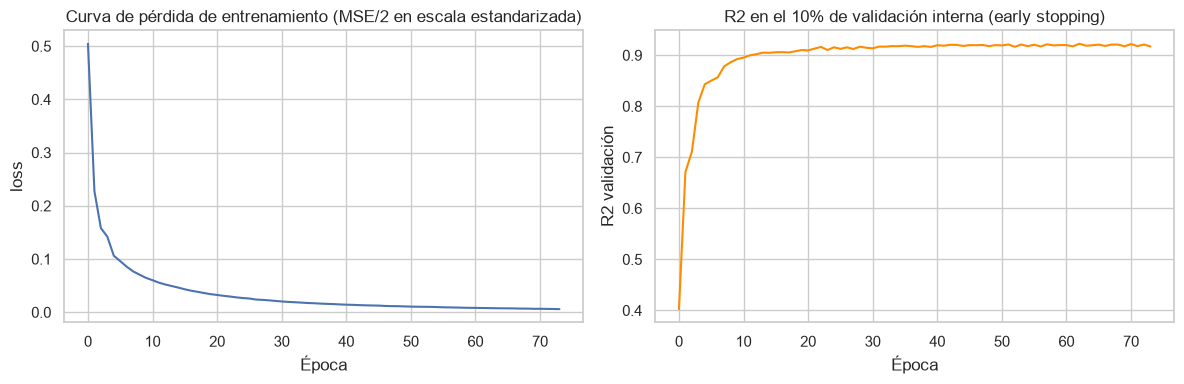

In [30]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import cross_val_score, KFold   # ya importados antes; se repiten por claridad

# a) Estandarización de la variable objetivo (ajustada SOLO con y_train)
escalador_y = StandardScaler().fit(y_train_h.to_numpy().reshape(-1, 1))
y_train_s = escalador_y.transform(y_train_h.to_numpy().reshape(-1, 1)).ravel()
y_test_s = escalador_y.transform(y_test_h.to_numpy().reshape(-1, 1)).ravel()
print(f"y_train original: media = {y_train_h.mean():,.0f}, desv. est. = {y_train_h.std():,.0f}")
print(f"y_train escalada: media = {y_train_s.mean():.3f}, desv. est. = {y_train_s.std():.3f}")


def entrenar_mlp(cv=True, **params):
    """Entrena un MLPRegressor sobre y estandarizada y devuelve sus métricas en la escala original.

    Además del ajuste final (todo el train -> prueba), calcula el R2 de validación cruzada (5 folds, sólo train),
    que es el criterio con el que se ELIGEN arquitectura, alpha y solver: el conjunto de prueba se reporta pero
    nunca se usa para seleccionar. (R2 es invariante a la estandarización de y, así que el CV puede hacerse en
    la escala estandarizada.)
    """
    config = dict(random_state=SEED, max_iter=1000)
    config.update(params)
    mlp = MLPRegressor(**config)
    t_fit = cronometrar(mlp, X_train_prep, y_train_s)
    # Se revierte la estandarización antes de calcular las métricas
    pred_test = escalador_y.inverse_transform(mlp.predict(X_test_prep).reshape(-1, 1)).ravel()
    pred_train = escalador_y.inverse_transform(mlp.predict(X_train_prep).reshape(-1, 1)).ravel()
    metricas = evaluar_regresion(y_test_h, pred_test)
    metricas.update({"R2_train": r2_score(y_train_h, pred_train), "tiempo_entrenamiento_s": t_fit,
                     "loss_final": mlp.loss_, "n_iter": mlp.n_iter_, "modelo": mlp, "pred_test": pred_test})
    if cv:
        inicio = time.perf_counter()
        r2_cv = cross_val_score(MLPRegressor(**config), X_train_prep, y_train_s, cv=kf5, scoring="r2", n_jobs=5)
        metricas.update({"R2_cv": r2_cv.mean(), "R2_cv_std": r2_cv.std(), "tiempo_cv_s": time.perf_counter() - inicio})
    return metricas


# Ilustración de por qué hay que escalar y: la misma red entrenada sobre SalePrice sin escalar.
# (Se espera que NO converja en 300 épocas; se silencia sólo aquí el ConvergenceWarning correspondiente.)
from sklearn.exceptions import ConvergenceWarning
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    mlp_sin_escalar = MLPRegressor(hidden_layer_sizes=(64,), activation="relu", solver="adam", early_stopping=True,
                                   max_iter=300, random_state=SEED).fit(X_train_prep, y_train_h)
print(f"MLP (64,) con y SIN escalar (300 épocas máx.): R2 en prueba = "
      f"{r2_score(y_test_h, mlp_sin_escalar.predict(X_test_prep)):.3f}, épocas = {mlp_sin_escalar.n_iter_}, "
      f"loss inicial = {mlp_sin_escalar.loss_curve_[0]:.3e}, loss final = {mlp_sin_escalar.loss_:.3e}")

# b) MLP simple: una capa oculta de 64 neuronas, ReLU, Adam y early stopping (10% de train como validación)
mlp_base = entrenar_mlp(hidden_layer_sizes=(64,), activation="relu", solver="adam", early_stopping=True)
resultados["MLP (64,)"] = {k: v for k, v in mlp_base.items() if k not in ("modelo", "pred_test")}

# c) R2 en prueba (escala original) -- y, como verificación, en la escala estandarizada
r2_escalado = r2_score(y_test_s, mlp_base["modelo"].predict(X_test_prep))
print(f"\nMLP (64,) con y escalada: R2 en prueba = {mlp_base['R2']:.4f}  |  RMSE = ${mlp_base['RMSE']:,.0f}  |  "
      f"R2 train = {mlp_base['R2_train']:.4f}  |  R2 CV (5 folds) = {mlp_base['R2_cv']:.4f} ± {mlp_base['R2_cv_std']:.4f}")
print(f"Épocas hasta el early stopping: {mlp_base['n_iter']}  |  loss final: {mlp_base['loss_final']:.4f}  |  "
      f"tiempo: {mlp_base['tiempo_entrenamiento_s']:.2f} s")
print(f"R2 calculado en la escala estandarizada: {r2_escalado:.4f} (coincide: R2 es invariante a transformaciones lineales de y)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(mlp_base["modelo"].loss_curve_)
axes[0].set_title("Curva de pérdida de entrenamiento (MSE/2 en escala estandarizada)")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("loss")
axes[1].plot(mlp_base["modelo"].validation_scores_, color="darkorange")
axes[1].set_title("R2 en el 10% de validación interna (early stopping)")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("R2 validación")
plt.tight_layout()
plt.show()

**a) ¿Por qué escalar la variable objetivo?** `SalePrice` tiene media ~\$181.000 y desviación ~\$77.000. Si se entrena un MLP directamente sobre esos valores:

1. **Escala de la pérdida y de los gradientes.** El MLP minimiza el error cuadrático; con precios del orden de 10⁵ la pérdida inicial es del orden de 10¹⁰ y los gradientes respecto de los pesos de salida son proporcionales al error (10⁵). Con SGD el paso es proporcional al gradiente, así que los primeros pasos serían enormes y el entrenamiento oscilaría o divergiría. Adam normaliza el gradiente y su paso efectivo es del orden de `learning_rate_init` (0,001) por parámetro, con lo que ocurre lo contrario: para que la salida alcance valores de ~1,8·10⁵ los pesos y sesgos tendrían que crecer varios órdenes de magnitud en pasos de ~0,001, lo que requiere muchísimas más actualizaciones de las que caben en un entrenamiento normal. La celda lo ilustra: la misma red (64,) entrenada sobre `SalePrice` sin escalar termina sus 300 épocas con una pérdida ~10¹⁰ apenas reducida y un **R² de prueba negativo** (peor que predecir la media).
2. **Inicialización.** Los pesos se inicializan (Glorot) suponiendo entradas y salidas de magnitud ~1; con la salida en escala 10⁵ la red arranca prediciendo ≈ 0 para todas las casas y debe hacer crecer pesos o sesgos en varios órdenes de magnitud, un régimen para el que la inicialización no está pensada y que favorece neuronas ReLU "muertas" (que quedan con salida 0 y gradiente 0).
3. **Hiperparámetros que dependen de la escala.** La regularización L2 (`alpha`) penaliza los pesos en términos absolutos, de modo que su valor adecuado cambia con la escala de la salida; y la tolerancia de parada `tol=1e-4`, que sin *early stopping* se compara con cambios absolutos de la pérdida, no tiene sentido frente a pérdidas de 10¹⁰ (con `early_stopping=True` se compara con el R² de validación, que sí es invariante, pero el problema de convergencia persiste).

Estandarizar `y` (media 0, desviación 1) resuelve lo anterior. Es imprescindible ajustar el `StandardScaler` **sólo con `y_train`** y aplicar la misma transformación a `y_test`, y luego **revertirla** (`inverse_transform`) sobre las predicciones para reportar errores en dólares. (Una alternativa igualmente válida es `log1p`, que además corrige la asimetría; se usa la estandarización como pide el enunciado.) Los árboles no necesitan nada de esto: en el Random Forest la predicción es el promedio de los valores de `y` de cada hoja y en XGBoost cada hoja aporta una corrección aditiva sobre los residuos; en ambos, los umbrales candidatos de cada *split* dependen sólo del orden de las variables de entrada y la elección del mejor *split* es invariante a transformaciones afines de `y`; la escala de `y` sólo importaría a través de los parámetros de regularización de XGBoost (`reg_lambda`, `gamma`), que aquí se dejan por defecto.

**b) y c) MLP simple.** `MLPRegressor(hidden_layer_sizes=(64,), activation='relu', solver='adam', early_stopping=True, max_iter=1000, random_state=42)`: 302 entradas → 64 neuronas ReLU → 1 salida (19.457 parámetros). Con *early stopping*, el 10 % del entrenamiento (117 casas) se reserva como validación interna y el entrenamiento se detiene cuando el R² de validación no mejora en 10 épocas consecutivas.

* **R² en prueba (escala original): 0,877**, RMSE \$30.748; R² de entrenamiento 0,980; R² de validación cruzada (5 folds sobre el entrenamiento) 0,831 ± 0,068. La desviación entre folds es grande porque dos de ellos contienen las viviendas atípicas comentadas en 3.3.
* Se detuvo tras 74 épocas, en pocos segundos, con `loss_` = 0,0058 (MSE/2 en la escala estandarizada).
* Como comprobación, el R² calculado en la escala estandarizada es idéntico (0,877): el R² es invariante a transformaciones lineales de `y`, pero el RMSE y el MAE no, y deben reportarse siempre en la escala original.

La curva de pérdida cae de forma suave y el R² de validación interna se estabiliza en ~0,92 a partir de la época 20. El modelo es competitivo con el Random Forest (0,891) pero queda por debajo de XGBoost (0,912), y la brecha train/test (0,98 vs 0,88) ya anticipa cierto sobreajuste. La red entrenada sobre `SalePrice` **sin escalar** (primera línea de la salida) confirma el punto (a): tras 300 épocas su pérdida sigue en ~1,7·10¹⁰ y su R² de prueba es **−3,6**, peor que predecir la media.

__Pregunta 4.2__: Redes Neuronales - Arquitectura y Profundidad (30 puntos)

a) Experimente con diferentes arquitecturas variando el número de capas y neuronas. Pruebe al menos 4 arquitecturas, por ejemplo: `hidden_layer_sizes=(50,)`, `hidden_layer_sizes=(100, 50)`, `hidden_layer_sizes=(100, 50, 25)` & `hidden_layer_sizes=(200, 100)`.

b) Para cada arquitectura, entrene y reporte: R² en el conjunto de prueba, tiempo de entrenamiento & loss de entrenamiento final (atributo `loss_`).

c) ¿Cuál es la arquitectura óptima para este problema? ¿Observa sobreentrenamiento en las redes más profundas (ej. comparando su score de entrenamiento vs. prueba)?

### Respuesta 4.2:

,n_capas_ocultas,n_parametros,R2_cv,R2_cv_std,R2_test,R2_train,RMSE_test,tiempo_entrenamiento_s,loss_final,n_iter,brecha_R2 (train - test)
arquitectura,,,,,,,,,,,
"(50,)",1,15201,0.8331,0.0676,0.8739,0.9656,31104.3880,1.3198,0.0097,52,0.0917
"(64,)",1,19457,0.8307,0.0679,0.8767,0.9799,30748.3361,2.5860,0.0058,74,0.1031
"(100, 50)",2,35401,0.8437,0.0424,0.8761,0.9525,30823.5856,1.7168,0.0089,25,0.0763
"(100, 50, 25)",3,36651,0.8355,0.0369,0.8748,0.9608,30992.1715,1.6590,0.0073,26,0.0861
"(200, 100)",2,80801,0.8296,0.0678,0.8419,0.8775,34828.0959,1.6060,0.0122,15,0.0357
"(200, 100, 50)",3,85801,0.8047,0.0943,0.8775,0.9731,30649.1490,2.9627,0.0037,28,0.0956


Mejor arquitectura por R2 de validación cruzada: (100, 50)  (R2 CV = 0.8437, R2 prueba = 0.8761)
(La mejor por R2 de prueba habría sido (200, 100, 50); no se usa ese criterio para no contaminar la evaluación final.)


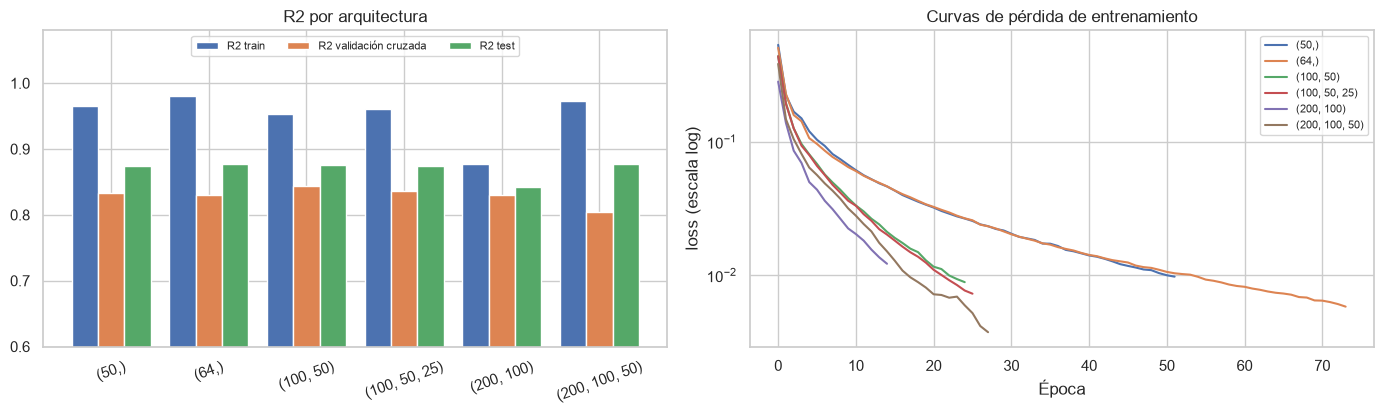

In [31]:
# a) y b) Distintas arquitecturas (mismo solver Adam, ReLU y early stopping que en 4.1)
arquitecturas = [(50,), (64,), (100, 50), (100, 50, 25), (200, 100), (200, 100, 50)]
experimentos_arq = {}
for arq in arquitecturas:
    experimentos_arq[arq] = entrenar_mlp(hidden_layer_sizes=arq, activation="relu", solver="adam", early_stopping=True)

n_entradas = X_train_prep.shape[1]
filas = []
for arq, res in experimentos_arq.items():
    capas = [n_entradas, *arq, 1]
    n_param = sum(a * b + b for a, b in zip(capas[:-1], capas[1:]))
    filas.append({"arquitectura": str(arq), "n_capas_ocultas": len(arq), "n_parametros": n_param,
                  "R2_cv": res["R2_cv"], "R2_cv_std": res["R2_cv_std"],
                  "R2_test": res["R2"], "R2_train": res["R2_train"], "RMSE_test": res["RMSE"],
                  "tiempo_entrenamiento_s": res["tiempo_entrenamiento_s"], "loss_final": res["loss_final"],
                  "n_iter": res["n_iter"]})
tabla_arq = pd.DataFrame(filas).set_index("arquitectura")
tabla_arq["brecha_R2 (train - test)"] = tabla_arq.R2_train - tabla_arq.R2_test
mostrar_tabla(tabla_arq)

# c) Mejor arquitectura: se elige por R2 de VALIDACIÓN CRUZADA (nunca por el conjunto de prueba)
mejor_arq = arquitecturas[int(np.argmax(tabla_arq.R2_cv.values))]
print(f"Mejor arquitectura por R2 de validación cruzada: {mejor_arq}  "
      f"(R2 CV = {tabla_arq.loc[str(mejor_arq), 'R2_cv']:.4f}, R2 prueba = {tabla_arq.loc[str(mejor_arq), 'R2_test']:.4f})")
print(f"(La mejor por R2 de prueba habría sido {arquitecturas[int(np.argmax(tabla_arq.R2_test.values))]}; "
      "no se usa ese criterio para no contaminar la evaluación final.)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
x = np.arange(len(arquitecturas))
axes[0].bar(x - 0.27, tabla_arq.R2_train, 0.27, label="R2 train")
axes[0].bar(x, tabla_arq.R2_cv, 0.27, label="R2 validación cruzada")
axes[0].bar(x + 0.27, tabla_arq.R2_test, 0.27, label="R2 test")
axes[0].set_xticks(x); axes[0].set_xticklabels(tabla_arq.index, rotation=20)
axes[0].set_ylim(0.6, 1.08); axes[0].set_title("R2 por arquitectura"); axes[0].legend(loc="upper center", ncol=3, fontsize=8)
for arq, res in experimentos_arq.items():
    axes[1].plot(res["modelo"].loss_curve_, label=str(arq))
axes[1].set_yscale("log"); axes[1].set_xlabel("Época"); axes[1].set_ylabel("loss (escala log)")
axes[1].set_title("Curvas de pérdida de entrenamiento"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Criterio de selección.** Para no contaminar la evaluación final, la arquitectura (y en 4.3 el `alpha` y el `solver`) se elige por el **R² de validación cruzada de 5 folds sobre el conjunto de entrenamiento**; el R² de prueba se reporta para cada configuración, como pide el enunciado, pero no se usa para decidir.

**a) y b) Arquitecturas probadas** (todas con ReLU, Adam, `early_stopping=True`, `max_iter=1000`, `random_state=42`):

| Arquitectura | Parámetros | R² validación cruzada | R² prueba | R² train | RMSE prueba | `loss_` final | Épocas |
|---|---|---|---|---|---|---|---|
| (50,) | 15.201 | 0,833 ± 0,068 | 0,874 | 0,966 | \$31.104 | 0,0097 | 52 |
| (64,) (4.1) | 19.457 | 0,831 ± 0,068 | 0,877 | 0,980 | \$30.748 | 0,0058 | 74 |
| **(100, 50)** | 35.401 | **0,844 ± 0,042** | 0,876 | 0,953 | \$30.824 | 0,0089 | 25 |
| (100, 50, 25) | 36.651 | 0,836 ± 0,037 | 0,875 | 0,961 | \$30.992 | 0,0073 | 26 |
| (200, 100) | 80.801 | 0,830 ± 0,068 | 0,842 | 0,878 | \$34.828 | 0,0122 | 15 |
| (200, 100, 50) | 85.801 | 0,805 ± 0,094 | 0,878 | 0,973 | \$30.649 | 0,0037 | 28 |

Los tiempos de entrenamiento (columna `tiempo_entrenamiento_s` de la tabla de la celda anterior) son del orden de un segundo en todos los casos y, a grandes rasgos, crecen con el número de parámetros: la red (200, 100, 50) tarda entre 2 y 4 veces más que (50,) aunque necesite la mitad de épocas, porque cada época es proporcionalmente más cara.

**c) Arquitectura óptima y sobreajuste.**

* **Arquitectura óptima: (100, 50)**, con el mejor R² de validación cruzada (0,844) y una dispersión entre folds baja (0,042; sólo (100, 50, 25) la tiene menor); en prueba obtiene 0,876. Es importante notar lo apretado del resultado: cinco de las seis arquitecturas quedan en una franja de **0,874-0,878 de R² en prueba**, diferencias de menos de 0,004 (unos \$450 de RMSE) que están muy por debajo de la desviación entre folds (0,04-0,09). Si se hubiera elegido por R² de prueba, habría ganado (200, 100, 50) por 0,0008 sobre (64,) y 0,0014 sobre (100, 50), un criterio que además sesgaría al alza la comparación final; la validación cruzada señala justamente a esa red como la menos fiable (0,805 ± 0,094).
* La excepción es **(200, 100)**, con 0,842 en prueba: no es que la arquitectura sea mala, sino que el *early stopping* se activó prematuramente en la época 15 (el R² de la validación interna, calculado sobre sólo 117 casas, dejó de mejorar durante 10 épocas antes de que la red terminara de ajustarse). Es un recordatorio de que el *early stopping* con `n_iter_no_change=10` sobre una validación pequeña introduce varianza en el resultado.
* **¿Hay sobreajuste en las redes más profundas?** Sí hay sobreajuste, pero no crece con la profundidad. Todas las redes que entrenan normalmente tienen un R² de entrenamiento entre 0,95 y 0,98 frente a 0,87-0,88 en prueba, una **brecha de 0,08-0,10** (la red (200, 100), al detenerse a las 15 épocas, es la única con brecha pequeña, 0,036, porque está subajustada). La red más profunda, (200, 100, 50), alcanza la menor pérdida de entrenamiento (0,0037, un 64 % de la de (64,)) sin mejorar en prueba, y es la que peor y con más varianza generaliza en validación cruzada: su capacidad extra se gasta en memorizar, y es el *early stopping* lo que impide que la brecha se agrande. Las redes más profundas convergen en menos épocas (25-28 frente a 52-74) porque tienen más parámetros para ajustar los datos en cada paso. En resumen: en este dataset (1168 casas, 302 variables) la profundidad no aporta; el rendimiento de la familia de redes probadas se satura en torno a 0,88 de R² en prueba, mientras que XGBoost alcanza 0,91 con los mismos datos, lo que indica que el límite no lo ponen los datos sino la combinación de arquitectura, preparación y entrenamiento de la red.

__Pregunta 4.3__: Redes Neuronales - Regularización y Optimizadores (30 puntos)

a) Tome la mejor arquitectura de (4.2) y experimente con la regularización L2 variando el parámetro `alpha`, probando con [0.0001, 0.001, 0.01, 0.1].

b) Reporte el R² en prueba para cada valor de `alpha`. ¿Cómo afecta la regularización al rendimiento?

c) Ahora, usando la mejor arquitectura y el mejor alpha, compare el rendimiento de los siguientes optimizadores (`solver`): `'adam'`, `'sgd'` y `'lbfgs'`.

d) ¿Qué optimizador converge más rápido? ¿Cuál alcanza el mejor resultado final?

### Respuesta 4.3:

,R2_cv,R2_cv_std,R2_test,R2_train,RMSE_test,loss_final,n_iter,tiempo_entrenamiento_s
alpha,,,,,,,,
0.0001,0.8437,0.0424,0.8761,0.9525,30823.5856,0.0089,25.0,1.6311
0.0010,0.8450,0.0417,0.8764,0.9526,30795.3480,0.0095,25.0,1.5371
0.0100,0.8366,0.0539,0.8763,0.9524,30798.3163,0.0147,25.0,1.6876
0.1000,0.8425,0.0557,0.8782,0.9515,30564.7340,0.0523,25.0,1.5307


Mejor alpha (por R2 de validación cruzada): 0.001   [alpha por defecto de sklearn: 0.0001]


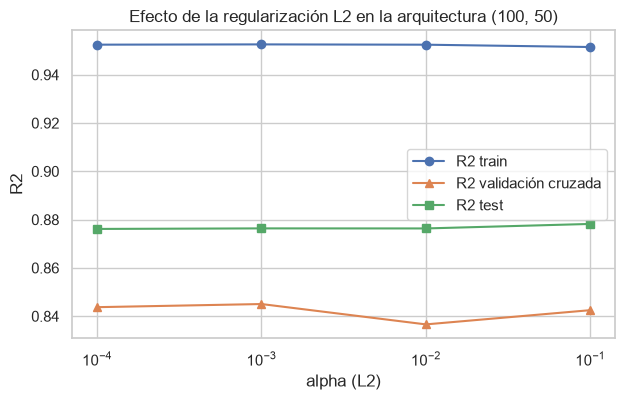

In [32]:
# a) y b) Regularización L2 (alpha) sobre la mejor arquitectura
alphas = [0.0001, 0.001, 0.01, 0.1]
experimentos_alpha = {a: entrenar_mlp(hidden_layer_sizes=mejor_arq, activation="relu", solver="adam",
                                      early_stopping=True, alpha=a) for a in alphas}
tabla_alpha = pd.DataFrame({a: {"R2_cv": r["R2_cv"], "R2_cv_std": r["R2_cv_std"], "R2_test": r["R2"],
                                "R2_train": r["R2_train"], "RMSE_test": r["RMSE"],
                                "loss_final": r["loss_final"], "n_iter": r["n_iter"],
                                "tiempo_entrenamiento_s": r["tiempo_entrenamiento_s"]}
                            for a, r in experimentos_alpha.items()}).T
tabla_alpha.index.name = "alpha"
mostrar_tabla(tabla_alpha)
mejor_alpha = float(tabla_alpha.R2_cv.idxmax())
print(f"Mejor alpha (por R2 de validación cruzada): {mejor_alpha}   [alpha por defecto de sklearn: 0.0001]")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(alphas, tabla_alpha.R2_train, "o-", label="R2 train")
ax.plot(alphas, tabla_alpha.R2_cv, "^-", label="R2 validación cruzada")
ax.plot(alphas, tabla_alpha.R2_test, "s-", label="R2 test")
ax.set_xscale("log"); ax.set_xlabel("alpha (L2)"); ax.set_ylabel("R2")
ax.set_title(f"Efecto de la regularización L2 en la arquitectura {mejor_arq}")
ax.legend()
plt.show()

,R2_cv,R2_cv_std,R2_test,R2_train,RMSE_test,loss_final,n_iter,tiempo_entrenamiento_s,s_por_iteracion,tiempo_relativo_a_adam,s_por_iter_relativo_a_adam
adam,0.8450,0.0417,0.8764,0.9526,30795.3480,0.0095,25.0,1.6053,0.0642,1.0000,1.0000
sgd,0.7925,0.0579,0.8727,0.9094,31249.8712,0.0420,115.0,6.3660,0.0554,3.9657,0.8621
lbfgs,0.8195,0.0731,0.8713,1.0000,31415.5841,0.0001,202.0,9.2194,0.0456,5.7432,0.7108


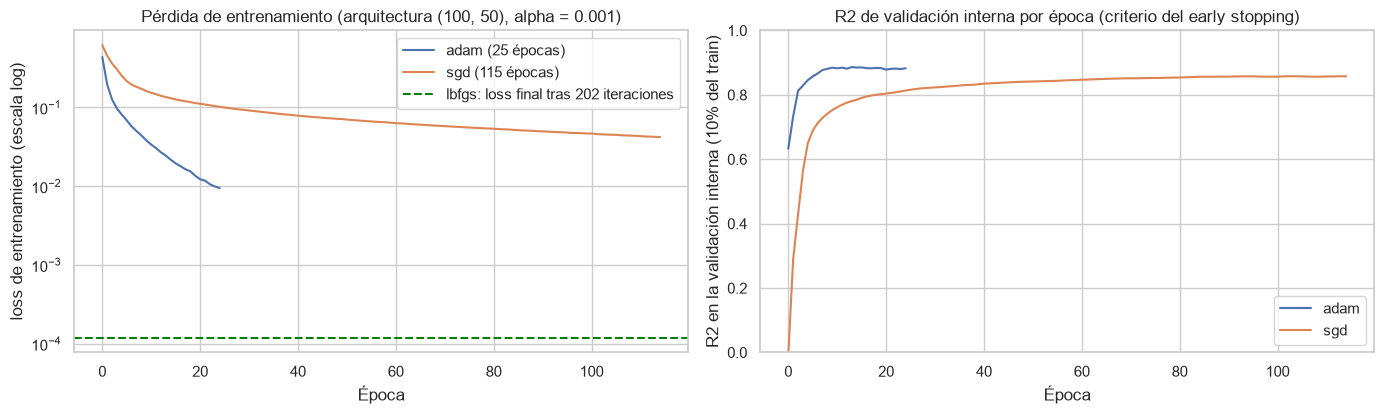

Mejor optimizador por R2 de validación cruzada: adam (R2 CV = 0.8450, R2 prueba = 0.8764)


In [33]:
# c) Comparación de optimizadores con la mejor arquitectura y el mejor alpha
# Nota: early_stopping sólo aplica a los solvers estocásticos (adam, sgd), que reservan el 10% del train como
# validación interna; lbfgs es un método por lotes (cuasi-Newton de memoria limitada) que usa el 100% del train en
# cada iteración y se detiene por tolerancia o max_iter. Esta diferencia (90% vs 100% de los datos) se discute en la respuesta.
configs_solver = {
    "adam": dict(solver="adam", early_stopping=True),
    "sgd": dict(solver="sgd", early_stopping=True),
    "lbfgs": dict(solver="lbfgs", early_stopping=False),
}
experimentos_solver = {s: entrenar_mlp(hidden_layer_sizes=mejor_arq, activation="relu", alpha=mejor_alpha, **cfg)
                       for s, cfg in configs_solver.items()}
tabla_solver = pd.DataFrame({s: {"R2_cv": r["R2_cv"], "R2_cv_std": r["R2_cv_std"], "R2_test": r["R2"],
                                 "R2_train": r["R2_train"], "RMSE_test": r["RMSE"],
                                 "loss_final": r["loss_final"], "n_iter": r["n_iter"],
                                 "tiempo_entrenamiento_s": r["tiempo_entrenamiento_s"],
                                 "s_por_iteracion": r["tiempo_entrenamiento_s"] / r["n_iter"]}
                             for s, r in experimentos_solver.items()}).T
# Razones respecto de adam (los tiempos absolutos dependen de la máquina; las razones son más informativas)
tabla_solver["tiempo_relativo_a_adam"] = tabla_solver.tiempo_entrenamiento_s / tabla_solver.loc["adam", "tiempo_entrenamiento_s"]
tabla_solver["s_por_iter_relativo_a_adam"] = tabla_solver.s_por_iteracion / tabla_solver.loc["adam", "s_por_iteracion"]
mostrar_tabla(tabla_solver)

# d) Velocidad de convergencia: curvas de pérdida y de R2 de validación interna (adam y sgd las registran; lbfgs no)
# Nota: loss_curve_ de adam/sgd es la pérdida media de los mini-lotes de cada época; loss_ de lbfgs es la pérdida
# sobre el lote completo al terminar, así que la comparación de niveles es aproximada.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for s in ["adam", "sgd"]:
    axes[0].plot(experimentos_solver[s]["modelo"].loss_curve_, label=f"{s} ({experimentos_solver[s]['n_iter']} épocas)")
    axes[1].plot(experimentos_solver[s]["modelo"].validation_scores_, label=s)
axes[0].axhline(experimentos_solver["lbfgs"]["loss_final"], color="green", ls="--",
                label=f"lbfgs: loss final tras {experimentos_solver['lbfgs']['n_iter']} iteraciones")
axes[0].set_yscale("log"); axes[0].set_xlabel("Época"); axes[0].set_ylabel("loss de entrenamiento (escala log)")
axes[0].set_title(f"Pérdida de entrenamiento (arquitectura {mejor_arq}, alpha = {mejor_alpha})")
axes[0].legend()
axes[1].set_xlabel("Época"); axes[1].set_ylabel("R2 en la validación interna (10% del train)")
axes[1].set_title("R2 de validación interna por época (criterio del early stopping)")
axes[1].set_ylim(0, 1); axes[1].legend()
plt.tight_layout()
plt.show()

mejor_solver = tabla_solver.R2_cv.idxmax()
mlp_mejor = experimentos_solver[mejor_solver]
print(f"Mejor optimizador por R2 de validación cruzada: {mejor_solver} "
      f"(R2 CV = {mlp_mejor['R2_cv']:.4f}, R2 prueba = {mlp_mejor['R2']:.4f})")

**a) y b) Regularización L2 (`alpha`) sobre la arquitectura (100, 50).**

| `alpha` | R² validación cruzada | R² prueba | R² train | RMSE prueba | `loss_` final (incluye la penalización) |
|---|---|---|---|---|---|
| 0,0001 (defecto) | 0,844 ± 0,042 | 0,876 | 0,953 | \$30.824 | 0,0089 |
| **0,001** | **0,845 ± 0,042** | 0,876 | 0,953 | \$30.795 | 0,0095 |
| 0,01 | 0,837 ± 0,054 | 0,876 | 0,952 | \$30.798 | 0,0147 |
| 0,1 | 0,843 ± 0,056 | 0,878 | 0,952 | \$30.565 | 0,0523 |

El efecto de `alpha` en este rango es **prácticamente nulo**: el R² de prueba se mueve entre 0,876 y 0,878, el de validación cruzada entre 0,837 y 0,845 (variaciones muy inferiores a la desviación entre folds) y el de entrenamiento se mantiene en 0,952-0,953; sólo `loss_` crece, porque incluye el término de penalización. ¿Por qué no influye, si la penalización no es despreciable? En `MLPRegressor` la pérdida de cada lote es MSE/2 + `alpha`/(2·n_lote) · ||W||², con n_lote = 200; con `alpha=0,1` el término de penalización vale ≈ 0,043 de los 0,052 de `loss_` final, es decir, supera al propio error de datos (≈ 0,009). Que aun así el R² no cambie se debe a que el *early stopping* detiene todas las redes en la época 25, cuando los pesos todavía son pequeños y cercanos a su inicialización: la penalización frena ligeramente su crecimiento (el R² de entrenamiento baja de 0,9525 a 0,9515) pero no llega a alterar la función aprendida. El regularizador efectivo es el *early stopping*, no `alpha`. Se conserva **`alpha=0,001`**, el mejor por validación cruzada, aunque la diferencia con el valor por defecto es irrelevante en la práctica; para que L2 cambiara el comportamiento habría que entrenar sin parada temprana o usar valores de `alpha` mucho mayores, con riesgo de subajuste.

**c) y d) Optimizadores** (arquitectura (100, 50), `alpha=0,001`):

| `solver` | R² validación cruzada | R² prueba | R² train | RMSE prueba | `loss_` final | Iteraciones | Tiempo total | Tiempo por iteración |
|---|---|---|---|---|---|---|---|---|
| **adam** | **0,845 ± 0,042** | **0,876** | 0,953 | \$30.795 | 0,0095 | 25 épocas | el menor | referencia |
| sgd | 0,793 ± 0,058 | 0,873 | 0,909 | \$31.250 | 0,0420 | 115 épocas | varias veces el de adam | similar al de adam |
| lbfgs | 0,820 ± 0,073 | 0,871 | 1,000 | \$31.416 | 0,0001 | 202 iteraciones | varias veces el de adam | menor que una época de adam |

(Los tiempos absolutos y las razones exactas respecto de Adam están en las columnas `tiempo_entrenamiento_s`, `tiempo_relativo_a_adam` y `s_por_iter_relativo_a_adam` de la tabla de la celda anterior; varían con la carga de la máquina en cada ejecución, por eso aquí sólo se describe su orden. La pérdida `loss_` de Adam y SGD es la media de los mini-lotes de la última época, y la de L-BFGS la del lote completo, así que la comparación de niveles es aproximada.)

Una precisión metodológica: con `adam` y `sgd`, `early_stopping=True` reserva el 10 % del entrenamiento como validación interna, de modo que esas redes se ajustan con 1051 casas, mientras que `lbfgs` (método por lotes, sin *early stopping*) usa las 1168. La comparación no es perfectamente simétrica, pero refleja cómo se usa cada solver en la práctica y la validación cruzada la reproduce en los cinco folds.

* **¿Cuál converge más rápido?** **Adam**: en épocas (25 frente a 115 de SGD) y en tiempo de reloj (el menor de los tres, varias veces menos que SGD y que L-BFGS según la columna `tiempo_relativo_a_adam`); su curva de pérdida cae casi dos órdenes de magnitud en 25 épocas. SGD con la tasa de aprendizaje constante por defecto (0,001) avanza muy lento: tras 115 épocas su pérdida (0,042) sigue siendo cuatro veces mayor que la de Adam y el *early stopping* lo detiene cuando el R² de validación deja de mejorar, dejándolo **subajustado** (R² train 0,91); necesitaría una tasa mayor o adaptativa para competir. L-BFGS necesita más iteraciones (202) pero cada una cuesta menos que una época de Adam (columna `s_por_iter_relativo_a_adam`) (es un método por lotes, sin el bucle de *mini-batches*), y alcanza la pérdida de entrenamiento más baja con diferencia (0,0001: la red interpola los 1168 precios). Conviene distinguir, eso sí, "converger rápido" de "converger": Adam y SGD se detienen por *early stopping* lejos del mínimo de la pérdida de entrenamiento, y L-BFGS es el único que realmente lo alcanza. El panel derecho de la figura muestra el criterio de parada: el R² de la validación interna de Adam sube hasta ~0,9 en unas 10 épocas y después se estanca aunque la pérdida de entrenamiento siga cayendo, mientras que el de SGD crece lentamente durante más de 100 épocas.
* **¿Cuál alcanza el mejor resultado final?** **Adam**, tanto en validación cruzada (0,845) como en prueba (0,876). L-BFGS es el caso de estudio interesante: ajusta perfectamente el entrenamiento (R² = 1,000) pero generaliza peor (0,820 en validación cruzada, con la mayor dispersión entre folds, y 0,871 en prueba): es **sobreajuste** en estado puro, pues sin *early stopping* y con un `alpha` tan pequeño nada frena a un optimizador de segundo orden en un problema con 35.401 parámetros y 1168 observaciones. SGD queda último por el motivo contrario, el subajuste. Con esto, la mejor red neuronal del trabajo es **(100, 50), `alpha=0,001`, `solver='adam'`**.

__Pregunta 4.4__: Análisis de Predicciones y Comparación (15 puntos)

a) Para el mejor modelo de Red Neuronal (mejor arquitectura, alpha y solver): visualice predicciones vs. valores reales (scatter plot), y grafique el histograma de residuos (errores). ¿Están normalmente distribuidos?

b) Cree una tabla que compare el RMSE y R² en el conjunto de prueba para: Regresión Lineal (de 3.2), el mejor XGBoost (de 3.3) & la mejor Red Neuronal (de 4.4).

c) Considerando la complejidad, tiempo de entrenamiento y performance, ¿qué modelo recomendaría usar en producción para este problema? Justifique.

### Respuesta 4.4:

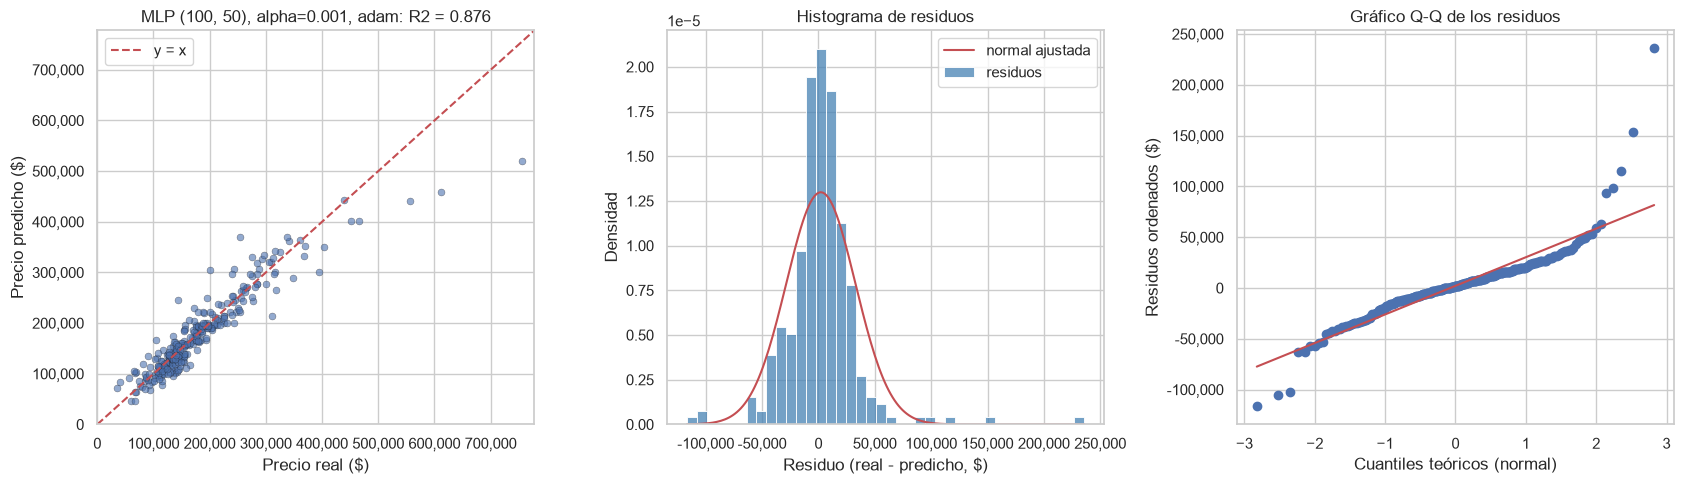

Residuos: media = $2,113, desv. est. = $30,723, asimetría = 1.66, curtosis (exceso) = 14.30
Test de Shapiro-Wilk: W = 0.8370, p-valor = 7.31e-17
Residuos fuera de ±2 desv. est.: 11 de 292 (una normal esperaría ~13)


In [34]:
# a) Mejor red neuronal: predicciones vs. reales e histograma de residuos
pred_nn = mlp_mejor["pred_test"]
residuos = y_test_h.to_numpy() - pred_nn
resultados["MLP mejor"] = {k: v for k, v in mlp_mejor.items() if k not in ("modelo", "pred_test")}
resultados["MLP mejor"]["configuracion"] = f"{mejor_arq}, alpha={mejor_alpha}, solver={mejor_solver}"

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].scatter(y_test_h, pred_nn, alpha=0.6, s=25, edgecolor="k", linewidth=0.3)
lim = [0, max(y_test_h.max(), pred_nn.max()) * 1.03]
axes[0].plot(lim, lim, "r--", label="y = x")
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("Precio real ($)"); axes[0].set_ylabel("Precio predicho ($)")
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}")); axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].set_title(f"MLP {mejor_arq}, alpha={mejor_alpha}, {mejor_solver}: R2 = {mlp_mejor['R2']:.3f}")
axes[0].legend()

sns.histplot(residuos, bins=40, stat="density", ax=axes[1], color="steelblue", label="residuos")
xs = np.linspace(residuos.min(), residuos.max(), 200)
axes[1].plot(xs, stats.norm.pdf(xs, residuos.mean(), residuos.std()), "r-", label="normal ajustada")
axes[1].set_xlabel("Residuo (real - predicho, $)"); axes[1].set_ylabel("Densidad")
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[1].set_title("Histograma de residuos")
axes[1].legend()

stats.probplot(residuos, dist="norm", plot=axes[2])
axes[2].set_title("Gráfico Q-Q de los residuos")
axes[2].set_xlabel("Cuantiles teóricos (normal)"); axes[2].set_ylabel("Residuos ordenados ($)")
axes[2].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.tight_layout()
plt.show()

shapiro = stats.shapiro(residuos)
print(f"Residuos: media = ${residuos.mean():,.0f}, desv. est. = ${residuos.std():,.0f}, "
      f"asimetría = {stats.skew(residuos):.2f}, curtosis (exceso) = {stats.kurtosis(residuos):.2f}")
print(f"Test de Shapiro-Wilk: W = {shapiro.statistic:.4f}, p-valor = {shapiro.pvalue:.2e}")
print(f"Residuos fuera de ±2 desv. est.: {(np.abs(residuos) > 2 * residuos.std()).sum()} de {len(residuos)} "
      f"(una normal esperaría ~{0.0455 * len(residuos):.0f})")

In [35]:
# b) Tabla comparativa en prueba: Regresión Lineal, mejor XGBoost y mejor Red Neuronal
modelos_comparar = {
    "Regresión Lineal (3.2)": "Regresión Lineal",
    "Random Forest Regressor (3.2)": "Random Forest Regressor",
    "XGBoost optimizado (3.3)": "XGBoost optimizado",
    f"Red Neuronal {mejor_arq}, alpha={mejor_alpha}, {mejor_solver} (4.3)": "MLP mejor",
}
tabla_final = pd.DataFrame({etiqueta: {"RMSE": resultados[k]["RMSE"], "R2": resultados[k]["R2"],
                                       "MAE": resultados[k]["MAE"], "R2_train": resultados[k]["R2_train"],
                                       "tiempo_entrenamiento_s": resultados[k]["tiempo_entrenamiento_s"]}
                            for etiqueta, k in modelos_comparar.items()}).T
mostrar_tabla(tabla_final)

,RMSE,R2,MAE,R2_train,tiempo_entrenamiento_s
Regresión Lineal (3.2),65332.1989,0.4435,21105.8986,0.9401,0.3189
Random Forest Regressor (3.2),28911.8089,0.8910,17656.3095,0.9793,0.6192
XGBoost optimizado (3.3),25919.7491,0.9124,15902.4507,0.9999,2.4931
"Red Neuronal (100, 50), alpha=0.001, adam (4.3)",30795.3480,0.8764,19365.5705,0.9526,1.6053


**a) Predicciones vs. reales y residuos de la mejor red ((100, 50); `alpha`=0,001; Adam; R² = 0,876).** El *scatter* muestra una buena alineación con la diagonal en el grueso de la distribución (\$100.000-\$300.000) y, como en los árboles, una **subestimación de las casas más caras** (la de \$755.000 se predice en ~\$520.000, el mayor residuo de todos), además de algunos errores aislados grandes en el rango medio.

**¿Están los residuos normalmente distribuidos? No.** El histograma parece centrado (media \$2.113, es decir, sin sesgo sistemático apreciable; desviación \$30.723), pero:

* la **curtosis en exceso es 14,3** (una normal tiene 0): la distribución es muy apuntada en el centro y tiene **colas pesadas**: hay casas con errores de \$100.000 a \$235.000, es decir, de 3,3 a 7,7 desviaciones estándar, prácticamente imposibles bajo una normal con esa desviación;
* la **asimetría es 1,66**: la cola derecha (casas cuyo precio real supera la predicción) es mucho más larga;
* el gráfico **Q-Q** se separa de la recta en ambos extremos, sobre todo en el derecho;
* el **test de Shapiro-Wilk** rechaza la normalidad contundentemente (W = 0,837, p ≈ 7 × 10⁻¹⁷).

Que el número de residuos fuera de ± 2 desviaciones (11 de 292) sea incluso menor que el esperado bajo normalidad (~13) es engañoso: la no normalidad está en lo extremo de las colas y en el apuntamiento central. En términos prácticos, el modelo es muy preciso para la mayoría de las casas y comete unos pocos errores muy grandes (casas atípicas, muy caras o con características raras), que son los que dominan el RMSE. Modelar `log(SalePrice)` haría los residuos relativos y más simétricos.

**b) Tabla comparativa en el conjunto de prueba.**

| Modelo | RMSE | R² | MAE |
|---|---|---|---|
| Regresión Lineal (3.2) | \$65.332 | 0,444 | \$21.106 |
| Random Forest Regressor (3.2, referencia) | \$28.912 | 0,891 | \$17.656 |
| **XGBoost optimizado (3.3)** | **\$25.920** | **0,912** | **\$15.902** |
| Mejor Red Neuronal (4.3): (100, 50), `alpha`=0,001, Adam | \$30.795 | 0,876 | \$19.366 |

Tanto XGBoost como la red se eligieron por validación cruzada sobre el entrenamiento, de modo que la comparación en prueba es justa para ambos.

**c) Recomendación para producción: XGBoost.** Razones:

1. **Rendimiento:** es el mejor en las tres métricas; su RMSE es un 16 % menor que el de la red neuronal y su MAE ~\$3.500 menor, con un R² de 0,912 frente a 0,876. La variante con *early stopping* (226 árboles) iguala ese rendimiento con menos de la mitad del modelo.
2. **Costo de desarrollo:** el tiempo de ajuste final es de pocos segundos en ambos modelos (la red con Adam incluso algo menos que XGBoost con 500 árboles), así que no es lo que decide; lo que decide es el esfuerzo para llegar a un buen modelo. XGBoost es poco sensible a los hiperparámetros siempre que la tasa de aprendizaje y el número de árboles se compensen (ya el modelo por defecto daba 0,898); la red necesitó explorar arquitectura, regularización y optimizador, sus resultados dependen de la inicialización y de un *early stopping* que puede dispararse antes de tiempo (como ocurrió con (200, 100)), y en todo ese recorrido ninguna configuración superó 0,88.
3. **Complejidad operativa:** XGBoost no requiere escalar las variables ni la variable objetivo, tolera valores faltantes de forma nativa y es **interpretable** con `plot_importance` y SHAP exacto (`TreeExplainer`), algo muy valioso para justificar tasaciones ante usuarios. Una red de 35.401 pesos es una caja negra cuya explicación requiere aproximaciones más costosas.
4. **Robustez:** la curva de *early stopping* mostró que agregar árboles no degrada el error de validación, mientras que la red mostró dos modos de fallo en 4.3 (subajuste con SGD y sobreajuste total con L-BFGS) que hay que vigilar.

La red neuronal sólo sería preferible si el volumen de datos creciera en órdenes de magnitud o si se quisiera integrar información no tabular (imágenes, texto de los anuncios). La regresión lineal queda descartada tal cual (necesitaría regularización y tratamiento de categorías raras) y el Random Forest es una alternativa razonable pero dominada por XGBoost en todas las métricas.

## **PARTE 3: Comparación y Análisis Integral**

__Pregunta 5.1__: Comparación de Métodos de Clasificación (15 puntos)

a) Compare Random Forest y SVM (con PCA) en base a sus experimentos en la Parte 1, en términos de: Accuracy, tiempo de entrenamiento, tiempo de inferencia (predicción), interpretabilidad (¿cuál es más fácil de interpretar y por qué?) & sensibilidad a la preparación de datos (ej. escalamiento, PCA).

b) ¿En qué escenarios (tipo de datos, número de features, necesidad de interpretabilidad) recomendaría usar Random Forest sobre SVM y viceversa?

### Respuesta 5.1:

In [36]:
# Resumen cuantitativo de los experimentos de clasificación (Parte 1)
# Experimento de sensibilidad a la preparación de datos (mismos hiperparámetros óptimos, distinta preparación)
# (el escalador se ajusta con todo el train antes de la CV: misma fuga leve, ya cuantificada en 2.3, que aquí se acepta)
escalador_pca = StandardScaler().fit(X_train_pca)
variantes = {
    "RF optimizado sobre 4096 píxeles crudos (referencia)": (RandomForestClassifier(**grid_rf.best_params_, random_state=SEED, n_jobs=-1), X_train, X_test),
    "RF optimizado sobre las 61 componentes PCA": (RandomForestClassifier(**grid_rf.best_params_, random_state=SEED, n_jobs=-1), X_train_pca, X_test_pca),
    "SVM RBF (C=10, gamma=0.01) sobre PCA (referencia)": (SVC(kernel="rbf", random_state=SEED, **grid_svm.best_params_), X_train_pca, X_test_pca),
    "SVM RBF (C=10, gamma=0.01) sobre PCA estandarizado": (SVC(kernel="rbf", random_state=SEED, **grid_svm.best_params_), escalador_pca.transform(X_train_pca), escalador_pca.transform(X_test_pca)),
    "SVM RBF (C=10, gamma=0.01) sobre 4096 píxeles crudos": (SVC(kernel="rbf", random_state=SEED, **grid_svm.best_params_), X_train, X_test),
    "SVM RBF (C=10, gamma='scale') sobre 4096 píxeles crudos": (SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED), X_train, X_test),
    "SVM lineal (C=1) sobre 4096 píxeles crudos": (SVC(kernel="linear", C=1.0, random_state=SEED), X_train, X_test),
}
filas = []
for nombre, (modelo, Xa, Xb) in variantes.items():
    t_fit = cronometrar(modelo, Xa, y_train)
    filas.append({"variante": nombre, "accuracy_test": accuracy_score(y_test, modelo.predict(Xb)),
                  "accuracy_cv": cross_val_score(modelo, Xa, y_train, cv=cv5).mean(), "tiempo_entrenamiento_s": t_fit})
tabla_sensibilidad = pd.DataFrame(filas).set_index("variante")
mostrar_tabla(tabla_sensibilidad)

claves = ["RF base", "RF optimizado", "SVM lineal (C=1)", "SVM rbf (C=1)", "SVM poly (grado 4) (C=1)", "SVM RBF optimizado"]
tabla_clasif = pd.DataFrame({k: resultados[k] for k in claves}).T[
    ["accuracy_test", "accuracy_cv", "tiempo_entrenamiento_s", "tiempo_prediccion_s", "tiempo_busqueda_s"]]
tabla_clasif["tiempo_prediccion_ms_por_imagen"] = 1000 * tabla_clasif.tiempo_prediccion_s / len(X_test)
mostrar_tabla(tabla_clasif.astype(float))
print(f"Nota: el tiempo de predicción de todos los SVM incluye la proyección PCA (4096 -> {n_90} dimensiones) de las "
      f"100 imágenes de prueba; el tiempo de entrenamiento no incluye el ajuste del PCA, que se hace una sola vez.")

,accuracy_test,accuracy_cv,tiempo_entrenamiento_s
variante,,,
RF optimizado sobre 4096 píxeles crudos (referencia),0.97,0.9200,1.2023
RF optimizado sobre las 61 componentes PCA,0.96,0.9100,0.6502
"SVM RBF (C=10, gamma=0.01) sobre PCA (referencia)",0.96,0.9433,0.0499
"SVM RBF (C=10, gamma=0.01) sobre PCA estandarizado",0.97,0.9367,0.0365
"SVM RBF (C=10, gamma=0.01) sobre 4096 píxeles crudos",0.96,0.9333,0.3166
"SVM RBF (C=10, gamma='scale') sobre 4096 píxeles crudos",0.96,0.9400,0.3779
SVM lineal (C=1) sobre 4096 píxeles crudos,0.98,0.9433,0.2537


,accuracy_test,accuracy_cv,tiempo_entrenamiento_s,tiempo_prediccion_s,tiempo_busqueda_s,tiempo_prediccion_ms_por_imagen
RF base,0.96,0.9033,0.2760,0.0097,NaN,0.0970
RF optimizado,0.97,0.9200,1.0904,0.0450,126.2623,0.4503
SVM lineal (C=1),0.98,0.9333,0.0198,0.0138,NaN,0.1375
SVM rbf (C=1),0.93,0.9167,0.0223,0.0109,NaN,0.1091
SVM poly (grado 4) (C=1),0.49,0.3600,0.0228,0.0111,NaN,0.1109
SVM RBF optimizado,0.96,0.9433,0.0385,0.0161,0.5863,0.1610


Nota: el tiempo de predicción de todos los SVM incluye la proyección PCA (4096 -> 61 dimensiones) de las 100 imágenes de prueba; el tiempo de entrenamiento no incluye el ajuste del PCA, que se hace una sola vez.


**a) Random Forest vs. SVM (con PCA) en la Parte 1.**

| Criterio | Random Forest (píxeles crudos) | SVM + PCA (61 componentes) |
|---|---|---|
| **Accuracy** | Base 0,96; optimizado 0,97 en prueba (CV 0,92) | RBF optimizado 0,96 en prueba (CV 0,943); lineal con C=1: 0,98. Equivalentes en prueba (1 imagen de diferencia); SVM mejor en validación cruzada |
| **Tiempo de entrenamiento** | Del orden de un segundo o menos (100-200 árboles, en paralelo en todos los núcleos); la búsqueda en grilla (270 ajustes) tarda uno o dos minutos | Centésimas de segundo el SVM en sí, entre uno y dos órdenes de magnitud menos que el RF (ver tabla); pero hay que sumar el ajuste del PCA, que se hace una sola vez y cuesta del mismo orden que entrenar un RF, con lo que el costo total de un único entrenamiento es comparable. La ventaja neta está en la búsqueda de hiperparámetros: la grilla completa (80 ajustes) tarda menos de un segundo porque el PCA no se repite |
| **Tiempo de inferencia** (medido con un hilo, 100 imágenes) | Décimas de milisegundo por imagen con 200 árboles (recorrer los árboles sobre 4096 píxeles); menos con 100 árboles | Entre 2 y 3 veces menos que el RF de 200 árboles, incluida la proyección PCA (un producto matricial 4096 x 61 y 287 evaluaciones de kernel en 61 dimensiones), y algo más lento (≈ 1,5-2 veces) que el RF de 100 árboles |
| **Interpretabilidad** | **Mayor.** `feature_importances_` se visualiza directamente como un mapa de píxeles (frente, cejas, ojos, contorno); cada árbol es una secuencia legible de umbrales sobre píxeles; el OOB da diagnóstico gratis | **Menor.** El modelo vive en el espacio de 61 *eigenfaces*; la decisión depende de coeficientes duales sobre 287 vectores de soporte y 780 clasificadores binarios. Se pueden inspeccionar los vectores de soporte (2.3.e) y, para el kernel lineal, proyectar los pesos al espacio de píxeles, pero la explicación es indirecta |
| **Sensibilidad a la preparación** (experimento de la celda anterior) | **Baja.** Invariante a transformaciones monótonas de cada píxel (no necesita escalar) y funciona sobre los 4096 píxeles crudos. Entrenarlo sobre las 61 componentes PCA en lugar de los píxeles no cambia apreciablemente el resultado (0,91 vs 0,92 en validación cruzada, con desviaciones de ≈ 0,02; 0,96 vs 0,97 en prueba, una imagen): el PCA no lo ayuda, pero tampoco lo perjudica de forma medible | **Moderada en este dataset, alta en general.** El SVM depende de distancias y productos internos, así que las variables deben compartir escala; aquí los píxeles ya están todos en [0, 1], y por eso ni estandarizar las componentes PCA (0,937 vs 0,943 en validación cruzada) ni prescindir del PCA (0,933-0,943 sobre los 4096 píxeles) cambian el accuracy más de un punto. Lo que el PCA aporta es **velocidad**: el SVM sobre píxeles crudos tarda varias veces más en entrenar (entre 6 y 20 veces según la corrida). Donde sí es muy sensible es en los hiperparámetros del kernel: `gamma=1` o `C=0.1` lo llevan al nivel del azar, y el kernel polinomial pasó de 0,49 a 0,97 por un solo parámetro (`coef0`) |

El experimento de sensibilidad (tabla de la celda anterior) resume estas conclusiones con los hiperparámetros óptimos de cada modelo: el RF obtiene prácticamente lo mismo con píxeles crudos que con PCA (diferencias dentro del ruido); el SVM obtiene prácticamente lo mismo con PCA, con PCA estandarizado o con los píxeles crudos (0,933-0,943 en validación cruzada; el lineal sobre píxeles crudos iguala al RBF optimizado con 0,943), y el PCA sólo le cambia el costo computacional. La fama de "sensible a la preparación" del SVM se refiere sobre todo a datasets con variables de escalas heterogéneas, que no es el caso de las imágenes normalizadas.

**b) ¿Cuándo usar uno u otro?**

* **Random Forest** cuando: los datos son **tabulares heterogéneos** (mezcla de numéricas y categóricas, escalas distintas, valores faltantes, *outliers*), se necesita un buen resultado **sin preparación ni ajuste fino**, se requiere **interpretabilidad** (importancias, reglas), hay interacciones no lineales entre variables, el número de muestras es grande (escala casi linealmente con n y se paraleliza bien) o se quiere una estimación de error gratuita (OOB). También cuando el número de características es moderado o la mayoría son relevantes.
* **SVM** cuando: los datos son de **alta dimensión con pocas muestras** (texto, imágenes vectorizadas, genómica), donde las clases tienden a ser linealmente separables y el margen máximo generaliza muy bien (como aquí: 0,98 con kernel lineal); las variables son **homogéneas y continuas** (píxeles, *embeddings*, señales) y se pueden escalar sin problema; se necesita un modelo compacto y una inferencia muy rápida; o cuando se requiere una frontera suave y no lineal en dimensión baja o media mediante el kernel RBF. En cambio, el SVM con kernel deja de ser práctico cuando n supera unas decenas de miles de muestras (la matriz de kernel crece como n²) y es poco interpretable; en esos casos se recurre a un SVM lineal o a árboles.

__Pregunta 5.2__: Comparación de Métodos de Regresión (15 puntos)

a) Compare XGBoost y Redes Neuronales (MLP) en base a sus experimentos en la Parte 2, en términos de: R² Score, tiempo y facilidad de optimización de hiperparámetros, requerimientos de preparación de datos (categóricos, escalamiento, etc.) & interpretabilidad (ej. SHAP vs. pesos de la red).

b) ¿Cuál método le pareció más robusto al sobreentrenamiento? Justifique con evidencia de sus experimentos (ej. curvas de validación, efecto de regularización).

### Respuesta 5.2:

In [37]:
# Resumen cuantitativo de los experimentos de regresión (Parte 2)
# Tiempo total invertido en las redes: ajuste final + validación cruzada (5 folds) de cada uno de los 14 entrenamientos (11 configuraciones distintas)
t_total_mlp = sum(r["tiempo_entrenamiento_s"] + r["tiempo_cv_s"]
                  for exp in (experimentos_arq, experimentos_alpha, experimentos_solver) for r in exp.values())
t_total_mlp += mlp_base["tiempo_entrenamiento_s"] + mlp_base["tiempo_cv_s"]
n_ajustes_mlp = len(experimentos_arq) + len(experimentos_alpha) + len(experimentos_solver) + 1
# Configuraciones DISTINTAS: (64,) se entrena en 4.1 y 4.2; alpha=0.0001 coincide con la arquitectura base; adam con el mejor alpha
configs_distintas = {(str(a), 0.0001, "adam") for a in arquitecturas}
configs_distintas |= {(str(mejor_arq), a, "adam") for a in alphas}
configs_distintas |= {(str(mejor_arq), mejor_alpha, sol) for sol in configs_solver}
n_exp_mlp = len(configs_distintas)
print(f"Redes entrenadas (ajuste final): {n_ajustes_mlp}; configuraciones distintas: {n_exp_mlp}")
resumen_reg = pd.DataFrame({
    "XGBoost": {"R2_test (default)": resultados["XGBoost default"]["R2"],
                "R2_test (mejor)": resultados["XGBoost optimizado"]["R2"],
                "R2_train (mejor)": resultados["XGBoost optimizado"]["R2_train"],
                "RMSE_test (mejor)": resultados["XGBoost optimizado"]["RMSE"],
                "configuraciones distintas probadas": busqueda_xgb.n_iter, "tiempo total de búsqueda (s)": t_busqueda_xgb,
                "tiempo entrenamiento modelo final (s)": resultados["XGBoost optimizado"]["tiempo_entrenamiento_s"]},
    "Red Neuronal (MLP)": {"R2_test (default)": resultados["MLP (64,)"]["R2"],
                           "R2_test (mejor)": resultados["MLP mejor"]["R2"],
                           "R2_train (mejor)": resultados["MLP mejor"]["R2_train"],
                           "RMSE_test (mejor)": resultados["MLP mejor"]["RMSE"],
                           "configuraciones distintas probadas": n_exp_mlp, "tiempo total de búsqueda (s)": t_total_mlp,
                           "tiempo entrenamiento modelo final (s)": resultados["MLP mejor"]["tiempo_entrenamiento_s"]},
})
mostrar_tabla(resumen_reg, 3)

Redes entrenadas (ajuste final): 14; configuraciones distintas: 11


,XGBoost,Red Neuronal (MLP)
R2_test (default),0.898,0.877
R2_test (mejor),0.912,0.876
R2_train (mejor),1.000,0.953
RMSE_test (mejor),25919.749,30795.348
configuraciones distintas probadas,25.000,11.000
tiempo total de búsqueda (s),414.467,82.735
tiempo entrenamiento modelo final (s),2.493,1.605


**a) XGBoost vs. Redes Neuronales (MLP) en la Parte 2.**

| Criterio | XGBoost | MLP |
|---|---|---|
| **R² en prueba** | 0,898 por defecto; **0,912** optimizado (RMSE \$25.920); R² de validación cruzada 0,869 | 0,877 con (64,); **0,876** con la configuración elegida por validación cruzada (RMSE \$30.795); R² de validación cruzada 0,845. Ninguna de las 11 configuraciones de red probadas superó 0,88 en prueba |
| **Tiempo y facilidad de optimización** | 25 configuraciones × 5 folds, el mayor costo de cómputo del trabajo (varios minutos), pero muy **fácil**: pocos hiperparámetros con efecto predecible (árboles × tasa de aprendizaje, profundidad, submuestreo), el modelo por defecto ya es bueno y las mejores 8 configuraciones difieren en menos de 0,02 de R². El *early stopping* fija `n_estimators` automáticamente | 11 configuraciones distintas (14 entrenamientos, algunos repetidos entre preguntas) × (ajuste final + 5 folds) en una fracción del tiempo de XGBoost, pero **difícil**: el espacio es mucho mayor (arquitectura, activación, `alpha`, solver, tasa de aprendizaje, tamaño de lote, criterio de parada), las diferencias entre configuraciones (0,80-0,85 en validación cruzada) son del orden de la dispersión entre folds (± 0,04-0,09), y el resultado depende de la semilla y del *early stopping* (la red (200, 100) perdió 3,5 puntos de R² en prueba por detenerse en la época 15). Hubo que probar tres solvers para descubrir que SGD subajusta y L-BFGS sobreajusta; `alpha` no tuvo efecto |
| **Preparación de datos** | **Mínima**: no necesita escalar X ni y, maneja faltantes de forma nativa y puede consumir categóricas directamente (`enable_categorical`); aquí usó el mismo *one-hot* sólo por compartir el pipeline | **Exigente**: imputación obligatoria, estandarización de X imprescindible para que Adam/SGD converjan, **estandarización de y** (sin ella, R² = −3,6 en 4.1) y codificación *one-hot* de 43 categóricas, lo que infla la entrada a 302 variables y los pesos de la primera capa |
| **Interpretabilidad** | **Alta**: importancias por `gain`, y sobre todo **SHAP exacto y rápido** con `TreeExplainer` (3.4), que entregó efectos por variable y por casa, formas funcionales (calidad convexa, superficie lineal) e interacciones | **Baja**: 35.401 pesos distribuidos en 2 capas ocultas no tienen lectura directa; explicar una predicción exige métodos aproximados y lentos (`KernelExplainer`, gradientes) y las interacciones quedan implícitas |

**b) ¿Cuál es más robusto al sobreajuste? XGBoost**, con evidencia de los experimentos:

1. **Curvas del *early stopping* (3.3.d):** el RMSE de sub-entrenamiento siguió bajando hasta ~\$2.000 mientras que el de validación se mantuvo **plano en ~\$25.000 desde el árbol ~100 hasta el 275**, y el modelo con 500 árboles (0,912) rindió igual que el de 226 (0,913). Es decir, añadir capacidad (árboles) **no degradó** la generalización: el *shrinkage* (`learning_rate=0.1`), el submuestreo (0,7) y la profundidad limitada (5) controlan la varianza aunque el R² de entrenamiento sea 0,9999.
2. **Estabilidad frente a hiperparámetros:** salvo las tres configuraciones que no alcanzaron a converger (`learning_rate=0.01` con 100 árboles), todas las demás quedaron entre 0,80 y 0,87 de R² en validación, y el modelo por defecto obtuvo 0,898 en prueba.
3. **En la red:** la brecha train/test fue de 0,08-0,10 en todas las arquitecturas que entrenaron normalmente (0,953 vs 0,876 en la elegida), similar en magnitud a la de XGBoost (0,9999 vs 0,912), así que la brecha por sí sola no distingue a los dos modelos. La diferencia está en **de qué depende** esa brecha: en la red la **regularización L2 no tuvo efecto** en ningún valor de `alpha`, y la generalización dependió por completo del *early stopping* (la curva de R² de validación interna de 4.3 se estanca en ~0,9 a las 10 épocas mientras la pérdida de entrenamiento sigue cayendo): cuando se retiró (L-BFGS) la red interpoló el entrenamiento (R² train = 1,000) y su R² de validación cruzada cayó de 0,845 a 0,820, con la mayor dispersión entre folds; y cuando el *early stopping* se disparó antes de tiempo ((200, 100)) costó 3,5 puntos en prueba. En XGBoost, en cambio, quitar el *early stopping* (modelo de 500 árboles) no cambió nada, y ninguna configuración razonable degradó el resultado.

En síntesis: ambos modelos memorizan el conjunto de entrenamiento con brechas train/test parecidas, pero XGBoost mantiene su error de validación estable **sin depender de un mecanismo externo** (su control de varianza está en el *shrinkage*, el submuestreo y la profundidad) y con un rendimiento casi insensible a los hiperparámetros razonables, mientras que la red sólo generaliza bien si el *early stopping* actúa en el momento justo. Eso es lo que en la práctica entendemos por robustez al sobreajuste.

__Pregunta 5.3__: Trade-offs y Recomendaciones (20 puntos)

a) Para cada uno de los 4 algoritmos estudiados (RF, SVM, XGBoost & NN), identifique su principal fortaleza y su principal debilidad según lo observado en este trabajo.

b) Caso de Estudio: Un cliente necesita desarrollar un sistema de clasificación de documentos de texto con las siguientes características: ~50,000 documentos de entrenamiento, ~30,000 variables independientes (tras aplicar TF-IDF) & 100 categorías posibles. El cliente valora la interpretabilidad (quiere saber por qué un documento fue clasificado de cierta manera), y tiene restricciones computacionales moderadas (ej. no puede entrenar por semanas). ¿Qué algoritmo(s), de los 4 estudiados, recomendaría y por qué? Justifique su respuesta.

### Respuesta 5.3:

**a) Principal fortaleza y debilidad de cada algoritmo, según lo observado.**

| Algoritmo | Principal fortaleza observada | Principal debilidad observada |
|---|---|---|
| **Random Forest** | Funciona muy bien **sin preparación ni ajuste** (0,96 con los valores por defecto sobre 4096 píxeles crudos; 0,891 de R² en Ames) y es **interpretable** (mapa de importancias por píxel, OOB gratis). No sobreajusta por añadir árboles (curva de validación plana desde ~120 árboles) | Es el más **lento** de los clasificadores (grilla de uno o dos minutos frente a menos de un segundo del SVM; inferencia 2-3 veces más lenta con 200 árboles) y como regresor **no extrapola** (subestima sistemáticamente las casas más caras) y quedó por debajo de XGBoost |
| **SVM** | **Máxima eficiencia y precisión en alta dimensión con pocas muestras**: una vez calculado el PCA, entrena en centésimas de segundo y alcanza 0,96-0,98 en prueba y 0,943 en validación cruzada, el mejor valor del trabajo (empatado con el SVM lineal sobre píxeles crudos de 5.1); el kernel lineal con `C=1` ya es competitivo sin ninguna búsqueda | **Muy sensible a los hiperparámetros del kernel**: `gamma=1` o `C=0.1` lo llevan al nivel del azar, y el kernel polinomial pasó de 0,49 a 0,97 por un solo parámetro (`coef0`); exige variables en una escala común (aquí los píxeles ya la tienen, por eso en 5.1 ni el PCA ni la estandarización cambiaron el accuracy más de un punto). Poco interpretable y no escala a muchas muestras (costo entre O(n²) y O(n³)) |
| **XGBoost** | **Mejor rendimiento en regresión (R² 0,912) con la menor fricción**: sin escalar, robusto a los hiperparámetros y al número de árboles (curva de validación plana), *early stopping* integrado y **SHAP exacto** para interpretarlo | La búsqueda de hiperparámetros es la más **costosa en tiempo** (minutos para 125 ajustes) y el modelo **memoriza el entrenamiento** (R² train 0,9999), por lo que requiere validación cuidadosa; en problemas multiclase su costo crece con el número de clases (un árbol por clase y por ronda; no se observó aquí, pero es relevante para el caso de estudio) |
| **Red Neuronal (MLP)** | **Flexibilidad y rapidez de entrenamiento**: con Adam converge en ~25 épocas y pocos segundos, alcanza 0,876-0,878 de R² con casi cualquier arquitectura razonable, y su capacidad se puede escalar a voluntad (profundidad, anchura, otros tipos de entrada) | **Fragilidad y costo de puesta a punto**: exige escalar X e y (sin escalar y, R² = −3,6), imputar y codificar; el resultado depende de arquitectura, solver, semilla y *early stopping* (una parada prematura costó 3,5 puntos; SGD subajustó; L-BFGS sobreajustó hasta R² train = 1,0); la regularización L2 no ayudó; fue el peor de los tres modelos no lineales (0,876 frente a 0,891 del RF y 0,912 de XGBoost) y es una **caja negra** |

**b) Caso de estudio: clasificación de ~50.000 documentos, ~30.000 variables TF-IDF, 100 categorías, interpretabilidad requerida y cómputo moderado.**

Recomendación principal: **SVM con kernel lineal** (`LinearSVC` o `SGDClassifier` con pérdida *hinge*, uno-contra-el-resto), por estas razones:

1. **La naturaleza de los datos es la del escenario ideal del SVM lineal.** Las matrices TF-IDF son de muy alta dimensión, dispersas y, como vimos en Olivetti (el kernel lineal con `C=1` alcanzó 0,98 en prueba y 0,933 en validación cruzada con 61 dimensiones y 300 muestras, a la par del RBF optimizado), en alta dimensión las clases tienden a ser linealmente separables: la frontera de margen máximo generaliza muy bien y no hace falta un kernel no lineal. Los SVM lineales son el estándar en clasificación de texto desde Joachims (1998).
2. **Costo computacional moderado.** Un `LinearSVC` se entrena en tiempo casi lineal en el número de entradas no nulas, explota la dispersión y no necesita construir una matriz de kernel; con 50.000 x 30.000 dispersa, 100 clasificadores binarios se entrenan en minutos en una máquina corriente, y la inferencia es un producto escalar por clase. Un SVM con kernel RBF, en cambio, sería muy costoso: aunque libsvm no materializa la matriz de kernel completa (50.000² = 2,5 × 10⁹ entradas), su costo crece entre O(n²) y O(n³) con el número de documentos y habría que repetirlo para cada combinación de `gamma` y `C` como en 2.3, lo que choca con la restricción de cómputo moderado y no aporta precisión en datos que ya son separables linealmente.
3. **Interpretabilidad directa, a nivel de documento.** El modelo lineal tiene un vector de pesos por categoría sobre el vocabulario: los términos con mayor peso positivo describen cada categoría, y para un documento concreto la contribución de cada palabra es simplemente `peso x tf-idf`, de modo que se puede mostrar "este documento fue asignado a *Deportes* porque contiene *gol*, *árbitro* y *liga*", que es exactamente lo que el cliente pide. Es una explicación exacta, no una aproximación.

Como **complemento o alternativa**, **XGBoost** (o Random Forest) sobre las mismas características dispersas, idealmente tras una selección de términos (χ²) a unos pocos miles: captura interacciones entre palabras y ofrece explicaciones por documento con SHAP, como vimos en 3.4. Su limitación en este caso es el costo: XGBoost multiclase construye un árbol por clase y por iteración (100 árboles por ronda), y sobre 30.000 variables dispersas resulta considerablemente más lento que el SVM lineal, aunque sigue siendo factible en horas. El Random Forest es más barato que XGBoost pero suele rendir peor en texto disperso, donde cada árbol ve sólo √30.000 ≈ 173 términos candidatos por *split*, en su mayoría irrelevantes.

Se **descarta la red neuronal (MLP)**: una primera capa de 30.000 entradas × cientos de neuronas supone millones de pesos; es entrenable en CPU, pero exige el mayor esfuerzo de ajuste de hiperparámetros de los cuatro métodos (como se vio en las preguntas 4.2 y 4.3), su rendimiento con pocos datos por clase (500 documentos por categoría en promedio) no suele superar al SVM lineal en texto tipo *bolsa de palabras*, y es la opción menos interpretable, cuando la interpretabilidad es el requisito explícito del cliente. Y se descarta el SVM con kernel no lineal por el costo ya explicado.

En síntesis: **SVM lineal como sistema principal** (precisión, velocidad y explicaciones exactas por palabra) y, si se dispone de tiempo adicional de cómputo, un **XGBoost con SHAP** como segunda opinión para capturar interacciones y ofrecer explicaciones complementarias.

## Criterios de Evaluación

### Distribución de Puntos

| Parte                                             | Puntos  | Porcentaje |
| ------------------------------------------------- | ------- | ---------- |
| Parte 1: Random Forest (1.1 a 1.4)                | 100      | 20%        |
| Parte 2: SVM (2.1 a 2.3)                          | 100      | 20%        |
| Parte 3: XGBoost (3.1 a 3.4)                      | 100      | 20%        |
| Parte 4: Neural Networks (4.1 a 4.4)              | 100      | 20%        |
| Parte 5: Análisis Integral (5.1 a 5.3)            | 50      | 10%        |
| Calidad del código y documentación                | 50      | 10%        |
| **TOTAL**                                         | **500** | **100%**   |

## ¡Buena suerte! 🙌